# <p style="text-align: center">Анализ реакций, комментариев и пересылок в телеграм канале Артемия Лебедева</p>
<div style="text-align: center"><i>Для анализа был выбран телеграм-канал дизайнера и предпринимателя Артемия Лебедева @temalebedev. Выгрузка из Telegram получена с помощью бесплатного API-ключа. 2279 постов с 1 октября 2024 по 30 сентября 2026 года</i></div>

**Задача.** Выяснить, что в постах канала связано с откликом читателей (реакциями, комментариями и пересылками), чтобы понять, какие посты вовлекают аудиторию сильнее.

**Этапы исследования.**
1. Посты выгружены через Telegram API (`scripts/01_fetch.py`) и разделены по содержанию на пять типов: реклама, посты о собственных продуктах, ссылки на видео, авторские размышления с заголовком и прочие посты (`scripts/02_clean.py`).  

2. Для каждого поста посчитаны признаки: время публикации, длина текста, наличие вопроса в тексте, наличие мата в тексте, тема поста.  

3. Берутся группы постов с разными значениями одного признака (например, с вопросом в тексте и без). У них сравниваются медианы зависимых переменных (реакций, комментариев и пересылок на 1000 просмотров) с 95%-ными доверительными интервалами, посчитанными с помощью bootstrap. Некоторые признаки оказались связаны между собой: например, в 15:05 выходят более короткие тексты, и по сравнению медиан нельзя понять, с чем связана разница в реакциях, со временем или с длиной. Поэтому следующим шагом идёт модель.  

4. Отрицательная биномиальная регрессия оценивает все признаки одновременно. Эффекты ищутся на первых 70% постов и подтверждаются на последних 30% с поправкой Бенджамини–Хохберга.

**Главные результаты**  
 
*Числа ниже - это разница в процентах между постами с определённым признаком и без него. Метрики посчитаны на 1000 просмотров, остальные признаки при сравнении одинаковые. Каждый эффект оценён дважды: на постах до 27 февраля 2026 года и на более поздних постах, где он проверялся. Диапазон — от меньшей до большей из двух оценок. Результаты показывают связь признака с откликом читателей, но не доказывают, что признак его вызывает.*  

- Больше всего реакций собирают размышления — авторские тексты с заголовком, без ссылок. У постов с видео реакций на 68–70% меньше, у рекламы на 19–54% меньше. Отрицательных реакций у рекламы в 2–3,2 раза больше, чем у размышлений.  

- Размышления с вопросом в тексте комментируют на 44–46% чаще.  

- Размышления, опубликованные в 19:05, комментируют на 24–28% чаще, чем опубликованные в 11:05.  

- Короткие размышления (до 414 символов) собирают на 11% меньше реакций, чем средние, на обоих периодах.  

- Связь дня недели, выходных и темы поста с реакцией аудитории не подтвердилась.  

- С 8 марта по 5 октября 2025 года, когда комментарии были платными, комментариев на 1000 просмотров было в 6,5 раза меньше, чем до введения платы, а реакций столько же.

Подробные выводы — в разделе «Выводы» в конце ноутбука.


### Setup

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
from IPython.display import display, Markdown

# Стиль графиков: шрифт PT Serif (если его нет — Charter или стандартный DejaVu Serif), розово-фиолетово-мятная палитра
PALETTE = ["#8E7CC3", "#DB95BD", "#7FCDBB", "#F6D186", "#8EC5E8", "#5E548E", "#F2B5D4"]
plt.rcParams.update({
    "font.family": ["PT Serif", "Charter", "DejaVu Serif"],
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titlelocation": "left",
    "axes.titlepad": 12,
    "axes.prop_cycle": cycler(color=PALETTE),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#888888",
    "axes.grid": True,
    "grid.color": "#E5E5E5",
    "xtick.color": "#555555",
    "ytick.color": "#555555",
    "legend.frameon": False,
    "figure.dpi": 110,
    "figure.facecolor": "white",
})

## Исходная выгрузка

In [2]:
df = pd.read_parquet("data/raw_api.parquet")
df["date_msc"] = df["date_utc"].dt.tz_convert("Europe/Moscow")
df["reactions"] = df["reactions"].map(json.loads)
df["reactions_total"] = df["reactions"].map(lambda d: sum(d.values()))

df.info()
df.drop(columns="text").head(10)  # без текста: в нём мат, а mask_swear определена ниже

<class 'pandas.DataFrame'>
RangeIndex: 2638 entries, 0 to 2637
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype                        
---  ------            --------------  -----                        
 0   id                2638 non-null   int64                        
 1   date_utc          2638 non-null   datetime64[us, UTC]          
 2   text              2638 non-null   str                          
 3   media             2638 non-null   str                          
 4   grouped_id        278 non-null    float64                      
 5   views             2638 non-null   int64                        
 6   forwards          2638 non-null   int64                        
 7   replies           2415 non-null   float64                      
 8   comments_enabled  2638 non-null   bool                         
 9   reactions         2638 non-null   object                       
 10  is_forward        2638 non-null   bool                         
 11  ed

,id,date_utc,media,grouped_id,views,forwards,replies,comments_enabled,reactions,is_forward,edit_date_utc,n_links,date_msc,reactions_total
0,11366,2026-10-09 16:05:00+00:00,text,NaN,20717,122,77.0,True,"{'👎': 136, '❤': 123, '😁': 113, '👍': 49, '💯': 2...",False,2026-10-09 16:05:13+00:00,0,2026-10-09 19:05:00+03:00,476
1,11365,2026-10-09 12:05:00+00:00,text,NaN,28693,29,40.0,True,"{'👍': 177, '😁': 93, '❤': 56, '🍾': 10, '🎃': 6, ...",False,2026-10-09 12:05:17+00:00,0,2026-10-09 15:05:00+03:00,363
2,11364,2026-10-09 08:00:00+00:00,photo,NaN,44717,134,52.0,True,"{'🔥': 152, '👏': 120, '👍': 114, '❤': 109, '🎉': ...",False,2026-10-09 08:00:13+00:00,2,2026-10-09 11:00:00+03:00,659
3,11363,2026-10-09 06:06:50+00:00,photo,NaN,35383,91,22.0,True,"{'❤': 109, '👍': 40, '💩': 13, '👏': 6, '😘': 6, '...",False,2026-10-09 06:07:22+00:00,4,2026-10-09 09:06:50+03:00,183
4,11361,2026-10-08 16:05:00+00:00,text,NaN,43710,86,66.0,True,"{'paid_star': 3, '❤': 372, '😁': 151, '👍': 114,...",False,2026-10-08 16:10:03+00:00,0,2026-10-08 19:05:00+03:00,762
5,11360,2026-10-08 12:05:00+00:00,text,NaN,45692,204,51.0,True,"{'❤': 226, '👍': 98, '🥱': 22, '💯': 21, '🤔': 13,...",False,2026-10-08 12:05:37+00:00,0,2026-10-08 15:05:00+03:00,406
6,11359,2026-10-08 08:05:00+00:00,photo,NaN,47111,64,56.0,True,"{'paid_star': 3, '❤': 289, '👍': 94, '🔥': 48, '...",False,2026-10-08 12:07:46+00:00,0,2026-10-08 11:05:00+03:00,526
7,11358,2026-10-07 16:00:01+00:00,text,NaN,61706,26,19.0,True,"{'paid_star': 1, '💩': 255, '❤': 155, '👍': 125,...",False,2026-10-07 16:07:50+00:00,7,2026-10-07 19:00:01+03:00,884
8,11357,2026-10-07 12:05:00+00:00,text,NaN,50780,42,42.0,True,"{'❤': 220, '💯': 173, '👍': 85, '💩': 23, '🤡': 7,...",False,2026-10-07 12:05:11+00:00,0,2026-10-07 15:05:00+03:00,535
9,11356,2026-10-07 08:05:00+00:00,text,NaN,51502,38,214.0,True,"{'paid_star': 4, '🔥': 236, '🤣': 106, '❤': 68, ...",False,2026-10-07 08:57:16+00:00,0,2026-10-07 11:05:00+03:00,460


In [3]:
# Пропуски в нумерации сообщений внутри окна анализа. Номер, которого нет в выгрузке, принадлежал удалённому
# сообщению или сервисному сообщению (закреп, смена фото): их скрипт выгрузки отбрасывает, не сохраняя номера.
# Какие сообщения пропали, по выгрузке узнать нельзя: время и тип соседних постов — косвенный признак.
gap_posts = pd.read_parquet("data/posts.parquet")[["id", "grouped_id", "content_type"]]
gap_win = df[(df["date_msc"] >= pd.Timestamp("2024-10-01", tz="Europe/Moscow"))
             & (df["date_msc"] < pd.Timestamp("2026-10-01", tz="Europe/Moscow"))]
known = set(df["id"])
missing = [i for i in range(gap_win["id"].min(), gap_win["id"].max() + 1) if i not in known]

# Подряд идущие пропущенные номера — один пропуск
runs = []
for i in missing:
    if runs and runs[-1][1] == i - 1:
        runs[-1][1] = i
    else:
        runs.append([i, i])

# Тип поста для сообщения выгрузки: у альбома тип записан на посте альбома
msg = df.set_index("id")
type_by_id = gap_posts.set_index("id")["content_type"]
type_by_album = gap_posts.dropna(subset=["grouped_id"]).set_index("grouped_id")["content_type"]


def msg_type(r):
    return type_by_album[r["grouped_id"]] if pd.notna(r["grouped_id"]) else type_by_id[r.name]


def empty_slots(t0, t1):
    """Слоты 11:05, 15:05, 19:05 строго между двумя постами: в них не вышло ни одного поста."""
    out = []
    for day in pd.date_range(t0.normalize(), t1.normalize(), freq="D"):
        for h in (11, 15, 19):
            t = day + pd.Timedelta(hours=h, minutes=5)
            if t0 + pd.Timedelta(minutes=1) < t < t1 - pd.Timedelta(minutes=1):
                out.append(f"{t:%H:%M}")
    return ", ".join(out)


gap_rows = []
for a, b in runs:
    prev, nxt = msg.loc[a - 1], msg.loc[b + 1]
    gap_rows.append({
        "номера": str(a) if a == b else f"{a}–{b}", "пропущено номеров": b - a + 1,
        "квартал": prev["date_msc"].tz_localize(None).to_period("Q").strftime("%Y-Q%q"),
        "пост до": f"{prev['date_msc']:%Y-%m-%d %H:%M}", "тип до": msg_type(prev),
        "пост после": f"{nxt['date_msc']:%Y-%m-%d %H:%M}", "тип после": msg_type(nxt),
        "часов между": round((nxt["date_msc"] - prev["date_msc"]).total_seconds() / 3600, 1),
        "внутри альбома": pd.notna(prev["grouped_id"]) and prev["grouped_id"] == nxt["grouped_id"],
        "сосед в :00–:04": prev["date_msc"].minute <= 4 or nxt["date_msc"].minute <= 4,
        "пустые слоты между": empty_slots(prev["date_msc"], nxt["date_msc"]),
    })
gaps = pd.DataFrame(gap_rows)
print(f"Пропущенных номеров: {len(missing)}, пропусков (подряд идущие номера вместе): {len(gaps)}")

display(Markdown("**Пропуски по кварталам**"))
display(gaps.groupby("квартал").agg(**{"пропущено номеров": ("пропущено номеров", "sum"),
                                       "пропусков": ("номера", "size"),
                                       "сосед в :00–:04": ("сосед в :00–:04", "sum"),
                                       "внутри альбома": ("внутри альбома", "sum")}).T)

display(Markdown("**Пропуски рядом с рекламным временем.** Косвенный признак: какие посты удалены, мы не знаем. "
                 "«Сосед в :00–:04» — пост до или после пропуска вышел в :00–:04 минут часа, когда обычно выходит реклама"))
print(f"Пропусков с соседом в :00–:04: {gaps['сосед в :00–:04'].sum()} из {len(gaps)}")
print("Типы соседей таких пропусков: "
      + str(pd.concat([gaps.loc[gaps["сосед в :00–:04"] & (gaps["пост до"].str[-2:].astype(int) <= 4), "тип до"],
                       gaps.loc[gaps["сосед в :00–:04"] & (gaps["пост после"].str[-2:].astype(int) <= 4), "тип после"]])
            .value_counts().to_dict()))
print(f"Пропусков, между соседями которых есть пустой слот 11:05, 15:05 или 19:05: {(gaps['пустые слоты между'] != '').sum()}")
print("Пустые слоты: " + str(gaps["пустые слоты между"].str.split(", ").explode().replace("", np.nan).dropna()
                            .value_counts().to_dict()))

# Для сравнения: соседние посты без пропуска номеров между ними (сообщения альбома считаются одним постом)
seq = gap_win[gap_win["grouped_id"].isna() | ~gap_win.duplicated("grouped_id")].sort_values("id")
pairs = pd.DataFrame({"t0": seq["date_msc"].to_numpy()[:-1], "t1": seq["date_msc"].to_numpy()[1:],
                      "id0": seq["id"].to_numpy()[:-1], "id1": seq["id"].to_numpy()[1:]})
gap_ids = set(missing)
pairs["пропуск"] = [any(i in gap_ids for i in range(a + 1, b)) for a, b in zip(pairs["id0"], pairs["id1"])]
pairs["пустой слот"] = [empty_slots(pd.Timestamp(a), pd.Timestamp(b)) != "" for a, b in zip(pairs["t0"], pairs["t1"])]
display(Markdown("**Доля пар соседних постов с пустым слотом между ними: с пропуском номеров и без него**"))
display(pairs.groupby("пропуск")["пустой слот"].agg(["size", "sum", "mean"])
        .rename(columns={"size": "пар", "sum": "с пустым слотом", "mean": "доля"}).round(2))

display(Markdown("**Все пропуски**"))
with pd.option_context("display.max_rows", 200):
    display(gaps)


Пропущенных номеров: 174, пропусков (подряд идущие номера вместе): 128


**Пропуски по кварталам**

квартал,2024-Q4,2025-Q1,2025-Q2,2025-Q3,2025-Q4,2026-Q1,2026-Q2,2026-Q3
пропущено номеров,25,30,44,37,25,3,3,7
пропусков,23,23,22,29,19,3,3,6
сосед в :00–:04,5,1,1,2,6,1,2,0
внутри альбома,1,0,0,0,0,0,0,0


**Пропуски рядом с рекламным временем.** Косвенный признак: какие посты удалены, мы не знаем. «Сосед в :00–:04» — пост до или после пропуска вышел в :00–:04 минут часа, когда обычно выходит реклама

Пропусков с соседом в :00–:04: 18 из 128
Типы соседей таких пропусков: {'ad': 15, 'other': 2, 'reflection': 2, 'video': 1}
Пропусков, между соседями которых есть пустой слот 11:05, 15:05 или 19:05: 103
Пустые слоты: {'15:05': 65, '11:05': 33, '19:05': 19}


**Доля пар соседних постов с пустым слотом между ними: с пропуском номеров и без него**

,пар,с пустым слотом,доля
пропуск,,,
False,2150,333,0.15
True,128,103,0.80


**Все пропуски**

,номера,пропущено номеров,квартал,пост до,тип до,пост после,тип после,часов между,внутри альбома,сосед в :00–:04,пустые слоты между
0,8716,1,2024-Q4,2024-10-14 19:05,reflection,2024-10-15 15:05,reflection,20.0,False,False,11:05
1,8726,1,2024-Q4,2024-10-17 19:05,reflection,2024-10-18 10:46,video,15.7,False,False,
2,8760,1,2024-Q4,2024-10-25 09:15,video,2024-10-25 15:05,reflection,5.8,False,False,11:05
3,8772,1,2024-Q4,2024-10-27 15:00,ad,2024-10-27 19:05,reflection,4.1,False,True,15:05
4,8802–8803,2,2024-Q4,2024-11-03 00:14,other,2024-11-03 19:05,video,18.8,False,False,"11:05, 15:05"
5,8815,1,2024-Q4,2024-11-06 11:05,reflection,2024-11-06 19:05,reflection,8.0,False,False,15:05
6,8825,1,2024-Q4,2024-11-09 11:05,reflection,2024-11-09 19:05,reflection,8.0,False,False,15:05
7,8828,1,2024-Q4,2024-11-10 11:05,reflection,2024-11-10 19:05,other,8.0,False,False,15:05
8,8854,1,2024-Q4,2024-11-17 11:05,reflection,2024-11-17 19:05,reflection,8.0,False,False,15:05
9,8870,1,2024-Q4,2024-11-22 11:00,ad,2024-11-22 11:36,video,0.6,False,True,11:05


In [4]:
df["grouped_id"].unique()

array([           nan, 1.43274240e+16, 1.43192457e+16, 1.43068032e+16,
       1.42826138e+16, 1.42737424e+16, 1.42730508e+16, 1.42701722e+16,
       1.42452864e+16, 1.41823894e+16, 1.41568447e+16, 1.41479448e+16,
       1.41326208e+16, 1.41298588e+16, 1.41291672e+16, 1.41160320e+16,
       1.41132696e+16, 1.41115703e+16, 1.41098136e+16, 1.41071292e+16,
       1.40952969e+16, 1.40932248e+16, 1.40911494e+16, 1.40834860e+16,
       1.40774798e+16, 1.40637908e+16, 1.40620638e+16, 1.40496800e+16,
       1.40401176e+16, 1.40271445e+16, 1.40219160e+16, 1.40116632e+16,
       1.39895437e+16, 1.39798685e+16, 1.39744536e+16, 1.39584408e+16,
       1.39487640e+16, 1.39481856e+16, 1.39467058e+16, 1.39459968e+16,
       1.38976446e+16, 1.38782601e+16, 1.38753816e+16, 1.38733761e+16,
       1.38666246e+16, 1.38431232e+16, 1.38424325e+16, 1.38394852e+16,
       1.38347148e+16, 1.38306840e+16, 1.38091414e+16, 1.38077604e+16,
       1.38022272e+16])

In [5]:
print(df["date_msc"].min())
print(df["date_msc"].max())

2024-09-01 11:05:00+03:00
2026-10-09 19:05:00+03:00


Выгрузка из Telegram за ~2 года с 09.24 по 10.26. Есть следующие поля:

| № | Поле | Описание |
|---|---|---|
| 1 | `id` | id поста |
| 2 | `date_utc` | дата и время публикации (UTC) |
| 3 | `text` | текст поста |
| 4 | `media` | тип поста: `text`, `photo`, `video`, `link_preview`, `round`, `poll`, `gif`, `voice` |
| 5 | `grouped_id` | id альбома. Если в посте несколько фотографий, они записываются как отдельные строки (!) Понять, что они из одного поста, можно по `grouped_id`. Информация о реакциях и комментариях есть только у одной строки из альбома |
| 6 | `views` | просмотры |
| 7 | `forwards` | репосты (пересылки) |
| 8 | `replies` | число комментариев |
| 9 | `comments_enabled` | включены комментарии или нет |
| 10 | `reactions` | какие реакции и сколько каждой из них |
| 11 | `is_forward` | является ли пост пересланным |
| 12 | `edit_date_utc` | дата и время последнего редактирования поста |
| 13 | `n_links` | количество ссылок в посте |

Уже после получения выгрузки посчитаны:

| № | Поле | Описание |
|---|---|---|
| 14 | `date_msc` | время публикации по Москве |
| 15 | `reactions_total` | общее количество реакций |


Дальше из этих полей посчитаны метрики реакции аудитории (раздел «Целевые метрики») и признаки постов (раздел «Признаки»).

## Очищенные данные

`scripts/02_clean.py` делает из `raw_api.parquet` копию `data/posts.parquet` (сырой файл не меняется):
- добавлены `date_msc` и столбцы реакций: `reactions_total` — бесплатные реакции, `reactions_neg` — отрицательные из них (👎 💩 🤡 🤮 🥱 😴 🖕 🤬 😡), `paid_stars` — платные звёзды;  

- альбомы склеены: 278 сообщений → 52 поста, `media = "album"`, добавлены `album_size` и `album_has_video`. Метрики (просмотры, пересылки, комментарии, реакции) берутся с записи, на которой есть эти данные. Это всегда первая запись из альбома.  

- сервисные сообщения (закреп, смена фото) отброшены ещё при выгрузке. Пустых сообщений без просмотров не осталось;  

- реакции ни у одного поста не выключены (`reactions_total > 0` у всех);  

- у 6 постов комментарии выключены (`comments_enabled = False`, `replies = NaN`), все они рекламные;  

- `comments_paid`: с 8 марта по 5 октября 2025 комментарии были платными, за звёзды. Из анализа комментариев эти посты исключим, для анализа реакций и пересылок они подходят.

Окно анализа: 2024-10-01 – 2026-10-01 по МСК. Последние дни выгрузки исключим из анализа, так как реакции и просмотры на них ещё не успели набраться.

In [6]:
posts = pd.read_parquet("data/posts.parquet")
posts["reactions"] = posts["reactions"].map(json.loads)

# Охват: просмотры относительно медианы 21 поста вокруг (10 до, сам пост, 10 после; около недели при 3 постах в день).
# Считается по всей выгрузке до обрезки окна, чтобы у постов на краях окна были соседи с обеих сторон.
posts = posts.sort_values(["date_msc", "id"]).reset_index(drop=True)
posts["views_rel"] = posts["views"] / posts["views"].rolling(21, center=True, min_periods=21).median()

# Интервалы до соседних постов и номер поста за день — тоже по всей выгрузке:
# у первого поста окна есть предыдущий пост, NaN только у первого и последнего поста выгрузки.
posts["gap_prev_h"] = posts["date_msc"].diff().dt.total_seconds() / 3600
posts["gap_next_h"] = (posts["date_msc"].shift(-1) - posts["date_msc"]).dt.total_seconds() / 3600
posts["post_num_day"] = posts.groupby(posts["date_msc"].dt.date).cumcount() + 1

start = pd.Timestamp("2024-10-01", tz="Europe/Moscow")
end = pd.Timestamp("2026-10-01", tz="Europe/Moscow")
posts = posts[(posts["date_msc"] >= start) & (posts["date_msc"] < end)].reset_index(drop=True)

print(f"Постов: {len(posts)}, {posts['date_msc'].min():%Y-%m-%d} – {posts['date_msc'].max():%Y-%m-%d}")
print(f"С платными комментариями: {posts['comments_paid'].sum()}")
print(f"С выключенными комментариями: {(~posts['comments_enabled']).sum()}")
posts.info()
posts["media"].value_counts()

Постов: 2279, 2024-10-01 – 2026-09-30
С платными комментариями: 659
С выключенными комментариями: 5
<class 'pandas.DataFrame'>
RangeIndex: 2279 entries, 0 to 2278
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype                        
---  ------            --------------  -----                        
 0   id                2279 non-null   int64                        
 1   date_utc          2279 non-null   datetime64[us, UTC]          
 2   text              2279 non-null   str                          
 3   media             2279 non-null   str                          
 4   grouped_id        48 non-null     float64                      
 5   views             2279 non-null   int64                        
 6   forwards          2279 non-null   int64                        
 7   replies           2274 non-null   float64                      
 8   comments_enabled  2279 non-null   bool                         
 9   reactions         2279 non-null   object

media
text            1525
photo            583
link_preview      48
album             48
video             45
poll              12
gif               11
round              6
voice              1
Name: count, dtype: int64

### Платные комментарии

Посмотрим, насколько меньше комментировали, когда это было платно. Посты с выключенными комментариями в расчёт комментариев не входят (`replies = NaN`).

In [7]:
paid_start = posts.loc[posts["comments_paid"], "date_msc"].min()
posts["comments_period"] = np.select(
    [posts["comments_paid"], posts["date_msc"] < paid_start],
    ["2. платные", "1. до"], default="3. после")

periods = posts.groupby("comments_period").agg(
    с=("date_msc", "min"),
    по=("date_msc", "max"),
    постов=("id", "size"),
    просмотры_медиана=("views", "median"),
    комментарии_на_пост_медиана=("replies", "median"),
    комментарии_на_1000_просмотров=("replies", lambda r: (r / posts.loc[r.index, "views"] * 1000).median()),
    реакции_на_1000_просмотров=("reactions_total", lambda r: (r / posts.loc[r.index, "views"] * 1000).median()),
)
periods["с"] = periods["с"].dt.strftime("%Y-%m-%d")
periods["по"] = periods["по"].dt.strftime("%Y-%m-%d")
periods.round(2)

,с,по,постов,просмотры_медиана,комментарии_на_пост_медиана,комментарии_на_1000_просмотров,реакции_на_1000_просмотров
comments_period,,,,,,,
1. до,2024-10-01,2025-03-08,514,230751.5,277.0,1.17,12.90
2. платные,2025-03-08,2025-10-05,659,194186.0,34.0,0.18,13.10
3. после,2025-10-05,2026-09-30,1106,135445.0,118.0,0.99,11.81


Пока комментарии были платными (8 марта – 5 октября 2025 года), комментариев на 1000 просмотров было в 6,5 раза меньше, чем до введения платы: медиана 0,18 против 1,17. Реакций на 1000 просмотров за то же время стало чуть больше, 13,1 против 12,9. Значит, читатели продолжали читать посты и реагировать на них, но комментировать стали намного реже.

После отмены платы комментарии вернулись почти к прежнему уровню: 0,99 на 1000 просмотров, на 15% ниже, чем до платного периода. Реакций после отмены тоже меньше, 11,8, поэтому часть этого снижения относится ко всему каналу.

Платные комментарии пришлись на один непрерывный период, поэтому в анализе комментариев посты этого периода исключены.

## Целевые метрики

Все метрики, кроме охвата, нормированы на 1000 просмотров, поэтому рост или падение аудитории на них не отражается.
- `reactions_per_1k` — бесплатные реакции, платные звёзды не входят;
- `neg_per_1k` — отрицательные реакции (👎 💩 🤡 🤮 🥱 😴 🖕 🤬 😡). Больше половины из них — 💩;
- `comments_per_1k` — комментарии. Для постов платного периода и постов с выключенными комментариями значение пустое;
- `forwards_per_1k` — пересылки;
- `views_rel` — охват: просмотры поста, делённые на медиану просмотров 21 поста вокруг него. Значение 1,2 означает, что пост собрал на 20% больше просмотров, чем типичный пост той же недели.

In [8]:
per_1k = 1000 / posts["views"]
posts["reactions_per_1k"] = posts["reactions_total"] * per_1k
posts["neg_per_1k"] = posts["reactions_neg"] * per_1k
comments_ok = posts["comments_enabled"] & ~posts["comments_paid"]
posts["comments_per_1k"] = (posts["replies"] * per_1k).where(comments_ok)
posts["forwards_per_1k"] = posts["forwards"] * per_1k

metrics = ["reactions_per_1k", "neg_per_1k", "comments_per_1k", "forwards_per_1k", "views_rel"]
assert posts[metrics].drop(columns="comments_per_1k").notna().all().all()
assert posts["comments_per_1k"].notna().sum() == comments_ok.sum()

summary = posts[metrics].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T
summary["доля_нулей"] = (posts[metrics] == 0).sum() / posts[metrics].notna().sum()
summary.round(3)

,count,mean,std,min,5%,25%,50%,75%,95%,max,доля_нулей
reactions_per_1k,2279.0,13.163,7.638,2.076,3.671,7.222,12.246,17.207,26.510,108.235,0.000
neg_per_1k,2279.0,1.178,2.529,0.000,0.000,0.257,0.458,0.965,4.306,40.358,0.053
comments_per_1k,1618.0,1.360,1.277,0.000,0.306,0.674,1.043,1.625,3.403,20.917,0.015
forwards_per_1k,2279.0,2.196,2.087,0.064,0.387,0.922,1.615,2.683,5.972,21.768,0.000
views_rel,2279.0,1.008,0.092,0.808,0.912,0.965,1.000,1.041,1.120,3.238,0.000


In [9]:
print(f"Отрицательные реакции: {posts['reactions_neg'].sum() / posts['reactions_total'].sum():.1%} бесплатных реакций")
print(f"Платные звёзды: {posts['paid_stars'].sum()}, {posts['paid_stars'].sum() / (posts['reactions_total'].sum() + posts['paid_stars'].sum()):.2%} всех реакций")
print(f"Постов с комментариями в расчёте: {posts['comments_per_1k'].notna().sum()} из {len(posts)}")

Отрицательные реакции: 8.8% бесплатных реакций
Платные звёзды: 45538, 0.85% всех реакций
Постов с комментариями в расчёте: 1618 из 2279


In [10]:
# Охват: медиана просмотров на пост по кварталам, все посты окна анализа
reach = posts.groupby(posts["date_msc"].dt.tz_localize(None).dt.to_period("Q"))["views"].agg(["size", "median"])
reach.index = reach.index.strftime("%Y-Q%q")
ratio = reach.loc["2024-Q4", "median"] / reach.loc["2026-Q3", "median"]
reach = pd.DataFrame({"постов": reach["size"], "медиана просмотров, тыс.": (reach["median"] / 1000).round(1)})
display(Markdown("**Медиана просмотров на пост по кварталам**"))
display(reach.astype(object).T)
print(f"IV кв. 2024 / III кв. 2026: {ratio:.2f}")

**Медиана просмотров на пост по кварталам**

date_msc,2024-Q4,2025-Q1,2025-Q2,2025-Q3,2025-Q4,2026-Q1,2026-Q2,2026-Q3
постов,314,271,294,279,290,287,273,271
"медиана просмотров, тыс.",228.6,227.2,201.5,188.1,159.4,163.2,105.9,81.1


IV кв. 2024 / III кв. 2026: 2.82


Метрики посчитаны для 2279 постов в окне анализа. Для комментариев взяты 1618 постов, посты платного периода и посты с выключенными комментариями исключены.

 - **Реакции:** медиана 12,2 на 1000 просмотров, у половины постов от 7,2 до 17,2. Постов без реакций нет.  

 - **Отрицательные реакции:** медиана 0,46 на 1000 просмотров, у 5% постов их нет совсем. Среднее (1,18) в 2,5 раза выше медианы, поэтому основная часть отрицательных реакций приходится на небольшое число постов (максимум 40 на 1000 просмотров).  

 - **Комментарии:** медиана 1,04 на 1000 просмотров, без комментариев 1,5% постов.  

 - **Пересылки:** медиана 1,6 на 1000 просмотров, постов без пересылок нет.  

 - **Просмотры относительно соседних постов:** медиана 1,00, у половины постов от 0,97 до 1,04, у 90% от 0,91 до 1,12. Просмотры соседних постов различаются мало, тогда как реакции, комментарии и пересылки на просмотр различаются в 2–3 раза. Поэтому **реакция аудитории различается между постами в основном вовлечённостью читателей, а охват почти одинаковый.**

## Типы контента

Тип поста (`content_type`) определяется по тексту и ссылкам поста правилами в `scripts/02_clean.py`. Правила составлены после чтения постов канала: в нём регулярно повторяются одни и те же виды постов. Проверка идёт по порядку, пост получает первый подходящий тип:
1. `ad` — реклама. Она размечена по хэштегу `#нативнаяинтеграция` или по юридической маркировке «Реклама. ООО … ИНН … erid …» в тексте или в адресе ссылки (`…?erid=…`). У 10 постов маркировка стоит только в адресе ссылки, спрятанной под словом, 9 из них — реклама Альфа-Банка. Вид рекламы записан в `ad_kind`, у нерекламных постов он пустой:
    - `native` — рекламный весь пост;
    - `superlink` — авторский пост с рекламным блоком «Рекламная супер-ссылка» в конце (после окончания размещения блок заменён на «Рекламная супер-ссылка была тут»);
    - `unmarked` — посты с названием продукта Альфа-Банка (Альфа-Банк, Альфа-Инвестиции, Альфа-Карта) и ссылкой на сайт банка (`alfa.me`, `alfabank.ru`) или упоминанием @alfabank, в которых нет маркировки. Они отнесены к рекламе по этим признакам. Таких постов 3, все вышли в :00–:03, как и остальная реклама;
2. `own_products` — свои продукты: ссылки на сайты Студии (`artlebedev.ru` с поддоменами, `artl.ru`), на билеты на его выступления, на туры с Инсайдерсами (`insidersontour.com`, бот `insiderstour_bot`), а также упоминание Инсайдерсов или Мадагаскара в тексте. Слово lebedev в адресе само по себе не учитывается, так как оно стоит в метках чужих рекламных ссылок (`utm_medium=lebedev`);
3. `video` — видео с его участием: ссылка на vkvideo, cloud.mail, видео и подкасты ВК, ролик YouTube, Rutube или Дзена. Ссылка на канал YouTube видео не считается;
4. `reflection` — размышления: заголовок (первая строка, затем пустая строка), текст без ссылок, без картинки или с одной картинкой. Ссылки на собственные каналы и профили автора (Макс, ВК, Telegram, Пикабу, TikTok) не считаются, так как с 18 марта по 28 мая 2026 года у 31 размышления в конце стоит подпись «Мой канал в Максе легко запомнить - `https://max.ru/temalebedev`»;
5. `other` — всё остальное: короткие реплики без заголовка («Зай, зацени»), опросы, кружки, посты со ссылками на чужие ресурсы.

Адреса ссылок взяты из `data/links.parquet` (`scripts/01b_fetch_links.py`): ссылки в тексте, ссылки, спрятанные под словами, превью и кнопки. У всех 735 постов с `n_links > 0` число ссылок в тексте и под словами совпадает с `n_links`. Ссылки на блоги автора (tema.ru, tema.livejournal.com) считаются обычными ссылками. Пост 9575 «Еда как якорь воспоминаний» со ссылкой на блог после просмотра отнесён к размышлениям вручную (`CONTENT_MANUAL`). Посты 9441 «Минздрав идет н\*\*\*й», 9948 и 10760 «Осторожно: мошенники и инфоцыгане», 9975 «Яндекс-карты» после просмотра оставлены в `other`.

In [11]:
print(posts["content_type"].value_counts().to_string())
print(f"\nРеклама по ad_kind: {posts.loc[posts['content_type'] == 'ad', 'ad_kind'].value_counts().to_dict()}")

content_type
reflection      1424
video            375
other            226
ad               209
own_products      45

Реклама по ad_kind: {'native': 172, 'superlink': 34, 'unmarked': 3}


## Признаки

- `slot` — слот публикации. Посты выходят в 11:05, 15:05 и 19:05 по МСК. Ровно в :05 почти все посты опубликованы с 0 секунд, то есть по таймеру. Рекламу ставят рядом, в :00–:04 (в 15:00 — 73 поста, из них 67 рекламных). После :06 минуты разбросаны поодиночке, поэтому слотом считается час 11, 15 или 19 и минуты от :00 до :06. Остальные посты — «вне расписания». Утренние посты около 09:00 разбросаны с 09:00 до 09:56, отдельным слотом они не считаются;
- `weekday` — день недели, 0 — понедельник, 6 — воскресенье;
- `gap_prev_h`, `gap_next_h` — часы до предыдущего и до следующего поста канала, включая рекламные;
- `post_num_day` — номер поста за календарный день по МСК, с 1.

In [12]:
# Проверка границы слота: посты по минутам в часы 11, 15, 19 (минута 5 почти всегда с 0 секунд — таймер)
in_hour = posts[posts["date_msc"].dt.hour.isin([11, 15, 19])]
pd.DataFrame({
    "постов": in_hour.groupby(in_hour["date_msc"].dt.minute).size(),
    "рекламных": in_hour.groupby(in_hour["date_msc"].dt.minute)["content_type"].apply(lambda t: (t == "ad").sum()),
}).head(12).T

date_msc,0,1,2,3,4,5,6,7,8,9,10,11
постов,111,14,17,9,24,1681,9,1,1,2,1,2
рекламных,102,13,15,7,12,42,3,0,1,1,0,1


### Признаки времени публикации

Слот — одно из трёх ежедневных времён выхода постов: 11:05, 15:05 или 19:05 по Москве. Пост относится к слоту, если вышел в 11, 15 или 19 часов не позже шестой минуты. Граница взята из предыдущей проверки по минутам, так как реклама выходит в :00–:04, авторские посты — в :05, а после :06 постов почти нет. Остальные посты помечены как «вне расписания».

`weekday` — день недели (0 — понедельник, 6 — воскресенье). `post_num_day` — номер поста за день, `gap_prev_h` и `gap_next_h` — часы до предыдущего и до следующего поста. Проверка `assert` подтверждает, что у каждого поста в окне анализа есть оба соседа, поэтому пропусков в интервалах нет.

In [13]:
hour = posts["date_msc"].dt.hour
minute = posts["date_msc"].dt.minute
in_slot = hour.isin([11, 15, 19]) & (minute <= 6)
posts["slot"] = np.where(in_slot, hour.astype(str) + ":05", "вне расписания")
posts["weekday"] = posts["date_msc"].dt.weekday

assert posts["gap_prev_h"].notna().all() and posts["gap_next_h"].notna().all()  # в окне у всех постов есть соседи

WEEKDAYS = ["пн", "вт", "ср", "чт", "пт", "сб", "вс"]

display(Markdown("**Посты по слотам: реклама и не реклама**"))
display(pd.crosstab(posts["slot"], posts["content_type"] == "ad", margins=True, margins_name="всего")
        .rename(columns={False: "не реклама", True: "реклама"})
        .rename_axis(index="слот", columns=None))

display(Markdown("**Посты по дням недели**"))
display(posts["weekday"].value_counts().sort_index()
        .rename(index=dict(enumerate(WEEKDAYS))).rename_axis("день").rename("постов")
        .to_frame().T)

display(Markdown("**Посты по номеру за день**"))
display(posts["post_num_day"].value_counts().sort_index()
        .rename_axis("номер поста за день").rename("постов")
        .to_frame().T)

display(Markdown("**Интервалы до соседних постов, часы**"))
display(posts[["gap_prev_h", "gap_next_h"]]
        .describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(2)
        .rename(columns={"gap_prev_h": "до предыдущего", "gap_next_h": "до следующего"}))

**Посты по слотам: реклама и не реклама**

,не реклама,реклама,всего
слот,,,
11:05,621,27,648
15:05,399,132,531
19:05,651,35,686
вне расписания,399,15,414
всего,2070,209,2279


**Посты по дням недели**

день,пн,вт,ср,чт,пт,сб,вс
постов,311,370,355,321,400,263,259


**Посты по номеру за день**

номер поста за день,1,2,3,4,5,6,7
постов,721,711,557,238,44,6,2


**Интервалы до соседних постов, часы**

,до предыдущего,до следующего
count,2279.00,2279.00
mean,7.69,7.69
std,5.71,5.71
min,0.00,0.00
5%,1.82,1.82
25%,4.00,4.00
50%,4.07,4.07
75%,12.77,12.77
95%,16.00,16.00
max,48.62,48.62


В слотах 11:05, 15:05 и 19:05 вышли 1865 постов из 2279 (82%), вне расписания — 414 (18%).

- Больше всего рекламы публикуется в слоте 15:05: там 63% от всей рекламы, и реклама составляет четверть постов этого слота (132 из 531). В слотах 11:05 и 19:05 рекламы 4–5%. Если сравнивать слоты по всем постам, то в 15:05 реакций может оказаться меньше только потому, что там больше рекламы. Поэтому слоты будем сравнивать по нерекламным постам или вместе с признаком рекламы.
- По будням выходит в среднем 351 пост на день недели, в субботу и воскресенье — 263 и 259, то есть на четверть меньше. Больше всего постов в пятницу (400).
- Посты были в 721 день из окна. Третий пост вышел в 557 днях (77%), четвёртый — в 238 (33%), пятый и больше — в 44.
- Интервалы до предыдущего и до следующего поста распределены одинаково, так как все промежутки попадают в обе группы. Обычно посты разделяет 4 часа между слотами (медиана 4,07 часа), самый длинный перерыв — 48,6 часа.
- Минимальный интервал 0,00 часа: есть посты, вышедшие почти одновременно с предыдущим. Это пары из реплики автора и пересланного поста, опубликованные вместе. Частей несклеенных альбомов среди них нет.

slot,11:05,15:05,19:05,вне расписания,всего
content_type,,,,,
reflection,581,352,479,12,1424
video,7,8,137,223,375
other,23,24,26,153,226
ad,27,132,35,15,209
own_products,10,15,9,11,45
всего,648,531,686,414,2279


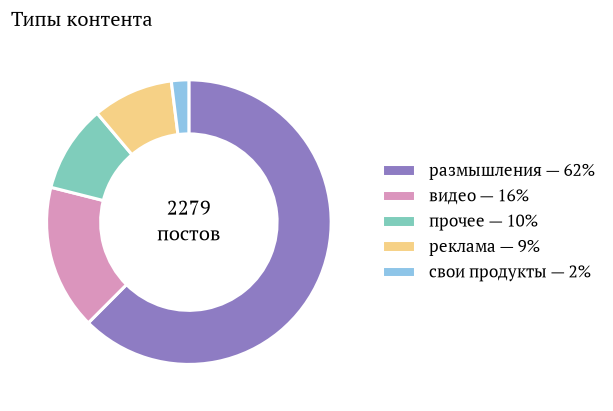

In [14]:
# Типы контента по слотам
t = pd.crosstab(posts["content_type"], posts["slot"], margins=True, margins_name="всего")
order = t.drop("всего").sort_values("всего", ascending=False).index.tolist() + ["всего"]
display(t.loc[order])

# Доли типов контента
CONTENT_NAMES = {"reflection": "размышления", "video": "видео", "other": "прочее",
                 "ad": "реклама", "own_products": "свои продукты"}
counts = posts["content_type"].value_counts()
fig, ax = plt.subplots(figsize=(7, 4.2))
wedges, _ = ax.pie(counts, startangle=90, counterclock=False, colors=PALETTE[:len(counts)],
                   wedgeprops=dict(width=0.38, edgecolor="white", linewidth=2))
ax.text(0, 0, f"{len(posts)}\nпостов", ha="center", va="center", fontsize=13)
ax.legend(wedges, [f"{CONTENT_NAMES[k]} — {n / len(posts):.0%}" for k, n in counts.items()],
          loc="center left", bbox_to_anchor=(1, 0.5))
ax.set_title("Типы контента")
plt.show()

### Признаки текста

Признаки считаются только по тексту поста, реакции, комментарии и пересылки в них не используются. Из текста перед расчётом убраны служебные хвосты: подпись «Мой канал в Максе…» и рекламный блок «Рекламная супер-ссылка…». Заголовок — первая строка поста длиной до 100 символов, после которой идёт пустая строка. Слова сравниваются со словарями в начальной форме (лемме), которую даёт pymorphy3: «ипотеку» и «ипотекой» дают «ипотека».

1. `text_len` — длина текста в символах. `text_len_bin` — длина по терцилям размышлений: короткий (до 414 символов), средний (415–719), длинный (больше 719). Границы посчитаны по размышлениям и применяются ко всем постам.
2. `title_style` — рубрика по первому слову заголовка: «самый», «как», «главный», «лайфхак», «этикет», «правило». Заголовки с другим первым словом получают значение «другой», посты без заголовка — «нет».
3. `title_tone` — тон заголовка по словарям негативных и позитивных слов (словари выведены ниже). Мат в заголовке считается негативом, кроме слов, которыми хвалят. Слово не учитывается, если перед ним стоит «не» или «ни». Тон определяется по тому, каких слов больше; если их поровну или нет совсем, тон нейтральный. У постов без заголовка значение «нет заголовка».
4. `has_question` — есть вопрос в тексте: знак «?» в любом месте текста. Ссылки из текста перед поиском убраны, так как в адресах тоже бывает «?». Признак `ask_reader` (вопрос к читателю) тоже посчитан, но дальше не используется, причина — в разделе «Признаки, которые дальше не исследуются».
5. `swear` — в тексте есть мат, `swear_n` — число матерных слов, `swear_title` — мат в заголовке. Корни мата заданы шаблонами в `scripts/swear_roots.txt`. Грубые, но не матерные слова туда не входят. Слова, похожие на мат («страхуй», «рубля», «требовать», «оскорблять»), исключены условиями в шаблонах. Во всех выводах мат замаскирован.
6. `topic` — тема поста: тема, из словаря которой в тексте больше всего слов. Если совпадений нет, тема «другое». Если у двух и более тем совпадений поровну, тема «несколько тем».

Разметку проверяют три вывода ниже: 10 случайных постов с совпадением для каждого словарного признака, самые частые слова, давшие совпадение, и 50 случайных заголовков размышлений из `data/tone_manual.csv`, у которых тон размечен вручную и сравнён с `title_tone`.


In [15]:
# Признаки текста считаются только по тексту поста. Реакции, комментарии и пересылки здесь не используются.
import re
from collections import Counter
from functools import lru_cache

import pymorphy3

morph = pymorphy3.MorphAnalyzer()


@lru_cache(maxsize=None)
def lemma(word):
    """Лемма слова в нижнем регистре, ё → е. Слова из 1–2 букв и латиница не меняются («ии» иначе станет «ия»)."""
    word = word.lower().replace("ё", "е")
    if len(word) <= 2 or word.isascii():
        return word
    return morph.parse(word)[0].normal_form.replace("ё", "е")


def lemmas(text):
    return [lemma(w) for w in re.findall(r"[а-яёa-z]+", text.lower())]


# Мат: шаблоны корней в scripts/swear_roots.txt, разделы [мат], [похвала] и [маскировать]
def read_patterns(path):
    sections, current = {}, None
    for line in open(path, encoding="utf-8"):
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        if line.startswith("["):
            current = line.strip("[]")
            sections[current] = []
        else:
            sections[current].append(line)
    return {name: re.compile("|".join(f"(?:{p})" for p in pats)) for name, pats in sections.items()}


SWEAR = read_patterns("scripts/swear_roots.txt")
CYR_WORD = r"[А-Яа-яЁё]+"  # дефис разделяет слова, поэтому «еб***ко-лайт» проверяется по частям


def is_swear(word):
    return bool(SWEAR["мат"].search(word.lower().replace("ё", "е")))


def swear_words(text):
    return [w for w in re.findall(CYR_WORD, text) if is_swear(w)]


def is_masked(word):
    """Мат или грубое слово из раздела [маскировать]: в признак swear оно не входит, но в выводах скрывается."""
    return is_swear(word) or bool(SWEAR["маскировать"].search(word.lower().replace("ё", "е")))


def mask_swear(text, md=False):
    """Маскирует мат и слова из раздела [маскировать]: первые две буквы, ***, последняя буква
    (у слов из трёх букв — первая и последняя). md=True — звёздочки экранированы для Markdown."""
    stars = r"\*\*\*" if md else "***"

    def mask(m):
        w = m[0]
        if not is_masked(w):
            return w
        return (w[:1] if len(w) <= 3 else w[:2]) + stars + w[-1]

    return re.sub(CYR_WORD, mask, str(text))


# Текст без служебных хвостов: подписи «Мой канал в Максе …» и рекламного блока «Рекламная супер-ссылка …»,
# которые стоят в конце поста
SIGNATURE = r"\s*(?:[_—–-]{3,}\s*)?Мой канал в Максе[^\n]*\s*$"
SUPERLINK_BLOCK = r"(?is)\s*Рекламная супер-ссылка.*$"
URL = r"(?i)(?:https?://|www\.)\S+|\b[\w.-]+\.(?:ru|com|рф|me|io|net|org)(?:/\S*)?"
TITLE = r"^[^\n]{1,100}\n\s*\n\S"  # то же правило заголовка, что в scripts/02_clean.py

body = (posts["text"].str.replace(SIGNATURE, "", regex=True)
        .str.replace(SUPERLINK_BLOCK, "", regex=True).str.strip())
has_title = posts["text"].str.contains(TITLE, regex=True)
title = posts["text"].str.split("\n").str[0].str.strip().where(has_title, "")
print(f"Постов с заголовком: {has_title.sum()} из {len(posts)}, "
      f"подпись про Макс убрана у {posts['text'].str.contains(SIGNATURE, regex=True).sum()}, "
      f"рекламный блок — у {posts['text'].str.contains(SUPERLINK_BLOCK, regex=True).sum()}")

Постов с заголовком: 2045 из 2279, подпись про Макс убрана у 34, рекламный блок — у 34


In [16]:
# Словари тона заголовка и тем — леммы pymorphy3 (ё → е). «лучший» и «худший» pymorphy3 сводит к «хороший» и «плохой».
TONE = {
    "негатив": {
        "тупость", "тупой", "тупица", "идиот", "идиотизм", "идиотский", "дебил", "дебильный", "дурак", "дурацкий",
        "глупость", "глупый", "говно", "бесить", "раздражать", "плохой", "убого", "ужас", "ужасный", "уныло", "кошмар",
        "отвратительный", "мерзкий", "мерзость", "позор", "позорный", "жесть", "бред", "маразм", "абсурд",
        "ненависть", "ненавидеть", "убогий", "урод", "уродливый", "уродство", "бездарный", "отстой", "сосать",
        "провал", "катастрофа", "стыд", "стыдно", "хамство", "хам", "обман", "разводка", "мошенник",
    },
    "позитив": {
        "хороший", "прекрасный", "отличный", "великолепный", "красивый", "красота", "гениальный", "гений",
        "восхитительный", "любимый", "кайф", "крутой", "круто", "клевый", "классный", "чудесный", "волшебный",
        "идеальный", "восторг", "счастье", "счастие", "радость", "удовольствие", "шедевр", "элегантный",
    },
}

TOPICS = {
    "деньги и цены": {
        "деньга", "цена", "стоить", "стоимость", "рубль", "руб", "доллар", "евро", "зарплата", "налог", "кредит",
        "кредитка", "ипотека", "инвестиция", "инвестировать", "инвестор", "бюджет", "дорогой", "дешевый", "скидка",
        "платить", "заплатить", "оплата", "оплачивать", "купить", "покупать", "покупка", "продать", "продавать",
        "миллион", "миллиард", "богатый", "бедный", "бедность", "экономика", "инфляция", "заработать",
        "зарабатывать", "доход", "прибыль", "алименты",
    },
    "дизайн": {
        "дизайн", "дизайнер", "дизайнерский", "шрифт", "шрифтовой", "логотип", "типографика", "типографский",
        "верстка", "верстать", "макет", "интерфейс", "айдентика", "леттеринг", "плакат", "вывеска", "навигация",
        "архитектура", "архитектор", "упаковка", "эстетика", "композиция", "тайпспейс", "обои",
    },
    "путешествия и страны": {
        "путешествие", "путешествовать", "страна", "поездка", "турист", "туризм", "отель", "гостиница", "виза",
        "граница", "самолет", "аэропорт", "перелет", "лететь", "полет", "отпуск", "заграница", "мексика",
        "таиланд", "пхукет", "италия", "франция", "япония", "китай", "индия", "америка", "сша", "европа",
        "германия", "испания", "турция", "грузия", "армения", "мадагаскар", "антарктида", "африка", "израиль",
        "дубай", "вьетнам", "бали", "лондон", "париж",
    },
    "еда": {
        "еда", "ресторан", "кафе", "блюдо", "вкус", "вкусный", "завтрак", "обед", "ужин", "мясо", "хлеб", "сыр",
        "вино", "пиво", "водка", "кофе", "чай", "салат", "суп", "рецепт", "готовить", "повар", "кухня", "шашлык",
        "майонез", "помидор", "огурец", "фрукт", "овощ", "яблоко", "орех", "сахар", "соус", "пицца", "бургер",
        "напиток", "газировка", "коктейль", "десерт", "торт", "шоколад", "мороженое", "рыба", "курица",
        "картошка", "вегетарианец", "пищевой", "съесть", "жрать", "жратва", "дегустация",
    },
    "машины и дороги": {
        "машина", "автомобиль", "авто", "тачка", "водитель", "дорога", "пробка", "парковка", "парковать",
        "светофор", "пешеход", "руль", "трасса", "шоссе", "такси", "гаишник", "гибдд", "дпс", "бензин",
        "двигатель", "мотоцикл", "самокат", "велосипед", "перекресток", "разметка", "колесо", "электромобиль",
    },
    "технологии и ИИ": {
        "технология", "ии", "нейросеть", "нейронка", "chatgpt", "gpt", "ai", "робот", "компьютер", "ноутбук",
        "смартфон", "телефон", "айфон", "iphone", "приложение", "гаджет", "программа", "программист", "алгоритм",
        "интернет", "сайт", "браузер", "софт", "обновление", "цифровой", "онлайн", "бот", "электроника", "apple",
        "android", "андроид", "макбук",
    },
    "город": {
        "город", "городской", "москва", "московский", "улица", "урбанистика", "район", "двор", "тротуар", "площадь",
        "метро", "здание", "мэрия", "собянин", "благоустройство", "плитка", "парк", "сквер", "набережная",
        "застройка", "девелопер", "подъезд", "петербург", "питер", "памятник", "автобус", "трамвай",
    },
    "сервисы и обслуживание": {
        "сервис", "обслуживание", "клиент", "поддержка", "суппорт", "оператор", "банк", "сбер", "сбербанк",
        "тинькофф", "маркетплейс", "озон", "ozon", "вайлдберриз", "wildberries", "авиакомпания", "аэрофлот",
        "яндекс", "курьер", "доставка", "заказ", "заказывать", "официант", "магазин", "продавец", "кассир",
        "госуслуги", "мфц", "почта", "провайдер", "ржд", "колл-центр",
    },
    # Без многозначных слов: сердце, давление, операция, температура, сон, вес, зал, анализ
    "здоровье": {
        "здоровье", "здоровый", "болезнь", "болеть", "больной", "врач", "доктор", "медицина", "медицинский",
        "лекарство", "таблетка", "лечение", "лечить", "клиника", "больница", "поликлиника", "диагноз", "симптом",
        "похудение", "похудеть", "худеть", "диета", "калория", "ожирение", "тирзетта", "оземпик", "семаглутид",
        "тирзепатид", "пищевод", "желудок", "кишечник", "кишка", "кишечный", "печень", "почка", "холестерин",
        "диабет", "бактерия", "микробиом", "вирус", "иммунитет", "витамин", "прививка", "вакцина", "рак",
        "опухоль", "хирург", "стоматолог", "зуб", "зубной", "боль", "тренировка", "фитнес", "бессонница",
        "мышца", "сустав", "позвоночник", "гормон", "инсульт", "инфаркт", "аллергия", "простуда", "грипп",
        "ковид", "пробиотик", "пищеварение", "изжога", "отрыжка", "запор", "метаболизм", "глютен", "лактоза",
        "психотерапевт", "депрессия",
    },
}

# Рубрики заголовков: первое слово заголовка (лемма) → title_style. Выбраны по 20 самым частым первым словам ниже.
TITLE_STYLES = {"самый": "самый", "как": "как", "главный": "главный", "лайфхак": "лайфхак", "этикет": "этикет",
                "правило": "правило"}
ASK_PHRASES = r"(?i)\bа вы\b|\bкак вы думаете\b|\bнапишите в комментари|\bрасскажите\b"

def dict_table(d, label):
    """Словарь {название: множество слов} — таблица: название, число слов, слова по алфавиту."""
    t = pd.DataFrame([{label: k, "слов": len(v), "слова": ", ".join(sorted(v))} for k, v in d.items()])
    return (t.style.hide(axis="index")
            .set_properties(subset=[label], **{"text-align": "left", "white-space": "nowrap", "vertical-align": "top"})
            .set_properties(subset=["слов"], **{"vertical-align": "top"})
            .set_properties(subset=["слова"], **{"text-align": "left", "white-space": "normal", "max-width": "700px"}))


display(Markdown("**Словари тона заголовка**"))
display(dict_table(TONE, "тон"))
display(Markdown("Мат в заголовке (шаблоны из `scripts/swear_roots.txt`) считается негативом, "
                 "кроме слов из раздела [похвала], они считаются позитивом."))
display(Markdown("**Словари тем**"))
display(dict_table(TOPICS, "тема"))

**Словари тона заголовка**

тон,слов,слова
негатив,48,"абсурд, бездарный, бесить, бред, глупость, глупый, говно, дебил, дебильный, дурак, дурацкий, жесть, идиот, идиотизм, идиотский, катастрофа, кошмар, маразм, мерзкий, мерзость, мошенник, ненавидеть, ненависть, обман, отвратительный, отстой, плохой, позор, позорный, провал, разводка, раздражать, сосать, стыд, стыдно, тупица, тупой, тупость, убогий, убого, ужас, ужасный, уныло, урод, уродливый, уродство, хам, хамство"
позитив,25,"великолепный, волшебный, восторг, восхитительный, гениальный, гений, идеальный, кайф, классный, клевый, красивый, красота, круто, крутой, любимый, отличный, прекрасный, радость, счастие, счастье, удовольствие, хороший, чудесный, шедевр, элегантный"


Мат в заголовке (шаблоны из `scripts/swear_roots.txt`) считается негативом, кроме слов из раздела [похвала], они считаются позитивом.

**Словари тем**

тема,слов,слова
деньги и цены,41,"алименты, бедность, бедный, богатый, бюджет, деньга, дешевый, доллар, дорогой, доход, евро, заплатить, зарабатывать, заработать, зарплата, инвестировать, инвестиция, инвестор, инфляция, ипотека, кредит, кредитка, купить, миллиард, миллион, налог, оплата, оплачивать, платить, покупать, покупка, прибыль, продавать, продать, руб, рубль, скидка, стоимость, стоить, цена, экономика"
дизайн,24,"айдентика, архитектор, архитектура, верстать, верстка, вывеска, дизайн, дизайнер, дизайнерский, интерфейс, композиция, леттеринг, логотип, макет, навигация, обои, плакат, тайпспейс, типографика, типографский, упаковка, шрифт, шрифтовой, эстетика"
путешествия и страны,42,"америка, антарктида, армения, африка, аэропорт, бали, виза, вьетнам, германия, гостиница, граница, грузия, дубай, европа, заграница, израиль, индия, испания, италия, китай, лететь, лондон, мадагаскар, мексика, отель, отпуск, париж, перелет, поездка, полет, путешествие, путешествовать, пхукет, самолет, страна, сша, таиланд, туризм, турист, турция, франция, япония"
еда,51,"блюдо, бургер, вегетарианец, вино, вкус, вкусный, водка, газировка, готовить, дегустация, десерт, еда, жратва, жрать, завтрак, картошка, кафе, коктейль, кофе, курица, кухня, майонез, мороженое, мясо, напиток, обед, овощ, огурец, орех, пиво, пицца, пищевой, повар, помидор, ресторан, рецепт, рыба, салат, сахар, соус, суп, съесть, сыр, торт, ужин, фрукт, хлеб, чай, шашлык, шоколад, яблоко"
машины и дороги,27,"авто, автомобиль, бензин, велосипед, водитель, гаишник, гибдд, двигатель, дорога, дпс, колесо, машина, мотоцикл, парковать, парковка, перекресток, пешеход, пробка, разметка, руль, самокат, светофор, такси, тачка, трасса, шоссе, электромобиль"
технологии и ИИ,32,"ai, android, apple, chatgpt, gpt, iphone, айфон, алгоритм, андроид, бот, браузер, гаджет, ии, интернет, компьютер, макбук, нейронка, нейросеть, ноутбук, обновление, онлайн, приложение, программа, программист, робот, сайт, смартфон, софт, телефон, технология, цифровой, электроника"
город,27,"автобус, благоустройство, город, городской, двор, девелопер, застройка, здание, метро, москва, московский, мэрия, набережная, памятник, парк, петербург, питер, плитка, площадь, подъезд, район, сквер, собянин, трамвай, тротуар, улица, урбанистика"
сервисы и обслуживание,32,"ozon, wildberries, авиакомпания, аэрофлот, банк, вайлдберриз, госуслуги, доставка, заказ, заказывать, кассир, клиент, колл-центр, курьер, магазин, маркетплейс, мфц, обслуживание, озон, оператор, официант, поддержка, почта, провайдер, продавец, ржд, сбер, сбербанк, сервис, суппорт, тинькофф, яндекс"
здоровье,74,"аллергия, бактерия, бессонница, болезнь, болеть, боль, больница, больной, вакцина, вирус, витамин, врач, глютен, гормон, грипп, депрессия, диабет, диагноз, диета, доктор, желудок, запор, здоровый, здоровье, зуб, зубной, изжога, иммунитет, инсульт, инфаркт, калория, кишечник, кишечный, кишка, клиника, ковид, лактоза, лекарство, лечение, лечить, медицина, медицинский, метаболизм, микробиом, мышца, ожирение, оземпик, опухоль, отрыжка, печень, пищеварение, пищевод, позвоночник, поликлиника, похудение, похудеть, почка, прививка, пробиотик, простуда, психотерапевт, рак, семаглутид, симптом, стоматолог, сустав, таблетка, тирзепатид, тирзетта, тренировка, фитнес, хирург, холестерин, худеть"


In [17]:
title_lemmas = title.map(lemmas)
body_lemmas = body.map(lemmas)

# 1. Длина. Границы терцилей — по размышлениям, применяются ко всем постам.
posts["text_len"] = body.str.len()
q1, q2 = posts.loc[posts["content_type"] == "reflection", "text_len"].quantile([1 / 3, 2 / 3])
posts["text_len_bin"] = pd.cut(posts["text_len"], [-1, q1, q2, np.inf], labels=["короткий", "средний", "длинный"])
print(f"Границы длины по размышлениям: короткий ≤ {q1:.0f} символов, средний ≤ {q2:.0f}, длинный — больше")

# 2. Рубрика заголовка
first_word = title_lemmas.str[0]
display(Markdown("**20 самых частых первых слов заголовков (леммы), все типы контента**"))
display(first_word.dropna().map(mask_swear).value_counts().head(20).rename_axis("первое слово").rename("постов").to_frame().T)
posts["title_style"] = np.where(~has_title, "нет", first_word.map(TITLE_STYLES).fillna("другой"))

# 3. Тон заголовка. Слово из словаря или мат не учитывается, если перед ним стоит «не» или «ни» («не глупость»).
NEGATIONS = {"не", "ни"}
# «Самый хороший подкаст» — название его подкаста, оценки в нём нет, поэтому для тона оно вырезается из заголовка
PODCAST_NAME = r"(?i)самый\s+хороший\s+подкаст"


def title_tone(i):
    if not has_title.iat[i]:
        return "нет заголовка", [], []
    words = re.findall(r"[а-яёa-z]+", re.sub(PODCAST_NAME, " ", title.iat[i]).lower())
    neg, pos, negated = [], [], []
    for k, w in enumerate(words):
        l = lemma(w)
        if is_swear(w):
            side = pos if SWEAR["похвала"].search(w.replace("ё", "е")) else neg
            word = w
        elif l in TONE["негатив"] or l in TONE["позитив"]:
            side = neg if l in TONE["негатив"] else pos
            word = l
        else:
            continue
        if k > 0 and words[k - 1] in NEGATIONS:
            negated.append(f"{words[k - 1]} {word}")
        else:
            side.append(word)
    tone = "негатив" if len(neg) > len(pos) else "позитив" if len(pos) > len(neg) else "нейтральный"
    return tone, neg + pos, negated


tone = [title_tone(i) for i in range(len(posts))]
posts["title_tone"] = [t for t, _, _ in tone]
tone_found = pd.Series([f for _, f, _ in tone], index=posts.index)
tone_negated = pd.Series([n for _, _, n in tone], index=posts.index)
print(f"Слова тона после «не»/«ни» не учтены в {(tone_negated.str.len() > 0).sum()} заголовках: "
      + "; ".join(f"{i} «{mask_swear(', '.join(n))}»" for i, n in zip(posts["id"], tone_negated) if n))

# 4. Вопрос к читателю
no_url = body.str.replace(URL, "", regex=True)
last_par = no_url.map(lambda t: re.split(r"\n\s*\n", t.strip())[-1])
ask_found = last_par.map(lambda t: (["?"] if "?" in t else []) + [m.lower() for m in re.findall(ASK_PHRASES, t)])
posts["ask_reader"] = ask_found.str.len() > 0
posts["has_question"] = no_url.str.contains("?", regex=False)

# 5. Мат
swear_found = body.map(swear_words)
posts["swear_n"] = swear_found.str.len()
posts["swear"] = posts["swear_n"] > 0
posts["swear_title"] = title.map(lambda t: len(swear_words(t)) > 0)

# 6. Тема: больше всего совпадений. Если максимум у нескольких тем — «несколько тем», без совпадений — «другое».
topic_hits = body_lemmas.map(lambda ls: {name: [w for w in ls if w in words] for name, words in TOPICS.items()})
topic_n = pd.DataFrame([{k: len(v) for k, v in h.items()} for h in topic_hits], index=posts.index)
top_n = topic_n.max(axis=1)
is_top = topic_n.eq(top_n, axis=0) & (top_n > 0).to_numpy()[:, None]
tie = is_top.sum(axis=1) > 1
posts["topic"] = np.select([top_n == 0, tie], ["другое", "несколько тем"], default=topic_n.idxmax(axis=1))
# Для проверки: у «несколько тем» — названия тем с равным числом совпадений, у остальных — найденные слова
topic_found = pd.Series([[k for k in TOPICS if is_top.at[i, k]] if tie[i] else hits.get(t, [])
                         for i, hits, t in zip(posts.index, topic_hits, posts["topic"])], index=posts.index)
print(f"Тема «несколько тем» (поровну совпадений у двух и более тем): {tie.sum()} постов")

TEXT_FEATURES = ["text_len", "text_len_bin", "title_style", "title_tone", "ask_reader", "has_question",
                 "swear", "swear_title", "swear_n", "topic"]
posts[TEXT_FEATURES].head()

Границы длины по размышлениям: короткий ≤ 414 символов, средний ≤ 719, длинный — больше


**20 самых частых первых слов заголовков (леммы), все типы контента**

первое слово,зая,самый,зай,как,ответ,заюня,зайка,хороший,главный,не,новый,зайчик,о,что,мой,простой,кстати,два,по,почему
постов,113,86,38,31,25,23,16,14,12,11,11,11,10,10,8,8,7,7,7,7


Слова тона после «не»/«ни» не учтены в 1 заголовках: 8992 «не пр***ь»


Тема «несколько тем» (поровну совпадений у двух и более тем): 206 постов


,text_len,text_len_bin,title_style,title_tone,ask_reader,has_question,swear,swear_title,swear_n,topic
0,1153,длинный,другой,нейтральный,False,False,True,False,2,здоровье
1,285,короткий,другой,нейтральный,False,False,False,False,0,еда
2,444,средний,другой,нейтральный,False,True,False,False,0,путешествия и страны
3,195,короткий,другой,нейтральный,False,False,False,False,0,другое
4,510,средний,другой,нейтральный,True,True,True,False,1,путешествия и страны


In [18]:
# Проверка разметки: по 10 случайных постов с совпадением
def show_sample(mask, found, name, seed=1, text=None, text_name="заголовок"):
    text = title if text is None else text
    sample = posts[mask].sample(min(10, mask.sum()), random_state=seed)
    display(Markdown(f"**{name}: {len(sample)} случайных постов из {mask.sum()}**"))
    with pd.option_context("display.max_colwidth", None):  # иначе pandas обрезает текст до 50 символов
        display(pd.DataFrame({
            "id": sample["id"],
            "тип": sample["content_type"],
            text_name: text[sample.index].map(mask_swear),
            "найдено": found[sample.index].map(lambda ws: mask_swear(", ".join(ws))),
        }).set_index("id"))


with_label = lambda found, label: pd.Series([[f"{l}:"] + ws for ws, l in zip(found, label)], index=posts.index)
show_sample(posts["title_tone"].isin(["негатив", "позитив"]), with_label(tone_found, posts["title_tone"]), "title_tone")
show_sample(posts["ask_reader"], ask_found, "ask_reader",
            text=last_par.str.strip().str.replace(r"\s*\n\s*", " / ", regex=True)
            .map(lambda t: t if len(t) <= 200 else t[:200] + "…"),
            text_name="последний абзац (без ссылок, до 200 символов, / — перенос строки)")
show_sample(posts["swear"], swear_found, "swear")
show_sample(posts["topic"] != "другое", with_label(topic_found, posts["topic"]), "topic")

**title_tone: 10 случайных постов из 120**

,тип,заголовок,найдено
id,,,
10851,reflection,Разводка в инете,"негатив:, разводка"
9819,reflection,Лучшие дворники на свете,"позитив:, хороший"
9948,other,Осторожно: мошенники и инфоцыгане,"негатив:, мошенник"
11286,reflection,Почему в России пи***ц,"негатив:, пи***ц"
10498,reflection,Красота,"позитив:, красота"
9602,ad,Бриллианты и пи***я,"негатив:, пи***я"
9160,reflection,Х***й угадаешь,"негатив:, х***й"
10593,reflection,Жесть,"негатив:, жесть"
9636,reflection,Как интеллигентно послать на***й,"негатив:, на***й"


**ask_reader: 10 случайных постов из 308**

,тип,"последний абзац (без ссылок, до 200 символов, / — перенос строки)",найдено
id,,,
9150,other,"Зай, а у тебя бывает такое, что ты доедаешь продукты, чтобы они просто не пропали?",?
11311,reflection,"- А зачем людей с квартирами сравнивать? / - Потому что все понимают, что квартиру можно полгода искать, не соглашаясь на компромисс, а про людей не понимают.",?
10624,reflection,А какие вы помните примеры перевирания исторических фактов в угоду желанному стереотипу?,?
10684,reflection,"Еб***ь всегда (иначе откуда на свет появились мы, наши родители, дедушки с бабушками, прадедушки с прабабушками и другие предки?). Но всегда немного с поправкой на эпоху. И это замечательно.",?
10903,reflection,"Ну и чо? В чем проблема с этим выражением в этой стране? Чо, нет других проблем в этой стране?",?
9910,reflection,"Только скажет кто-нибудь спич проникновенный - сразу народ такой: ""В президенты его!"". Ну почему сразу президентом? Есть же куча других прекрасных должностей в стране.",?
10311,other,"Зая, хочу протестировать бота, который бы с помощью ИИ еб***л бы шлюхоботов и ставочниц в три жо***ы. Подпишешься для своего канала за скромную подписку?",?
10613,reflection,"Спрашивается - почему бы не восстановить поставки соломы и других пустотелых сухих трав? Это экологично, нейтрально, ответственно, недорого и пр.",?
11029,reflection,А какие еще?,?


**swear: 10 случайных постов из 936**

,тип,заголовок,найдено
id,,,
9750,reflection,Лактозная непереносимость,"Пи***ц, б***я, ху***о"
8798,reflection,Тродоустроенческое малодушие,"Пи***ц, Бл***ь, бл***ь, На***й"
10753,video,1. Корни и коды | Создатели пространства: Искусство дизайна,пи***о
10454,other,​​Коврики на даче,сп***ь
8773,reflection,Глобальное ох***е,"ох***е, х***е"
9621,reflection,Мягкая зубная щетка,на***й
10681,video,"Зая, так много всего ох***о в мире происходит!",ох***о
10482,reflection,Температура еды,"Пи***ц, бл***ь, бл***ь, бл***ь, ни***я, Ху***к, бл***ь, Пи***ц"
9871,other,Не все полимеры просраны!,"пи***о, сп***л"


**topic: 10 случайных постов из 1346**

,тип,заголовок,найдено
id,,,
9645,reflection,Претензии к отечественной медицине,"здоровье:, медицина, лекарство, врач, лечить, лечение, медицина"
9461,ad,Операторы,"сервисы и обслуживание:, оператор, оператор, оператор, оператор"
10614,reflection,Декомпрессия,"деньги и цены:, стоить"
10206,reflection,Демократия в Африке,"путешествия и страны:, африка, африка, страна, страна"
10077,reflection,Вздрем,"машины и дороги:, трасса, водитель, руль, водитель, трасса"
9280,ad,Выгодные инвестиции,"деньги и цены:, инвестиция, заработать, деньга, инвестиция, цена, рубль, инвестиция, инвестировать"
9443,other,Инцидент менеджмент и качели,"несколько тем:, технологии и ИИ, город"
10563,reflection,Дисплейная наркомания,"технологии и ИИ:, телефон"
8783,ad,Утилитарная эстетика,"дизайн:, эстетика, эстетика, дизайн, эстетика, эстетика"


In [19]:
# Выборка для ручной разметки тона: 50 случайных размышлений. Файл data/tone_manual.csv создаётся один раз,
# чтобы перезапуск ноутбука не затёр ручную разметку; разметку вписывать в столбец tone_manual
# (негатив / позитив / нейтральный). Когда он заполнен, ниже считается совпадение с title_tone.
# Если файл уже есть, таблица строится по заголовкам из него: новая случайная выборка после изменения
# разметки типов постов дала бы другие 50 заголовков, не те, что размечены вручную.
from pathlib import Path

TONE_MANUAL = Path("data/tone_manual.csv")
refl_titled = posts[(posts["content_type"] == "reflection") & has_title]
if TONE_MANUAL.exists():
    pos = pd.Series(posts.index, index=posts["id"])
    tone_sample = posts.loc[pos[pd.read_csv(TONE_MANUAL)["id"]].to_numpy()]
    assert tone_sample.index.isin(refl_titled.index).all(), "в tone_manual.csv есть посты, которые больше не размышления"
else:
    tone_sample = refl_titled.sample(50, random_state=7)
tone_table = pd.DataFrame({
    "id": tone_sample["id"],
    "заголовок": title[tone_sample.index].map(mask_swear),
    "title_tone": tone_sample["title_tone"],
    "найдено": tone_found[tone_sample.index].map(lambda ws: mask_swear(", ".join(ws))),
    "не учтено (не/ни)": tone_negated[tone_sample.index].map(lambda ws: mask_swear(", ".join(ws))),
    "tone_manual": "",
})
if not TONE_MANUAL.exists():
    tone_table.to_csv(TONE_MANUAL, index=False)
    print(f"Создан {TONE_MANUAL}")

display(Markdown(f"**50 случайных заголовков размышлений для ручной разметки тона ({TONE_MANUAL})**"))
display(tone_table.set_index("id"))
print(tone_table["title_tone"].value_counts().to_string())

manual = pd.read_csv(TONE_MANUAL, dtype={"tone_manual": str})
labeled = manual[manual["tone_manual"].fillna("").str.strip() != ""]
if len(labeled):
    check = labeled.merge(posts[["id", "title_tone"]], on="id", suffixes=("_при_разметке", ""))
    # В разметке встречается «негативный» вместо «негатив» — приводим к одному написанию
    check["tone_manual"] = check["tone_manual"].str.strip().replace({"негативный": "негатив", "позитивный": "позитив"})
    assert check["tone_manual"].isin(["негатив", "позитив", "нейтральный"]).all(), check["tone_manual"].unique()
    agree = check["title_tone"] == check["tone_manual"]
    # Каппа Коэна: совпадение сверх случайного при тех же долях тонов. Нужна, так как 9 из 10 заголовков
    # нейтральные, и словарь, который всем ставит «нейтральный», уже получил бы высокое совпадение.
    p_chance = (check["title_tone"].value_counts(normalize=True)
                * check["tone_manual"].value_counts(normalize=True)).sum()
    kappa = (agree.mean() - p_chance) / (1 - p_chance)
    print(f"Совпадение title_tone с ручной разметкой: {agree.mean():.0%} ({agree.sum()} из {len(check)}), "
          f"случайное совпадение при тех же долях: {p_chance:.0%}, каппа Коэна: {kappa:.2f}")
    display(pd.crosstab(check["tone_manual"], check["title_tone"], margins=True, margins_name="всего")
            .rename_axis(index="вручную", columns="по словарю"))
    display(Markdown("**Точность и полнота словаря по каждому тону**"))
    display(pd.DataFrame({t: {
        "по словарю": (check["title_tone"] == t).sum(),
        "вручную": (check["tone_manual"] == t).sum(),
        "совпало": ((check["title_tone"] == t) & (check["tone_manual"] == t)).sum(),
    } for t in ["негатив", "позитив", "нейтральный"]}).T.assign(
        **{"точность": lambda d: (d["совпало"] / d["по словарю"]).round(2),
           "полнота": lambda d: (d["совпало"] / d["вручную"]).round(2)}))
    display(Markdown("**Расхождения**"))
    display(check.loc[~agree, ["id", "заголовок", "title_tone", "tone_manual"]].set_index("id"))

**50 случайных заголовков размышлений для ручной разметки тона (data/tone_manual.csv)**

,заголовок,title_tone,найдено,не учтено (не/ни),tone_manual
id,,,,,
9588,Обезжирка,нейтральный,,,
10930,Отношение к ресурсам,нейтральный,,,
11282,Дошик + красота,позитив,красота,,
8818,Эвиан,нейтральный,,,
9817,Шашлык,нейтральный,,,
11188,Подписи,нейтральный,,,
10444,Болтливые голосовые помощники,нейтральный,,,
10748,"Что делать, если ты не нравишься",нейтральный,,,
9490,Кого нельзя брать на работу,нейтральный,,,


title_tone
нейтральный    47
негатив         2
позитив         1
Совпадение title_tone с ручной разметкой: 92% (46 из 50), случайное совпадение при тех же долях: 81%, каппа Коэна: 0.57


по словарю,негатив,нейтральный,позитив,всего
вручную,,,,
негатив,2,4,0,6
нейтральный,0,43,0,43
позитив,0,0,1,1
всего,2,47,1,50


**Точность и полнота словаря по каждому тону**

,по словарю,вручную,совпало,точность,полнота
негатив,2,6,2,1.00,0.33
позитив,1,1,1,1.00,1.00
нейтральный,47,43,43,0.91,1.00


**Расхождения**

,заголовок,title_tone,tone_manual
id,,,
10444,Болтливые голосовые помощники,нейтральный,негатив
11008,Жо***а трусы зажевала,нейтральный,негатив
11093,Всю власть молодым! (Нет.),нейтральный,негатив
10020,Жо***г,нейтральный,негатив


In [20]:
# Какие слова чаще всего дали совпадение
def top_words(found, n=15):
    c = Counter(w.lower() for ws in found for w in ws)
    return ", ".join(f"{mask_swear(w)} ({k})" for w, k in c.most_common(n))


rows = [("тон заголовка: негатив", tone_found[posts["title_tone"] == "негатив"], 15),
        ("тон заголовка: позитив", tone_found[posts["title_tone"] == "позитив"], 15),
        ("вопрос к читателю", ask_found, 15),
        ("мат (словоформы)", swear_found, 25)]
rows += [(f"тема: {name}", topic_hits.map(lambda h, name=name: h[name]), 15) for name in TOPICS]
words_table = pd.DataFrame([{"признак": name, "слова (число совпадений)": top_words(found, n)}
                            for name, found, n in rows])

display(Markdown("**Слова, чаще всего давшие совпадение**"))
display(words_table.style.hide(axis="index")
        .set_properties(subset=["признак"], **{"text-align": "left", "white-space": "nowrap", "vertical-align": "top"})
        .set_properties(subset=["слова (число совпадений)"],
                        **{"text-align": "left", "white-space": "normal", "max-width": "800px"}))

**Слова, чаще всего давшие совпадение**

признак,слова (число совпадений)
тон заголовка: негатив,"плохой (5), пи***ц (3), на***ь (3), ненависть (3), тупость (3), разводка (3), мошенник (3), жесть (3), на***й (2), пи***я (2), за***л (1), мерзкий (1), говно (1), ох***е (1), на***а (1)"
тон заголовка: позитив,"хороший (26), красота (6), кайф (6), любимый (4), счастие (3), гениальный (3), красивый (3), гений (3), идеальный (2), удовольствие (1), прекрасный (1), пи***о (1), ох***е (1), ох***ю (1), ох***о (1)"
вопрос к читателю,"? (304), а вы (12), расскажите (4)"
мат (словоформы),"пи***ц (294), на***й (178), бл***ь (106), ху***я (95), х***й (89), ни***я (61), по***й (41), ху***ю (40), ху***о (36), ох***о (30), му***к (28), на***я (28), б***я (21), ох***й (18), еб***т (18), до***я (16), ху***и (15), на***а (14), х***я (14), на***ь (14), ох***е (13), вы***я (12), му***и (12), х***ю (11), ху***у (11)"
тема: деньги и цены,"деньга (175), стоить (130), рубль (113), купить (104), миллион (84), цена (82), покупать (77), дорогой (60), скидка (59), платить (58), продавать (54), дешевый (45), доллар (41), инвестиция (40), покупка (35)"
тема: дизайн,"дизайн (145), дизайнер (96), логотип (58), упаковка (20), архитектура (18), архитектор (18), интерфейс (11), шрифт (10), эстетика (5), плакат (5), дизайнерский (4), навигация (3), тайпспейс (3), композиция (2), айдентика (1)"
тема: путешествия и страны,"страна (188), самолет (55), граница (41), америка (38), гостиница (32), отель (32), европа (28), сша (21), поездка (18), аэропорт (17), китай (17), мексика (17), виза (16), япония (12), путешествие (12)"
тема: еда,"еда (138), вино (111), вкус (107), ресторан (95), вкусный (76), кофе (67), чай (47), съесть (41), напиток (39), мясо (39), кафе (34), хлеб (33), салат (30), водка (29), обед (26)"
тема: машины и дороги,"машина (71), дорога (70), водитель (61), автомобиль (32), пешеход (27), такси (24), руль (22), пробка (13), колесо (8), авто (8), трасса (8), тачка (7), двигатель (7), шоссе (6), светофор (4)"
тема: технологии и ИИ,"сайт (93), телефон (89), программа (65), интернет (54), технология (32), приложение (31), айфон (29), компьютер (21), цифровой (19), нейросеть (18), бот (18), смартфон (18), онлайн (18), алгоритм (16), гаджет (13)"


**Длина текста и мат по типу поста**

,"длина текста, медиана (символов)","матерных слов на пост, среднее",постов
content_type,,,
reflection,553,1.19,1424
video,253,0.05,375
other,82,0.47,226
ad,791,1.47,209
own_products,664,0.29,45


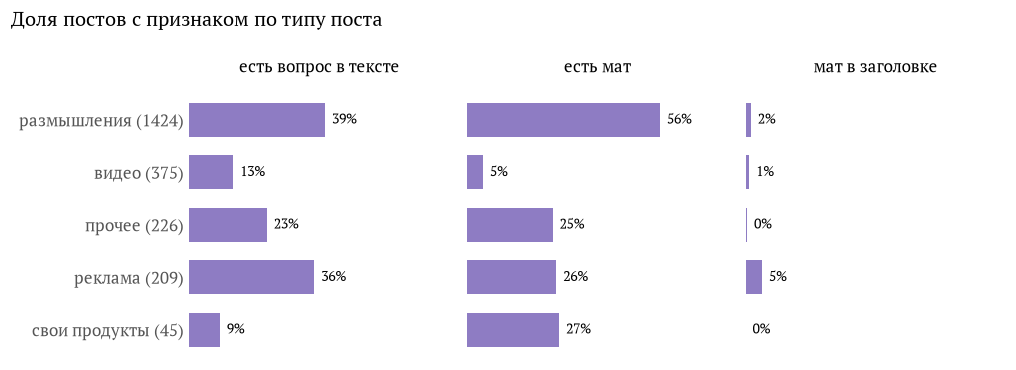

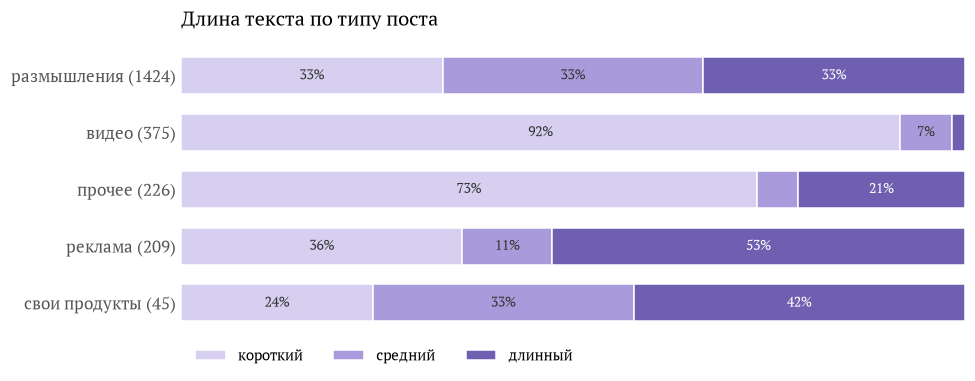

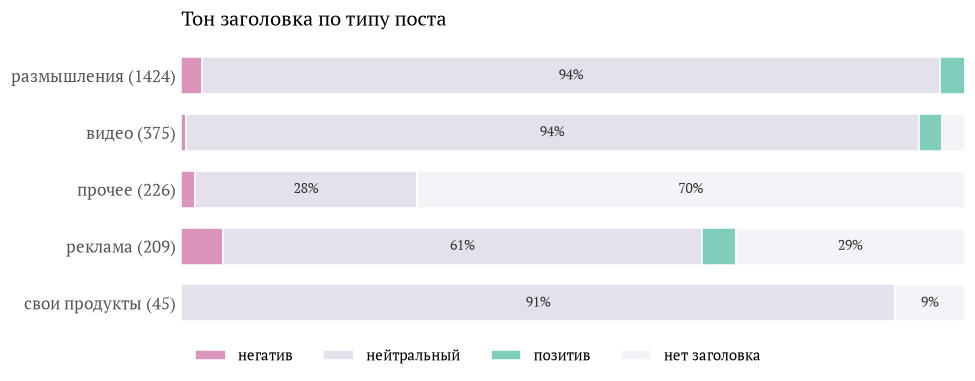

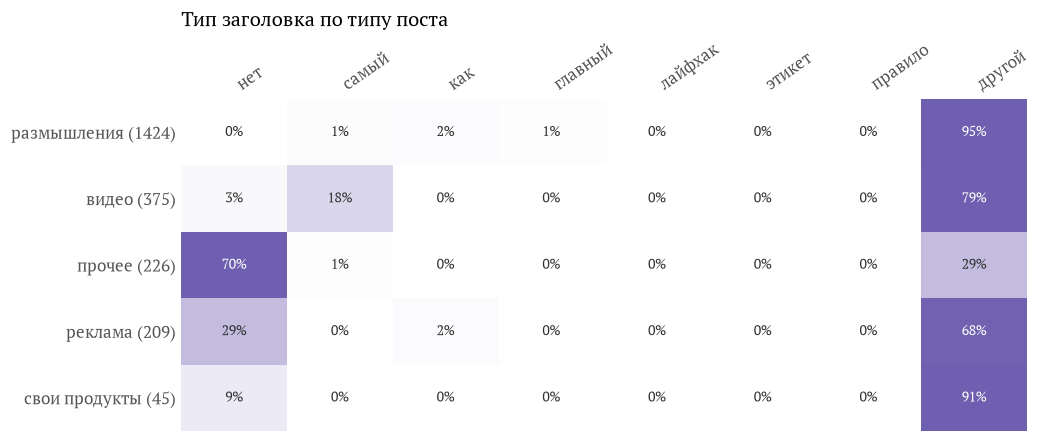

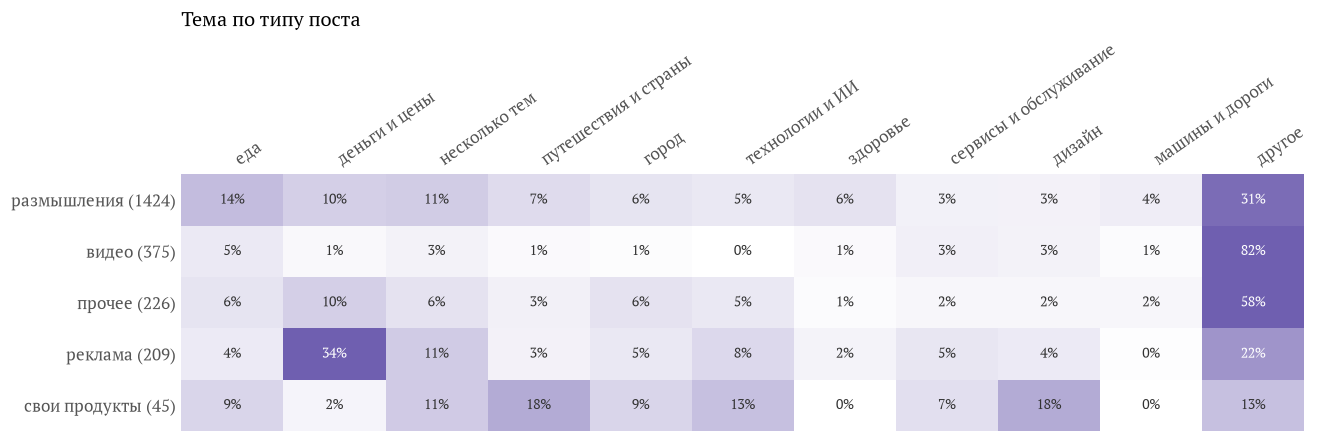

In [21]:
# Распределение признаков текста по content_type и по слотам внутри размышлений
from matplotlib.colors import LinearSegmentedColormap, to_rgb

FEATURE_NAMES = {"has_question": "есть вопрос в тексте",
                 "swear": "есть мат", "swear_title": "мат в заголовке"}
LEN_COLORS = {"короткий": "#D7CFF0", "средний": "#A99BDB", "длинный": "#6F5FB0"}
TONE_COLORS = {"негатив": "#DB95BD", "нейтральный": "#E4E1EC", "позитив": "#7FCDBB", "нет заголовка": "#F5F3F8"}
HEAT = LinearSegmentedColormap.from_list("heat", ["#FFFFFF", "#6F5FB0"])


def text_color(color):
    r, g, b = to_rgb(color)
    return "white" if 0.299 * r + 0.587 * g + 0.114 * b < 0.5 else "#333333"


def group_order(df, group):
    """Типы контента — по убыванию числа постов, слоты — по времени."""
    vc = df[group].value_counts()
    return list(vc.index) if group == "content_type" else sorted(vc.index)


def group_labels(df, group, order):
    vc = df[group].value_counts()
    names = CONTENT_NAMES if group == "content_type" else {}
    return [f"{names.get(k, k)} ({vc[k]})" for k in order]


def clean_axes(ax):
    ax.grid(False)
    ax.tick_params(length=0)
    for side in ["top", "right", "bottom", "left"]:
        ax.spines[side].set_visible(False)


def length_stats(df, group):
    g = df.groupby(group, observed=True)
    return pd.DataFrame({
        "длина текста, медиана (символов)": g["text_len"].median().round().astype(int),
        "матерных слов на пост, среднее": g["swear_n"].mean().round(2),
        "постов": g.size(),
    }).loc[group_order(df, group)]


def plot_binary(df, group, features, title):
    """Доля постов с признаком: по одной панели на признак, шкала у всех панелей общая."""
    order = group_order(df, group)
    shares = df.groupby(group, observed=True)[features].mean().loc[order]
    y = np.arange(len(order))
    fig, axes = plt.subplots(1, len(features), figsize=(2.6 * len(features) + 1.5, 0.42 * len(order) + 1.3),
                             sharey=True)
    for ax, f in zip(axes, features):
        ax.barh(y, shares[f], color=PALETTE[0], height=0.65)
        for yi, v in zip(y, shares[f]):
            ax.text(v + 0.02, yi, f"{v:.0%}", va="center", fontsize=9)
        ax.set_xlim(0, shares.values.max() * 1.35)
        ax.set_xticks([])
        ax.set_title(FEATURE_NAMES[f], fontsize=11, loc="center")
        clean_axes(ax)
    axes[0].set_yticks(y, group_labels(df, group, order))
    axes[0].invert_yaxis()
    fig.suptitle(title, x=0.01, ha="left", fontsize=13)
    fig.tight_layout()
    plt.show()


def plot_stacked(df, group, feature, colors, title):
    """Состав групп по значениям признака, доли в сумме 100%. Подписи у долей от 6%."""
    order = group_order(df, group)
    t = pd.crosstab(df[group], df[feature], normalize="index").reindex(index=order, fill_value=0)
    colors = {k: c for k, c in colors.items() if k in t.columns and t[k].sum() > 0}
    y, left = np.arange(len(order)), np.zeros(len(order))
    fig, ax = plt.subplots(figsize=(9, 0.42 * len(order) + 1.5))
    for v, c in colors.items():
        ax.barh(y, t[v], left=left, color=c, label=v, height=0.65, edgecolor="white", linewidth=1)
        for yi, l, w in zip(y, left, t[v]):
            if w >= 0.06:
                ax.text(l + w / 2, yi, f"{w:.0%}", ha="center", va="center", fontsize=9, color=text_color(c))
        left += t[v].values
    ax.set_yticks(y, group_labels(df, group, order))
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xticks([])
    clean_axes(ax)
    ax.legend(ncol=len(colors), loc="upper left", bbox_to_anchor=(0, 0), fontsize=10)
    ax.set_title(title)
    fig.tight_layout()
    plt.show()


def plot_heatmap(df, group, feature, title, last=None):
    """Доля постов группы с каждым значением признака; столбцы — по убыванию доли среди всех постов."""
    order = group_order(df, group)
    t = pd.crosstab(df[group], df[feature], normalize="index").reindex(index=order, fill_value=0)
    cols = [c for c in df[feature].value_counts().index if c in t.columns and c != last] + ([last] if last in t.columns else [])
    t = t[cols]
    # Шкала цвета — по столбцам без «другой/другое», иначе остальные столбцы почти белые
    vmax = t.drop(columns=[last] if last in cols and len(cols) > 1 else []).values.max()
    fig, ax = plt.subplots(figsize=(0.85 * len(cols) + 2.8, 0.45 * len(order) + 1.9))
    ax.imshow(t.values, cmap=HEAT, vmin=0, vmax=vmax, aspect="auto")
    for i in range(len(order)):
        for j in range(len(cols)):
            v = t.iat[i, j]
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=9,
                    color="white" if v > 0.55 * vmax else "#333333")
    ax.set_xticks(range(len(cols)), cols, rotation=35, ha="right")
    ax.set_yticks(range(len(order)), group_labels(df, group, order))
    ax.xaxis.tick_top()
    plt.setp(ax.get_xticklabels(), rotation=35, ha="left")
    clean_axes(ax)
    ax.set_title(title, pad=10)
    fig.tight_layout()
    plt.show()


def all_plots(df, group, who, of, by):
    """who — кого считаем в доле («постов»), of — уточнение после названия признака («» или « постов-размышлений»),
    by — разбивка («по типу поста»). Заголовок: «Длина текста постов-размышлений по времени публикации»."""
    display(Markdown(f"**Длина текста и мат{of} {by}**"))
    display(length_stats(df, group))
    plot_binary(df, group, ["has_question", "swear", "swear_title"], f"Доля {who} с признаком {by}")
    plot_stacked(df, group, "text_len_bin", LEN_COLORS, f"Длина текста{of} {by}")
    plot_stacked(df, group, "title_tone", TONE_COLORS, f"Тон заголовка{of} {by}")
    plot_heatmap(df, group, "title_style", f"Тип заголовка{of} {by}", last="другой")
    plot_heatmap(df, group, "topic", f"Тема{of} {by}", last="другое")


all_plots(posts, "content_type", who="постов", of="", by="по типу поста")

**Длина текста и мат постов-размышлений по времени публикации**

,"длина текста, медиана (символов)","матерных слов на пост, среднее",постов
slot,,,
11:05,616,1.33,581
15:05,320,0.68,352
19:05,696,1.42,479


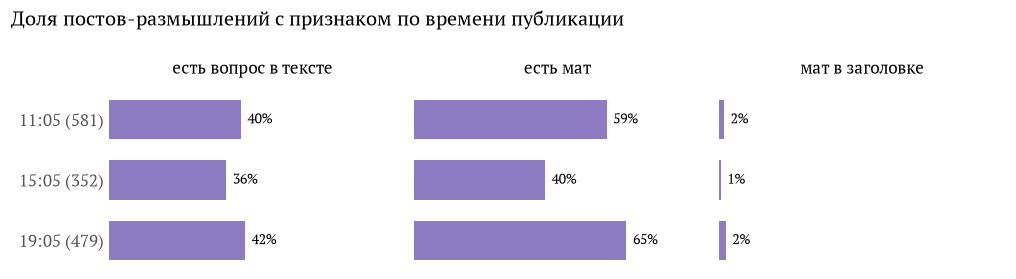

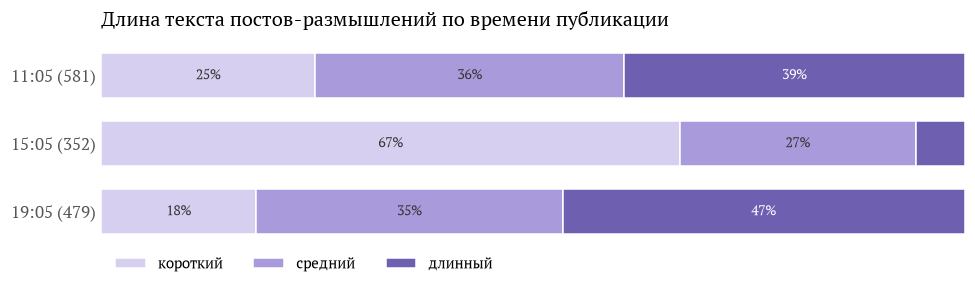

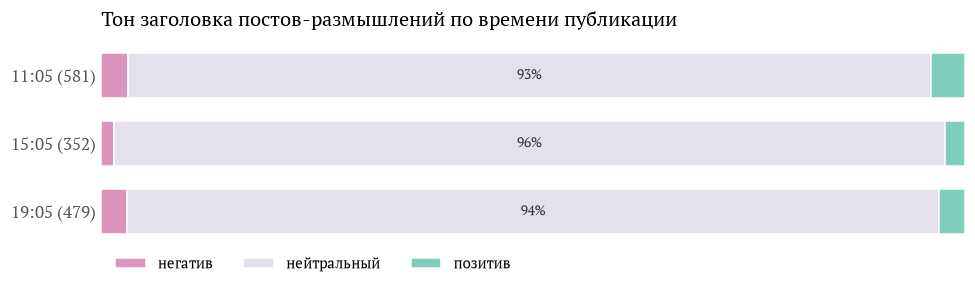

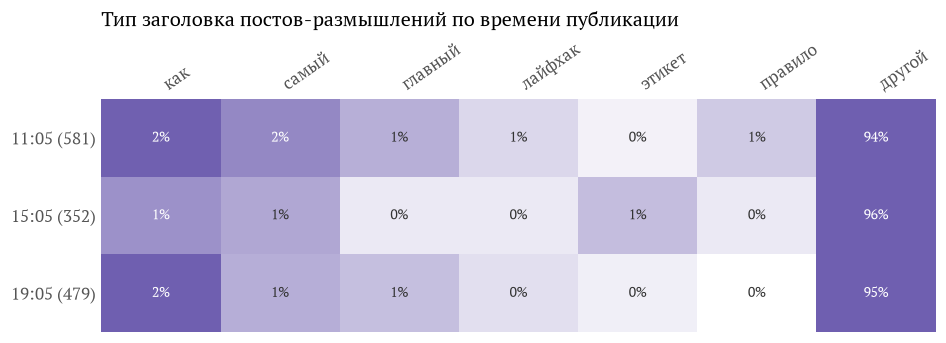

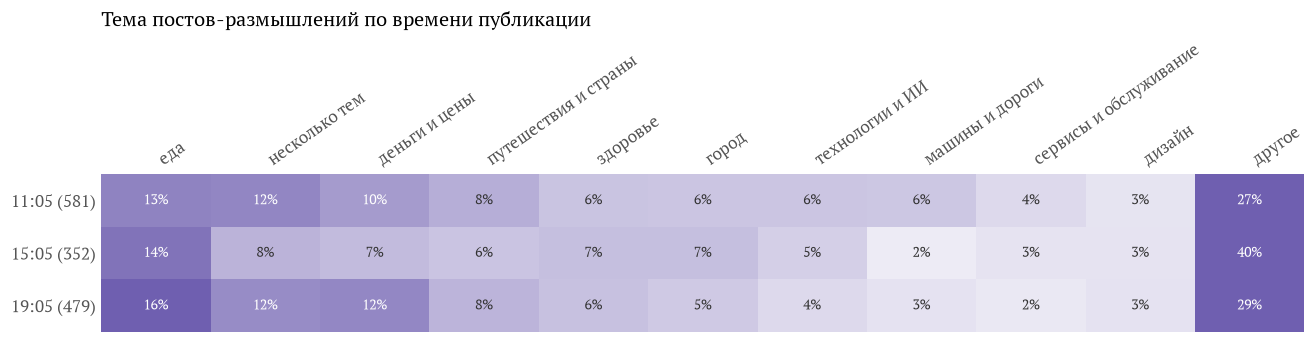

In [22]:
refl = posts[(posts["content_type"] == "reflection") & (posts["slot"] != "вне расписания")]
all_plots(refl, "slot", who="постов-размышлений", of=" постов-размышлений", by="по времени публикации")

Вопросы в тексте распределены по слотам почти одинаково. Темы тоже, кроме доли размышлений без темы: в 15:05 ни одного слова из словарей тем нет у 40% размышлений, в 11:05 и 19:05 — у 27% и 29%. Эта разница объясняется длиной, так как среди размышлений одной длины доля без темы в слотах почти одинаковая: у коротких 40–49%, у средних 28–31%. Различаются длина и мат: в 15:05 короткие 67% размышлений против 25% в 11:05 и 18% в 19:05 (медиана длины 320 символов против 616 и 696), а мат есть в 40% размышлений против 59% и 65%. Реклама на эту разницу не влияет, так как здесь сравниваются только размышления. Поэтому слоты сравниваются с учётом длины текста и мата.

#### Признаки, которые дальше не исследуются

- `title_style` — рубрика заголовка. Рубрики редкие: среди 1412 размышлений, опубликованных в 11:05, 15:05 или 19:05, у самой частой рубрики («как») 27 постов, у «самый» 18, у остальных от 5 до 11. Для групп меньше 30 постов доверительные интервалы слишком широкие, чтобы сравнивать реакции, поэтому рубрики не сравниваются.
- `title_tone` — тон заголовка. Негативных заголовков среди этих размышлений 37, позитивных 45. Словарь находит только 2 из 6 заголовков, которые при ручной разметке отмечены как негативные (каппа Коэна 0,57 на 50 заголовках). Кроме того, при чтении постов канала видно, что большая часть из них написана со злой иронией, скепсисом и сарказмом, а по заголовку их тон часто не определить (пример — «Всю власть молодым! (Нет.)»). Словарь иронию не учитывает. Распознаёт ли сарказм в таких текстах какая-нибудь готовая модель, неизвестно, а чтобы это проверить, пришлось бы вручную разметить несколько сотен постов. Поэтому тон заголовка из сравнения исключён.
- `ask_reader` — вопрос к читателю: в последнем абзаце есть знак «?» или фразы «а вы», «как вы думаете», «напишите в комментариях», «расскажите». Из 10 проверенных постов с этим признаком настоящий вопрос к читателю только в 4, в остальных вопрос риторический, стоит в реплике диалога, в скобках или в названии видео. Вместо него используется `has_question` — есть вопрос в тексте.

## Сравнение метрик с помощью bootstrap

Группа — посты с одинаковым значением признака (например, размышления, вышедшие в 15:05). Базовая группа A — группа, с которой сравнивают, сравниваемая группа B — каждая из остальных групп того же признака. Отношение медиан — медиана метрики в B, делённая на медиану в A.

Метрики: `reactions_per_1k`, `comments_per_1k`, `forwards_per_1k`, `neg_per_1k`. Посты платного периода и посты с выключенными комментариями в сравнении комментариев не участвуют, поэтому число постов указано отдельно для каждой метрики.

95%-ные доверительные интервалы (ДИ) посчитаны бутстрапом: 2000 повторов, в каждом посты выбираются с возвращением, выборка того же размера, что группа; границы ДИ — 2,5-й и 97,5-й перцентили. Для отношения медиан посты пересэмплируются внутри A и внутри B отдельно. B отличается от A, если ДИ отношения не содержит 1. Группы меньше 30 постов не сравниваются, показан только их размер.

In [23]:
# Бутстрап-ДИ медианы и отношения медиан
METRICS = {"reactions_per_1k": "реакции", "comments_per_1k": "комментарии",
           "forwards_per_1k": "пересылки", "neg_per_1k": "отрицательные реакции"}
N_BOOT, SEED, MIN_N = 2000, 2026, 30


def boot_medians(x, rng):
    """Медианы N_BOOT выборок с возвращением того же размера, что x."""
    return np.median(x[rng.integers(0, len(x), size=(N_BOOT, len(x)))], axis=1)


def ci_median(x, seed=SEED):
    """Медиана группы и её 95%-ный ДИ."""
    x = np.asarray(x, dtype=float)
    lo, hi = np.percentile(boot_medians(x, np.random.default_rng(seed)), [2.5, 97.5])
    return np.median(x), lo, hi


def ci_ratio(a, b, seed=SEED):
    """Отношение медиан B / A и его 95%-ный ДИ: посты пересэмплируются внутри A и внутри B отдельно."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    rng = np.random.default_rng(seed)
    ratios = boot_medians(b, rng) / boot_medians(a, rng)
    lo, hi = np.percentile(ratios, [2.5, 97.5])
    return np.median(b) / np.median(a), lo, hi


def ci_ratio_block(values, labels, weeks, base, group, seed=SEED):
    """То же отношение, но блочным бутстрапом по ISO-неделям: в каждом повторе с возвращением тянутся
    целые недели, и из их постов берутся A и B."""
    rng = np.random.default_rng(seed)
    uniq = np.unique(weeks)
    a_parts = [values[(weeks == w) & (labels == base)] for w in uniq]
    b_parts = [values[(weeks == w) & (labels == group)] for w in uniq]
    ratios = np.empty(N_BOOT)
    for r in range(N_BOOT):
        pick = rng.integers(0, len(uniq), len(uniq))
        ratios[r] = (np.median(np.concatenate([b_parts[k] for k in pick]))
                     / np.median(np.concatenate([a_parts[k] for k in pick])))
    lo, hi = np.percentile(ratios, [2.5, 97.5])
    return lo, hi


def pct(x, sign=False):
    """Проценты: целые, а меньше 1% — с одним знаком после запятой; минус — «−»."""
    s = f"{x:+.0f}" if abs(x) >= 1 else f"{x:+.1f}" if abs(x) >= 0.1 else f"{x:+.2f}"
    s = s.replace(".", ",").replace("-", "−")
    return s if sign else s.lstrip("+−")


def verdict(lo, hi):
    """Вывод по ДИ отношения B / A в процентах."""
    if hi < 1:
        return f"на {pct((1 - hi) * 100)}–{pct((1 - lo) * 100)}% меньше"
    if lo > 1:
        return f"на {pct((lo - 1) * 100)}–{pct((hi - 1) * 100)}% больше"
    return f"различие не обнаружено (от {pct((lo - 1) * 100, True)}% до {pct((hi - 1) * 100, True)}%)"


def compare(df, labels, base, groups, skip=None):
    """Сравнение каждой группы из groups с базовой группой base по всем метрикам.
    labels — значение признака у каждого поста df; skip — {группа: причина}, такие группы только показываются."""
    skip = skip or {}
    labels = pd.Series(labels, index=df.index).astype(str).to_numpy()
    rows = []
    for m in METRICS:
        ok = df[m].notna().to_numpy()
        vals, lab = df[m].to_numpy(dtype=float)[ok], labels[ok]
        a = vals[lab == base]
        med, lo, hi = ci_median(a)
        rows.append({"метрика": METRICS[m], "группа": base, "постов": len(a), "медиана": med,
                     "ДИ медианы": f"{lo:.2f}–{hi:.2f}", "вывод относительно A": "базовая группа A"})
        for g in groups:
            b = vals[lab == g]
            row = {"метрика": METRICS[m], "группа": g, "постов": len(b),
                   "медиана": np.median(b) if len(b) else np.nan}
            if g in skip or len(b) < MIN_N or len(a) < MIN_N:
                row["вывод относительно A"] = skip.get(g, f"меньше {MIN_N} постов, не сравнивается")
            else:
                _, blo, bhi = ci_median(b)
                ratio, rlo, rhi = ci_ratio(a, b)
                row.update({"ДИ медианы": f"{blo:.2f}–{bhi:.2f}", "B / A": ratio, "ДИ B / A": (rlo, rhi),
                            "вывод относительно A": verdict(rlo, rhi)})
            rows.append(row)
    return pd.DataFrame(rows)


def show_compare(res, title):
    """Таблица и график: отличие B от A в процентах с 95%-ным ДИ, по панели на метрику."""
    table = res.assign(
        медиана=res["медиана"].round(2),
        **{"B / A − 1, %": res["B / A"].map(lambda r: pct((r - 1) * 100, True) if pd.notna(r) else ""),
           "ДИ B / A − 1, %": res["ДИ B / A"].map(
               lambda c: f"{pct((c[0] - 1) * 100, True)} … {pct((c[1] - 1) * 100, True)}" if isinstance(c, tuple) else "")}
    ).drop(columns=["B / A", "ДИ B / A"]).fillna("").set_index(["метрика", "группа"])
    display(Markdown(f"**{title}**"))
    with pd.option_context("display.max_colwidth", None):
        display(table)

    cmp = res[res["ДИ B / A"].map(lambda c: isinstance(c, tuple))]
    if cmp.empty:
        return
    base = res.loc[res["вывод относительно A"] == "базовая группа A", "группа"].iat[0]
    groups = list(dict.fromkeys(cmp["группа"]))
    y = np.arange(len(groups))
    fig, axes = plt.subplots(1, len(METRICS), figsize=(12, 0.45 * len(groups) + 1.6), sharey=True)
    for ax, m in zip(axes, METRICS.values()):
        d = cmp[cmp["метрика"] == m].set_index("группа").reindex(groups)
        for yi, (g, r) in zip(y, d.iterrows()):
            if pd.isna(r["B / A"]):
                continue
            lo, hi = r["ДИ B / A"]
            sig = hi < 1 or lo > 1
            ax.plot([(lo - 1) * 100, (hi - 1) * 100], [yi, yi], color=PALETTE[0], lw=2)
            ax.plot((r["B / A"] - 1) * 100, yi, "o", ms=7, color=PALETTE[0],
                    markerfacecolor=PALETTE[0] if sig else "white")
        ax.axvline(0, color="#888888", lw=1)
        ax.set_title(m, fontsize=11, loc="center")
        ax.set_xlabel("B / A − 1, %")
        ax.grid(axis="y", visible=False)
    n = cmp.groupby("группа")["постов"].max()
    axes[0].set_yticks(y, [f"{g} ({n[g]})" for g in groups])
    axes[0].invert_yaxis()
    fig.suptitle(f"{title}: отличие от группы «{base}» с 95%-ным ДИ (закрашено — ДИ не содержит 0)",
                 x=0.01, ha="left", fontsize=13)
    fig.tight_layout()
    plt.show()

**Тип контента, все посты окна**

постов  медиана   ДИ медианы  \
метрика               группа                                       
реакции               reflection      1424    14.85  14.34–15.25   
                      video            375     4.70    4.56–4.82   
                      other            226    12.50  10.99–13.64   
                      ad               209     7.50    7.00–8.12   
                      own_products      45     6.16    5.62–7.83   
комментарии           reflection      1004     1.24    1.21–1.28   
                      video            273     0.54    0.52–0.60   
                      other            149     1.14    1.01–1.44   
                      ad               161     0.57    0.49–0.64   
                      own_products      31     0.67    0.51–0.83   
пересылки             reflection      1424     1.76    1.66–1.85   
                      video            375     1.62    1.57–1.66   
                      other            226     1.67    1.34–1.93   
                      ad               209     0.83    0.67–0.98   
                      own_products      45     1.45    1.26–1.90   
отрицательные реакции reflection      1424     0.38    0.36–0.41   
                      video            375     0.40    0.36–0.44   
                      other            226     0.70    0.59–0.89   
                      ad               209     1.83    1.68–2.18   
                      own_products      45     0.53    0.43–0.70   

                                                        вывод относительно A  \
метрика               группа                                                   
реакции               reflection                            базовая группа A   
                      video                                 на 67–70% меньше   
                      other                                  на 7–25% меньше   
                      ad                                    на 45–53% меньше   
                      own_products                          на 46–62% меньше   
комментарии           reflection                            базовая группа A   
                      video                                 на 52–58% меньше   
                      other         различие не обнаружено (от −19% до +17%)   
                      ad                                    на 48–61% меньше   
                      own_products                          на 33–59% меньше   
пересылки             reflection                            базовая группа A   
                      video                                  на 1–13% меньше   
                      other         различие не обнаружено (от −23% до +12%)   
                      ad                                    на 44–63% меньше   
                      own_products  различие не обнаружено (от −29% до +13%)   
отрицательные реакции reflection                            базовая группа A   
                      video          различие не обнаружено (от −9% до +17%)   
                      other                                на 54–136% больше   
                      ad                                  на 326–480% больше   
                      own_products                          на 11–83% больше   

                                   B / A − 1, % ДИ B / A − 1, %  
метрика               группа                                     
реакции               reflection                                 
                      video                 −68       −70 … −67  
                      other                 −16        −25 … −7  
                      ad                    −50       −53 … −45  
                      own_products          −59       −62 … −46  
комментарии           reflection                                 
                      video                 −56       −58 … −52  
                      other                  −8       −19 … +17  
                      ad                    −54       −61 … −48  
                      own_products          −46     

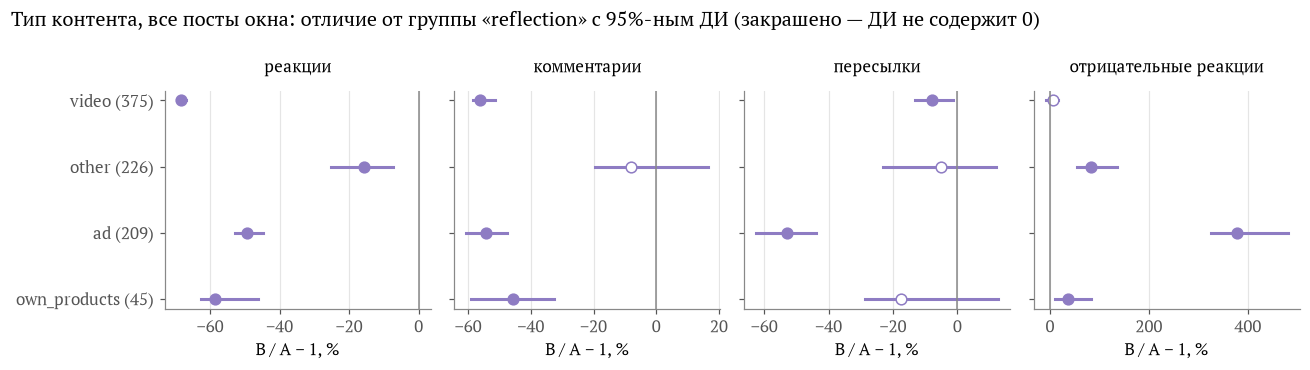

In [24]:
# 1. Все посты окна по типу контента
res_content = compare(posts, posts["content_type"], "reflection", ["video", "other", "ad", "own_products"])
show_compare(res_content, "Тип контента, все посты окна")

#### Тип контента

Больше всего реакций собирают размышления: медиана 14,9 на 1000 просмотров. У видео реакций на 67–70% меньше, у рекламы на 45–53% меньше, у своих продуктов на 46–62% меньше, у прочих постов на 7–25% меньше. Посты с видео ведут на другие площадки, поэтому реакции на само видео здесь не отражаются.

- Комментариев у видео, рекламы и своих продуктов примерно вдвое меньше, чем у размышлений. У прочих постов различие не обнаружено (от −19% до +17%).
- Пересылок у рекламы на 44–63% меньше, чем у размышлений. У остальных типов пересылок почти столько же (у видео на 1–13% меньше).
- Отрицательных реакций у рекламы в 4,8 раза больше, чем у размышлений (1,83 против 0,38 на 1000 просмотров), у прочих постов на 54–136% больше.

**Слот, все размышления**

постов  медиана   ДИ медианы  \
метрика               группа                                 
реакции               11:05      581    15.10  14.32–15.62   
                      15:05      352    13.51  12.80–14.39   
                      19:05      479    15.25  14.63–16.02   
комментарии           11:05      407     1.15    1.10–1.21   
                      15:05      253     1.19    1.08–1.31   
                      19:05      333     1.39    1.29–1.55   
пересылки             11:05      581     1.85    1.73–2.04   
                      15:05      352     1.27    1.14–1.43   
                      19:05      479     2.04    1.83–2.22   
отрицательные реакции 11:05      581     0.37    0.35–0.41   
                      15:05      352     0.42    0.38–0.47   
                      19:05      479     0.37    0.33–0.41   

                                                  вывод относительно A  \
метрика               группа                                             
реакции               11:05                           базовая группа A   
                      15:05                            на 2–16% меньше   
                      19:05     различие не обнаружено (от −4% до +8%)   
комментарии           11:05                           базовая группа A   
                      15:05    различие не обнаружено (от −7% до +15%)   
                      19:05                           на 11–37% больше   
пересылки             11:05                           базовая группа A   
                      15:05                           на 21–41% меньше   
                      19:05    различие не обнаружено (от −5% до +22%)   
отрицательные реакции 11:05                           базовая группа A   
                      15:05    различие не обнаружено (от −2% до +28%)   
                      19:05   различие не обнаружено (от −14% до +13%)   

                             B / A − 1, % ДИ B / A − 1, %  
метрика               группа                               
реакции               11:05                                
                      15:05           −11        −16 … −2  
                      19:05          +1,0         −4 … +8  
комментарии           11:05                                
                      15:05            +3        −7 … +15  
                      19:05           +21       +11 … +37  
пересылки             11:05                                
                      15:05           −31       −41 … −21  
                      19:05           +10        −5 … +22  
отрицательные реакции 11:05                                
                      15:05           +13        −2 … +28  
                      19:05          +0,3       −14 … +13

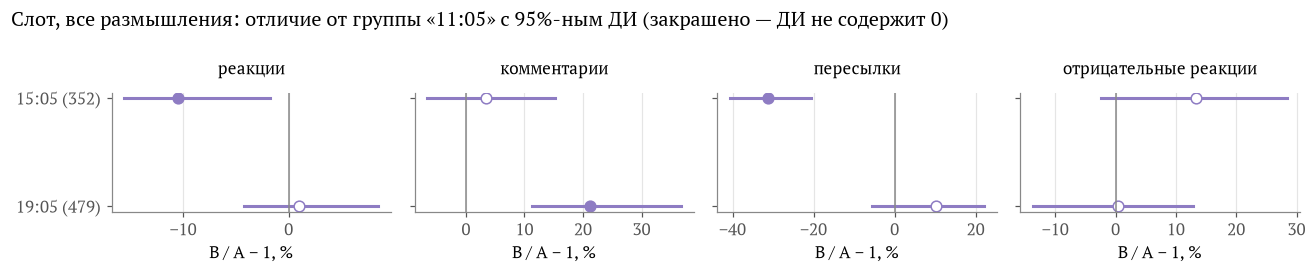

**Слот, размышления длины «короткий»**

постов  медиана   ДИ медианы  \
метрика               группа                                 
реакции               11:05      144    13.66  12.84–15.18   
                      15:05      236    12.78  12.09–13.58   
                      19:05       86    13.22  12.29–14.45   
комментарии           11:05      104     1.25    1.11–1.48   
                      15:05      169     1.18    1.06–1.30   
                      19:05       52     1.68    1.32–2.24   
пересылки             11:05      144     1.39    1.02–1.61   
                      15:05      236     1.12    1.00–1.33   
                      19:05       86     1.27    0.99–1.53   
отрицательные реакции 11:05      144     0.35    0.31–0.40   
                      15:05      236     0.43    0.37–0.48   
                      19:05       86     0.37    0.31–0.48   

                                                  вывод относительно A  \
метрика               группа                                             
реакции               11:05                           базовая группа A   
                      15:05    различие не обнаружено (от −15% до +3%)   
                      19:05    различие не обнаружено (от −12% до +8%)   
комментарии           11:05                           базовая группа A   
                      15:05    различие не обнаружено (от −23% до +9%)   
                      19:05                          на 0,9–88% больше   
пересылки             11:05                           базовая группа A   
                      15:05   различие не обнаружено (от −33% до +12%)   
                      19:05   различие не обнаружено (от −29% до +31%)   
отрицательные реакции 11:05                           базовая группа A   
                      15:05                            на 2–48% больше   
                      19:05   различие не обнаружено (от −13% до +43%)   

                             B / A − 1, % ДИ B / A − 1, %  
метрика               группа                               
реакции               11:05                                
                      15:05            −6        −15 … +3  
                      19:05            −3        −12 … +8  
комментарии           11:05                                
                      15:05            −5        −23 … +9  
                      19:05           +35      +0,9 … +88  
пересылки             11:05                                
                      15:05           −19       −33 … +12  
                      19:05            −8       −29 … +31  
отрицательные реакции 11:05                                
                      15:05           +23        +2 … +48  
                      19:05            +7       −13 … +43

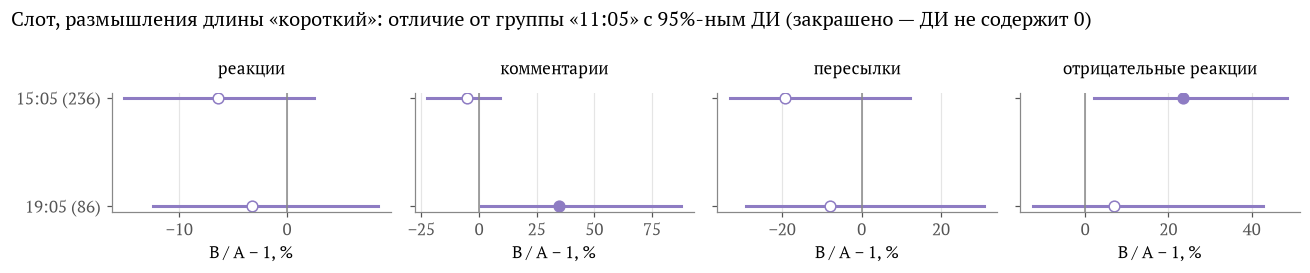

**Слот, размышления длины «средний»**

постов  медиана   ДИ медианы  \
метрика               группа                                 
реакции               11:05      208    15.74  14.77–16.68   
                      15:05       96    15.28  13.99–16.48   
                      19:05      170    16.09  14.83–16.97   
комментарии           11:05      145     1.15    1.07–1.27   
                      15:05       68     1.27    1.10–1.42   
                      19:05      117     1.52    1.31–1.71   
пересылки             11:05      208     1.79    1.60–2.03   
                      15:05       96     1.73    1.33–2.04   
                      19:05      170     1.77    1.50–2.07   
отрицательные реакции 11:05      208     0.43    0.37–0.49   
                      15:05       96     0.39    0.32–0.49   
                      19:05      170     0.37    0.30–0.44   

                                                  вывод относительно A  \
метрика               группа                                             
реакции               11:05                           базовая группа A   
                      15:05    различие не обнаружено (от −13% до +7%)   
                      19:05    различие не обнаружено (от −8% до +10%)   
комментарии           11:05                           базовая группа A   
                      15:05    различие не обнаружено (от −8% до +26%)   
                      19:05                           на 10–49% больше   
пересылки             11:05                           базовая группа A   
                      15:05   различие не обнаружено (от −27% до +18%)   
                      19:05   различие не обнаружено (от −18% до +21%)   
отрицательные реакции 11:05                           базовая группа A   
                      15:05   различие не обнаружено (от −28% до +23%)   
                      19:05   различие не обнаружено (от −33% до +10%)   

                             B / A − 1, % ДИ B / A − 1, %  
метрика               группа                               
реакции               11:05                                
                      15:05            −3        −13 … +7  
                      19:05            +2        −8 … +10  
комментарии           11:05                                
                      15:05           +10        −8 … +26  
                      19:05           +32       +10 … +49  
пересылки             11:05                                
                      15:05            −3       −27 … +18  
                      19:05            −1       −18 … +21  
отрицательные реакции 11:05                                
                      15:05            −8       −28 … +23  
                      19:05           −13       −33 … +10

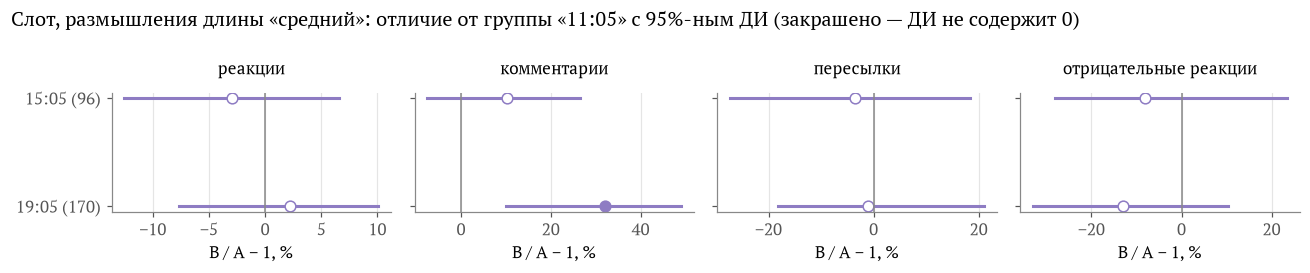

**Слот, размышления длины «длинный»**

постов  медиана   ДИ медианы  \
метрика               группа                                 
реакции               11:05      229    15.14  14.07–16.07   
                      15:05       20    13.42                
                      19:05      223    15.71  14.86–16.89   
комментарии           11:05      158     1.10    1.01–1.18   
                      15:05       16     0.98                
                      19:05      164     1.28    1.20–1.45   
пересылки             11:05      229     2.36    2.09–2.61   
                      15:05       20     1.89                
                      19:05      223     2.42    2.24–2.58   
отрицательные реакции 11:05      229     0.35    0.30–0.42   
                      15:05       20     0.41                
                      19:05      223     0.37    0.32–0.41   

                                                  вывод относительно A  \
метрика               группа                                             
реакции               11:05                           базовая группа A   
                      15:05          меньше 30 постов, не сравнивается   
                      19:05    различие не обнаружено (от −4% до +15%)   
комментарии           11:05                           базовая группа A   
                      15:05          меньше 30 постов, не сравнивается   
                      19:05                            на 7–36% больше   
пересылки             11:05                           базовая группа A   
                      15:05          меньше 30 постов, не сравнивается   
                      19:05   различие не обнаружено (от −10% до +21%)   
отрицательные реакции 11:05                           базовая группа A   
                      15:05          меньше 30 постов, не сравнивается   
                      19:05   различие не обнаружено (от −15% до +29%)   

                             B / A − 1, % ДИ B / A − 1, %  
метрика               группа                               
реакции               11:05                                
                      15:05                                
                      19:05            +4        −4 … +15  
комментарии           11:05                                
                      15:05                                
                      19:05           +17        +7 … +36  
пересылки             11:05                                
                      15:05                                
                      19:05            +3       −10 … +21  
отрицательные реакции 11:05                                
                      15:05                                
                      19:05            +4       −15 … +29

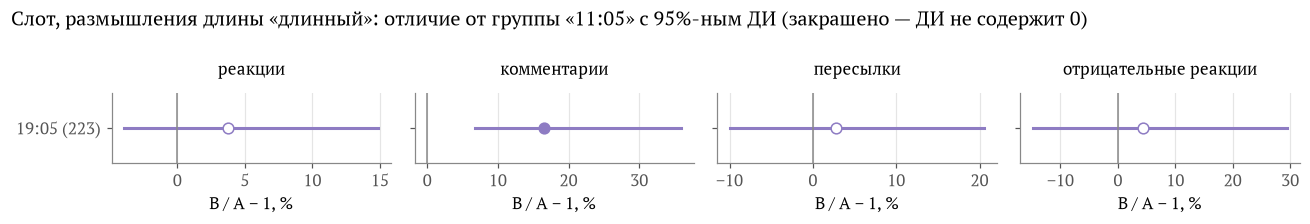

In [25]:
# 2.1. Слот: сначала по всем размышлениям, затем внутри каждой корзины длины, так как длина зависит от слота
res_slot = {"все размышления": compare(refl, refl["slot"], "11:05", ["15:05", "19:05"])}
show_compare(res_slot["все размышления"], "Слот, все размышления")
for b in ["короткий", "средний", "длинный"]:
    d = refl[refl["text_len_bin"] == b]
    res_slot[b] = compare(d, d["slot"], "11:05", ["15:05", "19:05"])
    show_compare(res_slot[b], f"Слот, размышления длины «{b}»")

#### Время публикации

По всем размышлениям в 15:05 реакций на 2–16% меньше, чем в 11:05, а пересылок на 21–41% меньше. Внутри коротких и средних размышлений разница по реакциям почти исчезает (−6% и −3%, ДИ содержат ноль), поэтому она объясняется тем, что в 15:05 выходят более короткие тексты. Разница по пересылкам у коротких размышлений остаётся заметной (−19%, ДИ от −33% до +12%), поэтому одной длиной её объяснить нельзя.

Комментариев в 19:05 больше, чем в 11:05: на 11–37% по всем размышлениям. Эта разница сохраняется внутри каждой корзины длины (на 0,9–88% у коротких, на 10–49% у средних, на 7–36% у длинных), поэтому длиной текста она не объясняется. Это единственная связь времени публикации с реакцией аудитории, которая осталась после учёта длины.

У коротких размышлений в 15:05 отрицательных реакций на 2–48% больше, чем в 11:05. Нижняя граница ДИ близка к нулю, и в других корзинах длины такой разницы нет, поэтому на это различие не опираемся.

**Будни и выходные, размышления**

постов  медиана   ДИ медианы  \
метрика               группа                                   
реакции               будни       1110    14.85  14.34–15.31   
                      выходные     302    14.53  13.93–15.32   
комментарии           будни        786     1.22    1.17–1.27   
                      выходные     207     1.35    1.24–1.53   
пересылки             будни       1110     1.83    1.72–1.93   
                      выходные     302     1.53    1.38–1.76   
отрицательные реакции будни       1110     0.39    0.36–0.41   
                      выходные     302     0.36    0.33–0.42   

                                                   вывод относительно A  \
метрика               группа                                              
реакции               будни                            базовая группа A   
                      выходные   различие не обнаружено (от −7% до +5%)   
комментарии           будни                            базовая группа A   
                      выходные                          на 1–27% больше   
пересылки             будни                            базовая группа A   
                      выходные                          на 3–25% меньше   
отрицательные реакции будни                            базовая группа A   
                      выходные  различие не обнаружено (от −18% до +8%)   

                               B / A − 1, % ДИ B / A − 1, %  
метрика               группа                                 
реакции               будни                                  
                      выходные           −2         −7 … +5  
комментарии           будни                                  
                      выходные          +11        +1 … +27  
пересылки             будни                                  
                      выходные          −16        −25 … −3  
отрицательные реакции будни                                  
                      выходные           −6        −18 … +8

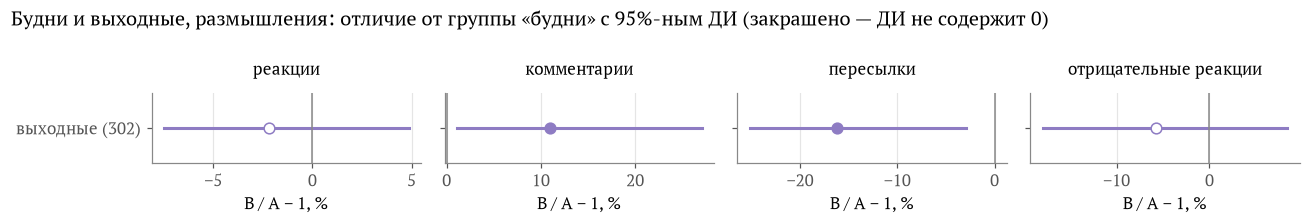

**День недели, размышления**

постов  медиана   ДИ медианы  \
метрика               группа                                 
реакции               пн         242    15.09  13.99–15.50   
                      вт         217    15.70  14.30–16.48   
                      ср         231    14.34  13.30–15.94   
                      чт         220    14.43  13.64–15.31   
                      пт         200    14.96  13.96–15.68   
                      сб         138    14.28  13.29–15.58   
                      вс         164    14.67  13.86–15.43   
комментарии           пн         173     1.21    1.12–1.30   
                      вт         152     1.19    1.07–1.29   
                      ср         168     1.28    1.19–1.39   
                      чт         154     1.23    1.12–1.39   
                      пт         139     1.11    1.03–1.33   
                      сб          94     1.28    1.19–1.52   
                      вс         113     1.42    1.25–1.71   
пересылки             пн         242     1.70    1.50–1.95   
                      вт         217     2.16    1.84–2.38   
                      ср         231     1.72    1.52–1.97   
                      чт         220     1.79    1.59–2.20   
                      пт         200     1.77    1.59–1.97   
                      сб         138     1.56    1.30–1.88   
                      вс         164     1.49    1.31–1.77   
отрицательные реакции пн         242     0.40    0.33–0.47   
                      вт         217     0.37    0.34–0.42   
                      ср         231     0.39    0.36–0.45   
                      чт         220     0.40    0.34–0.47   
                      пт         200     0.38    0.32–0.44   
                      сб         138     0.34    0.30–0.42   
                      вс         164     0.38    0.33–0.46   

                                                    вывод относительно A  \
метрика               группа                                               
реакции               пн                                базовая группа A   
                      вт         различие не обнаружено (от −6% до +14%)   
                      ср         различие не обнаружено (от −12% до +9%)   
                      чт         различие не обнаружено (от −10% до +5%)   
                      пт          различие не обнаружено (от −8% до +9%)   
                      сб         различие не обнаружено (от −11% до +9%)   
                      вс          различие не обнаружено (от −8% до +8%)   
комментарии           пн                                базовая группа A   
                      вт        различие не обнаружено (от −14% до +10%)   
                      ср         различие не обнаружено (от −6% до +19%)   
                      чт        различие не обнаружено (от −10% до +20%)   
                      пт        различие не обнаружено (от −17% до +10%)   
                      сб         различие не обнаружено (от −5% до +27%)   
                      вс      различие не обнаружено (от −0,00% до +41%)   
пересылки             пн                                базовая группа A   
                      вт                                 на 3–50% больше   
                      ср        различие не обнаружено (от −16% до +24%)   
                      чт        различие не обнаружено (от −12% до +36%)   
                      пт        различие не обнаружено (от −12% до +24%)   
                      сб        различие не обнаружено (от −26% до +19%)   
                      вс         различие не обнаружено (от −26% до +8%)   
отрицательные реакции пн                                базовая группа A   
                      вт        различие не обнаружено (от −24% до +17%)   
                      ср        различие не обнаружено (от −19% до +23%)   
                      чт        различие не обнаружено (от −21% до +28%)   
                      пт        различие не обнаружено (от −26% до +20%)   
                      сб        различие 

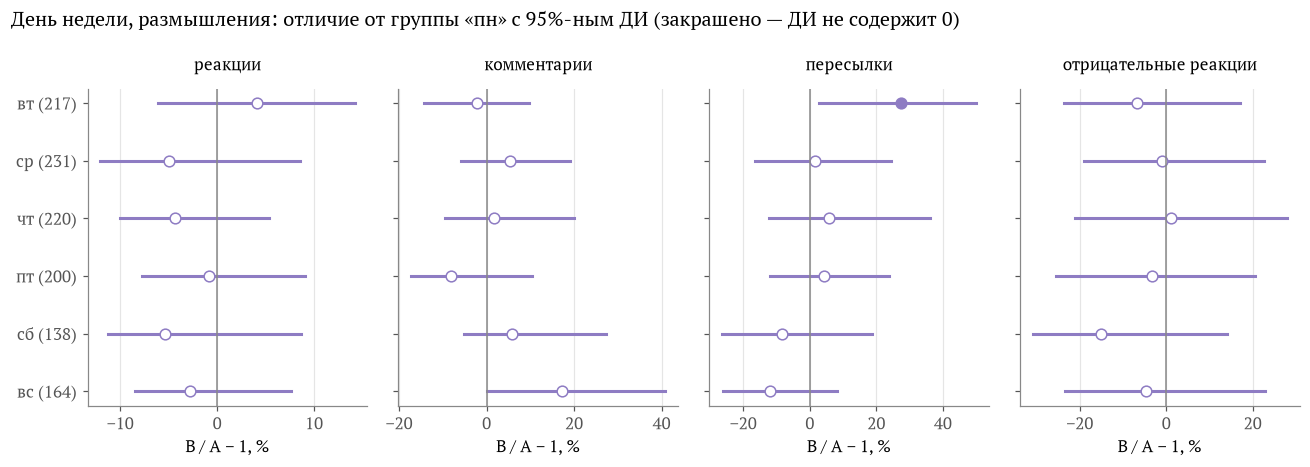

**Номер поста за день, размышления**

постов  медиана   ДИ медианы  \
метрика               группа                                 
реакции               1          477    15.14  14.31–15.58   
                      2          446    14.66  13.98–15.31   
                      3          367    14.27  13.60–15.19   
                      4+         122    15.36  14.39–16.79   
комментарии           1          337     1.17    1.12–1.25   
                      2          311     1.22    1.16–1.29   
                      3          265     1.36    1.24–1.51   
                      4+          80     1.35    1.22–1.53   
пересылки             1          477     1.83    1.66–2.01   
                      2          446     1.59    1.44–1.83   
                      3          367     1.75    1.55–1.97   
                      4+         122     1.94    1.52–2.49   
отрицательные реакции 1          477     0.38    0.35–0.42   
                      2          446     0.40    0.36–0.44   
                      3          367     0.40    0.35–0.46   
                      4+         122     0.34    0.30–0.38   

                                                  вывод относительно A  \
метрика               группа                                             
реакции               1                               базовая группа A   
                      2         различие не обнаружено (от −9% до +4%)   
                      3        различие не обнаружено (от −11% до +3%)   
                      4+       различие не обнаружено (от −5% до +12%)   
комментарии           1                               базовая группа A   
                      2        различие не обнаружено (от −4% до +12%)   
                      3                                на 3–28% больше   
                      4+                               на 2–33% больше   
пересылки             1                               базовая группа A   
                      2        различие не обнаружено (от −23% до +3%)   
                      3       различие не обнаружено (от −18% до +12%)   
                      4+      различие не обнаружено (от −16% до +39%)   
отрицательные реакции 1                               базовая группа A   
                      2       различие не обнаружено (от −11% до +19%)   
                      3       различие не обнаружено (от −14% до +22%)   
                      4+       различие не обнаружено (от −24% до +3%)   

                             B / A − 1, % ДИ B / A − 1, %  
метрика               группа                               
реакции               1                                    
                      2                −3         −9 … +4  
                      3                −6        −11 … +3  
                      4+               +1        −5 … +12  
комментарии           1                                    
                      2                +4        −4 … +12  
                      3               +16        +3 … +28  
                      4+              +15        +2 … +33  
пересылки             1                                    
                      2               −13        −23 … +3  
                      3                −5       −18 … +12  
                      4+               +6       −16 … +39  
отрицательные реакции 1                                    
                      2                +6       −11 … +19  
                      3                +5       −14 … +22  
                      4+               −9        −24 … +3

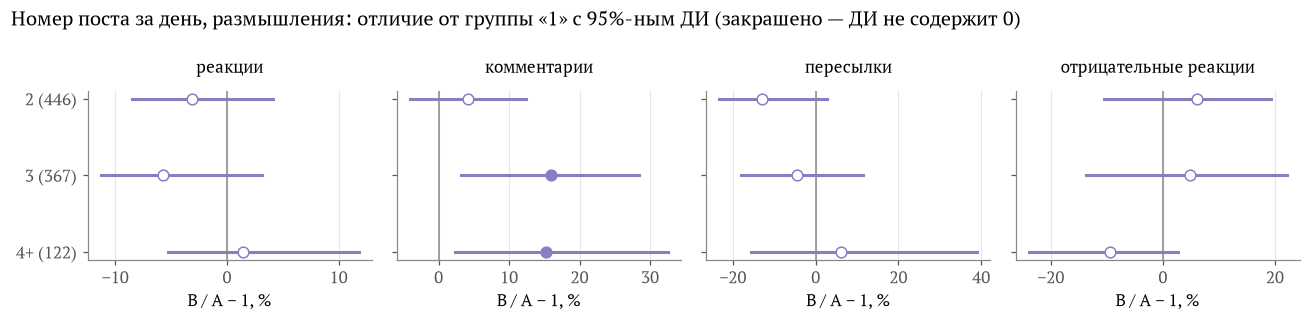

**Интервал до предыдущего поста, размышления**

постов  медиана   ДИ медианы  \
метрика               группа                                    
реакции               3,5–4,5 ч     645    14.34  13.83–14.97   
                      < 1 ч          18    15.45                
                      1–3,5 ч        83    13.98  12.84–16.90   
                      > 4,5 ч       666    15.20  14.57–15.64   
комментарии           3,5–4,5 ч     465     1.29    1.23–1.37   
                      < 1 ч          11     1.19                
                      1–3,5 ч        49     1.20    0.97–1.37   
                      > 4,5 ч       468     1.21    1.15–1.27   
пересылки             3,5–4,5 ч     645     1.63    1.52–1.83   
                      < 1 ч          18     1.86                
                      1–3,5 ч        83     1.82    1.52–2.36   
                      > 4,5 ч       666     1.84    1.69–1.99   
отрицательные реакции 3,5–4,5 ч     645     0.39    0.36–0.41   
                      < 1 ч          18     0.59                
                      1–3,5 ч        83     0.32    0.27–0.38   
                      > 4,5 ч       666     0.38    0.36–0.42   

                                                      вывод относительно A  \
метрика               группа                                                 
реакции               3,5–4,5 ч                           базовая группа A   
                      < 1 ч              меньше 30 постов, не сравнивается   
                      1–3,5 ч     различие не обнаружено (от −12% до +18%)   
                      > 4,5 ч                           на 0,04–11% больше   
комментарии           3,5–4,5 ч                           базовая группа A   
                      < 1 ч              меньше 30 постов, не сравнивается   
                      1–3,5 ч      различие не обнаружено (от −26% до +4%)   
                      > 4,5 ч    различие не обнаружено (от −13% до +1,0%)   
пересылки             3,5–4,5 ч                           базовая группа A   
                      < 1 ч              меньше 30 постов, не сравнивается   
                      1–3,5 ч     различие не обнаружено (от −11% до +47%)   
                      > 4,5 ч      различие не обнаружено (от −2% до +26%)   
отрицательные реакции 3,5–4,5 ч                           базовая группа A   
                      < 1 ч              меньше 30 постов, не сравнивается   
                      1–3,5 ч      различие не обнаружено (от −31% до +1%)   
                      > 4,5 ч     различие не обнаружено (от −12% до +12%)   

                                B / A − 1, % ДИ B / A − 1, %  
метрика               группа                                  
реакции               3,5–4,5 ч                               
                      < 1 ч                                   
                      1–3,5 ч             −3       −12 … +18  
                      > 4,5 ч             +6     +0,04 … +11  
комментарии           3,5–4,5 ч                               
                      < 1 ч                                   
                      1–3,5 ч             −7        −26 … +4  
                      > 4,5 ч             −6      −13 … +1,0  
пересылки             3,5–4,5 ч                               
                      < 1 ч                                   
                      1–3,5 ч            +12       −11 … +47  
                      > 4,5 ч            +13        −2 … +26  
отрицательные реакции 3,5–4,5 ч                               
                      < 1 ч                                   
                      1–3,5 ч            −18        −31 … +1  
                      > 4,5 ч             −4       −12 … +12

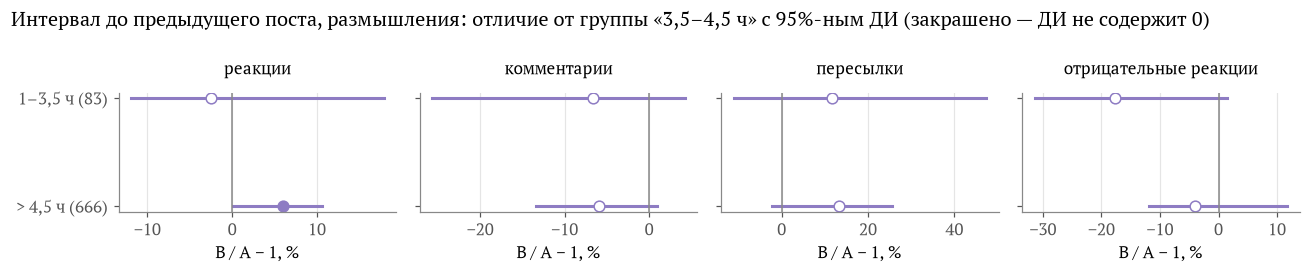

In [26]:
# 2.2. Будни и выходные, дни недели
weekend = np.where(refl["weekday"] >= 5, "выходные", "будни")
show_compare(compare(refl, weekend, "будни", ["выходные"]), "Будни и выходные, размышления")
day = refl["weekday"].map(dict(enumerate(WEEKDAYS)))
show_compare(compare(refl, day, "пн", WEEKDAYS[1:]), "День недели, размышления")

# 2.3. Номер поста за день, 4-й и дальше — одна группа
num = np.where(refl["post_num_day"] >= 4, "4+", refl["post_num_day"].astype(str))
show_compare(compare(refl, num, "1", ["2", "3", "4+"]), "Номер поста за день, размышления")

# 2.4. Интервал до предыдущего поста, A — обычный промежуток между слотами (3,5–4,5 ч)
gap = pd.cut(refl["gap_prev_h"], [-np.inf, 1, 3.5, 4.5, np.inf], right=False,
             labels=["< 1 ч", "1–3,5 ч", "3,5–4,5 ч", "> 4,5 ч"])
show_compare(compare(refl, gap, "3,5–4,5 ч", ["< 1 ч", "1–3,5 ч", "> 4,5 ч"]),
             "Интервал до предыдущего поста, размышления")

In [27]:
# Номер поста за день и слот у размышлений: первый пост дня почти всегда в 11:05, третий и дальше — в 19:05
num_slot = pd.crosstab(pd.Series(num, index=refl.index, name="номер поста за день"), refl["slot"])
share = num_slot.div(num_slot.sum(axis=1), axis=0) * 100
display(Markdown("**Размышления: слот по номеру поста за день, доля строки (в скобках — число постов)**"))
display(share.round().astype(int).astype(str) + "% (" + num_slot.astype(str) + ")")

**Размышления: слот по номеру поста за день, доля строки (в скобках — число постов)**

slot,11:05,15:05,19:05
номер поста за день,,,
1,95% (454),4% (21),0% (2)
2,26% (115),52% (234),22% (97)
3,3% (12),23% (84),74% (271)
4+,0% (0),11% (13),89% (109)


In [28]:
# Интервал до предыдущего поста и слот у размышлений: интервал больше 4,5 ч в основном у постов в 11:05
gap_long = pd.Series(np.where(refl["gap_prev_h"] > 4.5, "> 4,5 ч", "≤ 4,5 ч"), index=refl.index,
                     name="интервал до предыдущего поста")
gap_slot = pd.crosstab(gap_long, refl["slot"])
share = gap_slot.div(gap_slot.sum(axis=1), axis=0) * 100
display(Markdown("**Размышления: слот по интервалу до предыдущего поста, доля строки (в скобках — число постов)**"))
display(share.round().astype(int).astype(str) + "% (" + gap_slot.astype(str) + ")")

share_col = gap_slot.div(gap_slot.sum(axis=0), axis=1) * 100
display(Markdown("**Те же размышления: интервал внутри каждого слота, доля столбца (в скобках — число постов)**"))
display(share_col.round().astype(int).astype(str) + "% (" + gap_slot.astype(str) + ")")

**Размышления: слот по интервалу до предыдущего поста, доля строки (в скобках — число постов)**

slot,11:05,15:05,19:05
интервал до предыдущего поста,,,
"> 4,5 ч",79% (524),6% (40),15% (102)
"≤ 4,5 ч",8% (57),42% (312),51% (377)


**Те же размышления: интервал внутри каждого слота, доля столбца (в скобках — число постов)**

slot,11:05,15:05,19:05
интервал до предыдущего поста,,,
"> 4,5 ч",90% (524),11% (40),21% (102)
"≤ 4,5 ч",10% (57),89% (312),79% (377)


#### День недели, номер поста за день, интервал до предыдущего поста

- Реакции и отрицательные реакции не различаются ни между днями недели, ни между буднями и выходными.
- В выходные комментариев на 1–27% больше, а пересылок на 3–25% меньше, чем в будни. По отдельным дням из 24 сравнений с понедельником различие есть только в одном: во вторник пересылок на 3–50% больше. При таком числе сравнений одно различие может появиться случайно, поэтому на него не опираемся.
- Третий и четвёртый посты дня собирают больше комментариев, чем первый (на 3–28% и на 2–33%). Номер поста за день почти повторяет слот: третье размышление дня в 74% случаев выходит в 19:05 (таблица выше). Поэтому в модель он не входит.
- У размышлений, вышедших больше чем через 4,5 часа после предыдущего поста, реакций на 0,04–11% больше, чем при обычном интервале 3,5–4,5 часа. Нижняя граница ДИ почти ноль, поэтому разница слабая. По остальным метрикам интервал с реакцией аудитории не связан. Размышлений, вышедших меньше чем через час после предыдущего поста, 18, их не сравниваем.

**Длина текста, размышления**

постов  медиана   ДИ медианы  \
метрика               группа                                   
реакции               средний      474    15.61  15.07–16.31   
                      короткий     466    13.16  12.76–13.90   
                      длинный      472    15.31  14.66–16.02   
комментарии           средний      330     1.28    1.23–1.37   
                      короткий     325     1.25    1.18–1.38   
                      длинный      338     1.18    1.11–1.26   
пересылки             средний      474     1.77    1.60–1.91   
                      короткий     466     1.22    1.08–1.37   
                      длинный      472     2.36    2.21–2.55   
отрицательные реакции средний      474     0.40    0.36–0.45   
                      короткий     466     0.39    0.35–0.43   
                      длинный      472     0.37    0.33–0.40   

                                                    вывод относительно A  \
метрика               группа                                               
реакции               средний                           базовая группа A   
                      короткий                          на 11–20% меньше   
                      длинный     различие не обнаружено (от −8% до +3%)   
комментарии           средний                           базовая группа A   
                      короткий   различие не обнаружено (от −11% до +9%)   
                      длинный                            на 1–16% меньше   
пересылки             средний                           базовая группа A   
                      короткий                          на 20–40% меньше   
                      длинный                           на 21–51% больше   
отрицательные реакции средний                           базовая группа A   
                      короткий  различие не обнаружено (от −18% до +13%)   
                      длинный    различие не обнаружено (от −22% до +4%)   

                               B / A − 1, % ДИ B / A − 1, %  
метрика               группа                                 
реакции               средний                                
                      короткий          −16       −20 … −11  
                      длинный            −2         −8 … +3  
комментарии           средний                                
                      короткий           −3        −11 … +9  
                      длинный            −8        −16 … −1  
пересылки             средний                                
                      короткий          −31       −40 … −20  
                      длинный           +34       +21 … +51  
отрицательные реакции средний                                
                      короткий           −3       −18 … +13  
                      длинный            −8        −22 … +4

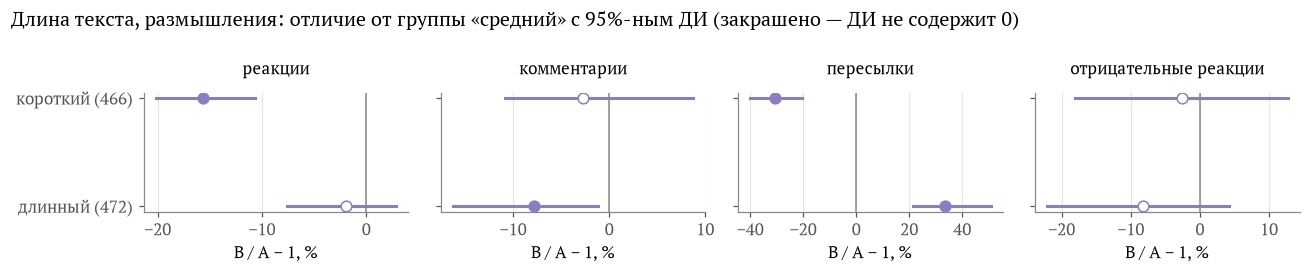

**Вопрос в тексте, размышления**

постов  медиана   ДИ медианы  \
метрика               группа                                      
реакции               нет вопроса     853    14.97  14.33–15.31   
                      есть вопрос     559    14.57  13.99–15.35   
комментарии           нет вопроса     601     1.13    1.09–1.19   
                      есть вопрос     392     1.52    1.40–1.66   
пересылки             нет вопроса     853     1.80    1.66–1.89   
                      есть вопрос     559     1.70    1.53–1.86   
отрицательные реакции нет вопроса     853     0.38    0.35–0.40   
                      есть вопрос     559     0.40    0.36–0.45   

                                                      вывод относительно A  \
метрика               группа                                                 
реакции               нет вопроса                         базовая группа A   
                      есть вопрос   различие не обнаружено (от −7% до +4%)   
комментарии           нет вопроса                         базовая группа A   
                      есть вопрос                         на 22–48% больше   
пересылки             нет вопроса                         базовая группа A   
                      есть вопрос  различие не обнаружено (от −16% до +8%)   
отрицательные реакции нет вопроса                         базовая группа A   
                      есть вопрос  различие не обнаружено (от −6% до +22%)   

                                  B / A − 1, % ДИ B / A − 1, %  
метрика               группа                                    
реакции               нет вопроса                               
                      есть вопрос           −3         −7 … +4  
комментарии           нет вопроса                               
                      есть вопрос          +35       +22 … +48  
пересылки             нет вопроса                               
                      есть вопрос           −5        −16 … +8  
отрицательные реакции нет вопроса                               
                      есть вопрос           +7        −6 … +22

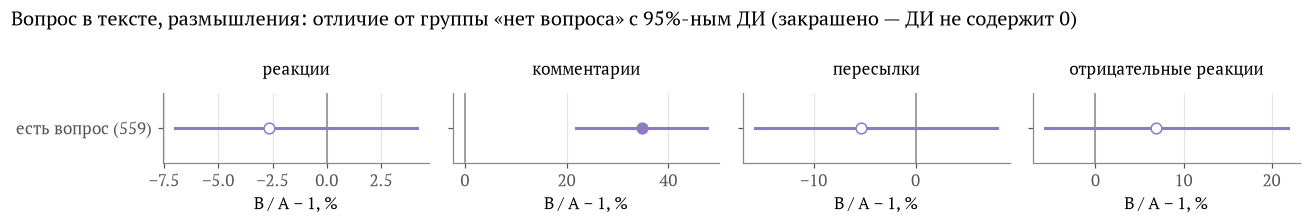

**Мат, размышления**

постов  медиана   ДИ медианы  \
метрика               группа                                   
реакции               без мата     618    13.61  13.15–14.14   
                      с матом      794    15.91  15.39–16.24   
комментарии           без мата     447     1.19    1.12–1.26   
                      с матом      546     1.27    1.23–1.36   
пересылки             без мата     618     1.44    1.34–1.57   
                      с матом      794     2.00    1.85–2.12   
отрицательные реакции без мата     618     0.35    0.32–0.39   
                      с матом      794     0.41    0.38–0.44   

                               вывод относительно A B / A − 1, %  \
метрика               группа                                       
реакции               без мата     базовая группа A                
                      с матом      на 11–22% больше          +17   
комментарии           без мата     базовая группа A                
                      с матом     на 0,5–15% больше           +7   
пересылки             без мата     базовая группа A                
                      с матом      на 24–52% больше          +39   
отрицательные реакции без мата     базовая группа A                
                      с матом       на 3–30% больше          +16   

                               ДИ B / A − 1, %  
метрика               группа                    
реакции               без мата                  
                      с матом        +11 … +22  
комментарии           без мата                  
                      с матом       +0,5 … +15  
пересылки             без мата                  
                      с матом        +24 … +52  
отрицательные реакции без мата                  
                      с матом         +3 … +30

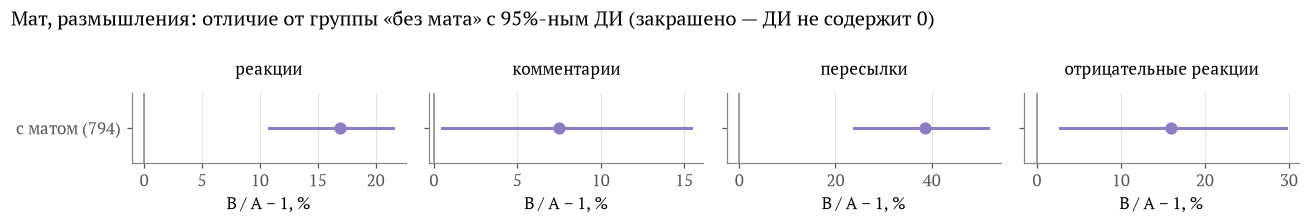

**Тема, размышления**

постов  медиана   ДИ медианы  \
метрика               группа                                                 
реакции               другое                     434    14.36  13.55–15.35   
                      деньги и цены              141    13.62  13.02–14.52   
                      дизайн                      40    15.27  12.88–16.51   
                      путешествия и страны       105    14.71  13.61–15.57   
                      еда                        201    15.15  14.19–16.44   
                      машины и дороги             54    16.03  14.15–19.25   
                      технологии и ИИ             69    13.33  12.23–15.76   
                      город                       83    14.74  13.84–17.05   
                      сервисы и обслуживание      43    15.10  13.56–17.02   
                      здоровье                    88    15.92  13.95–16.94   
                      несколько тем              154    15.40                
комментарии           другое                     302     1.25    1.18–1.36   
                      деньги и цены              103     1.10    1.02–1.26   
                      дизайн                      30     0.90    0.81–1.07   
                      путешествия и страны        78     1.18    1.08–1.39   
                      еда                        150     1.46    1.29–1.58   
                      машины и дороги             37     1.34    1.20–1.85   
                      технологии и ИИ             36     1.10    1.01–1.13   
                      город                       59     1.38    1.07–1.60   
                      сервисы и обслуживание      27     1.27                
                      здоровье                    55     1.29    1.21–1.50   
                      несколько тем              116     1.19                
пересылки             другое                     434     1.66    1.51–1.85   
                      деньги и цены              141     1.85    1.69–2.21   
                      дизайн                      40     1.86    1.56–2.77   
                      путешествия и страны       105     1.57    1.26–1.93   
                      еда                        201     2.12    1.87–2.40   
                      машины и дороги             54     1.48    1.01–2.04   
                      технологии и ИИ             69     1.19    1.05–1.40   
                      город                       83     1.45    1.20–1.73   
                      сервисы и обслуживание      43     1.51    0.96–2.36   
                      здоровье                    88     2.45    1.75–2.59   
                      несколько тем              154     2.04                
отрицательные реакции другое                     434     0.36    0.33–0.40   
                      деньги и цены              141     0.40    0.33–0.49   
                      дизайн                      40     0.32    0.28–0.39   
                      путешествия и страны       105     0.36    0.29–0.47   
                      еда                        201     0.47    0.41–0.51   
                      машины и дороги             54     0.43    0.34–0.65   
                      технологии и ИИ             69     0.36    0.30–0.55   
                      город                       83     0.38    0.31–0.47   
                      сервисы и обслуживание      43     0.30    0.21–0.38   
                      здоровье                    88     0.45    0.39–0.61   
                      несколько тем              154     0.33                

                                                                  вывод относительно A  \
метрика               группа                                                             
реакции               другое                                          базовая группа A   
                      деньги и цены            различие не обнаружено (от −13% до +4%)   
                      дизайн                  различие не обнаружено (от −10% до +19%)   
       

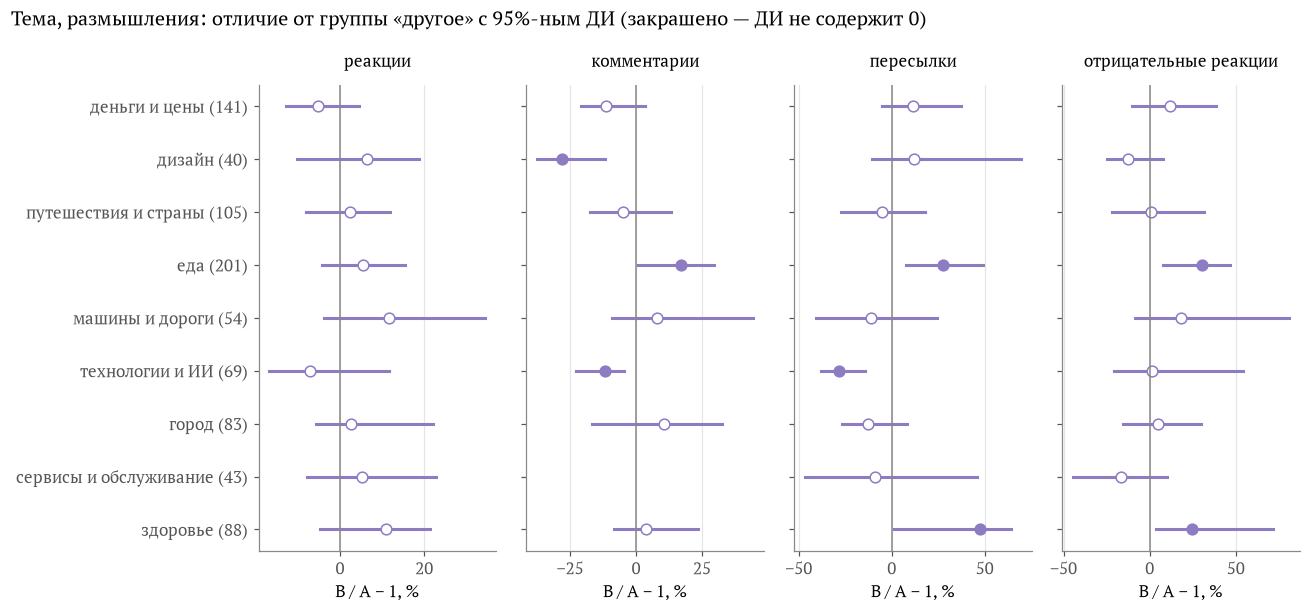

In [29]:
# 2.5–2.8. Признаки текста
show_compare(compare(refl, refl["text_len_bin"], "средний", ["короткий", "длинный"]), "Длина текста, размышления")
show_compare(compare(refl, np.where(refl["has_question"], "есть вопрос", "нет вопроса"), "нет вопроса",
                     ["есть вопрос"]), "Вопрос в тексте, размышления")
show_compare(compare(refl, np.where(refl["swear"], "с матом", "без мата"), "без мата", ["с матом"]),
             "Мат, размышления")
topics = [t for t in TOPICS] + ["несколько тем"]
show_compare(compare(refl, refl["topic"], "другое", topics,
                     skip={"несколько тем": "смесь тем, не сравнивается"}), "Тема, размышления")

#### Признаки текста

- **Длина.** Короткие размышления собирают на 11–20% меньше реакций и на 20–40% меньше пересылок, чем средние. Длинные пересылают на 21–51% чаще, чем средние, а комментируют на 1–16% реже. Реакции у длинных и средних размышлений не различаются.
- **Вопрос в тексте.** Размышления с вопросом комментируют на 22–48% чаще (медиана 1,52 против 1,13 на 1000 просмотров). С реакциями и пересылками вопрос не связан.
- **Мат.** Размышления с матом собирают на 11–22% больше реакций и на 24–52% больше пересылок, чем без мата. Отрицательных реакций у них тоже больше, на 3–30%, комментариев — на 0,5–15%. Связана ли эта разница с матом или с длиной текста, покажет модель, в которую входят оба признака.
- **Тема.** Реакции по темам не различаются. Посты о еде комментируют на 0,6–29% чаще и пересылают на 7–49% чаще, чем посты без темы, отрицательных реакций у них на 8–47% больше. Посты о здоровье пересылают на 1–64% чаще, отрицательных реакций у них на 4–72% больше. Посты о технологиях и ИИ комментируют на 5–23% реже и пересылают на 15–38% реже, посты о дизайне комментируют на 12–37% реже.

**Тип контента, все посты окна: обычный и блочный ДИ отношения B / A**

B / A − 1, %  \
метрика               группа                      
реакции               video                 −68   
                      other                 −16   
                      ad                    −50   
                      own_products          −59   
комментарии           video                 −56   
                      other                  −8   
                      ad                    −54   
                      own_products          −46   
пересылки             video                  −8   
                      other                  −5   
                      ad                    −53   
                      own_products          −17   
отрицательные реакции video                  +6   
                      other                 +83   
                      ad                   +377   
                      own_products          +37   

                                                                  обычный ДИ  \
метрика               группа                                                   
реакции               video                                 на 67–70% меньше   
                      other                                  на 7–25% меньше   
                      ad                                    на 45–53% меньше   
                      own_products                          на 46–62% меньше   
комментарии           video                                 на 52–58% меньше   
                      other         различие не обнаружено (от −19% до +17%)   
                      ad                                    на 48–61% меньше   
                      own_products                          на 33–59% меньше   
пересылки             video                                  на 1–13% меньше   
                      other         различие не обнаружено (от −23% до +12%)   
                      ad                                    на 44–63% меньше   
                      own_products  различие не обнаружено (от −29% до +13%)   
отрицательные реакции video          различие не обнаружено (от −9% до +17%)   
                      other                                на 54–136% больше   
                      ad                                  на 326–480% больше   
                      own_products                          на 11–83% больше   

                                                                  блочный ДИ  \
метрика               группа                                                   
реакции               video                                 на 67–70% меньше   
                      other                                  на 7–25% меньше   
                      ad                                    на 44–54% меньше   
                      own_products                          на 44–63% меньше   
комментарии           video                                 на 51–59% меньше   
                      other         различие не обнаружено (от −21% до +18%)   
                      ad                                    на 47–60% меньше   
                      own_products                          на 34–59% меньше   
пересылки             video                                  на 1–13% меньше   
                      other         различие не обнаружено (от −22% до +12%)   
                      ad                                    на 43–63% меньше   
                      own_products  различие не обнаружено (от −30% до +18%)   
отрицательные реакции video          различие не обнаружено (от −9% до +17%)   
                      other                                на 56–135% больше   
                      ad                                  на 319–490% больше   
                      own_products                           на 6–78% больше   

                                   вывод тот же  
метрика               группа                     
реакции               video                  да  
                      other                  да  
                      ad          

**Слот, все размышления: обычный и блочный ДИ отношения B / A**

B / A − 1, %  \
метрика               группа                
реакции               15:05           −11   
                      19:05          +1,0   
комментарии           15:05            +3   
                      19:05           +21   
пересылки             15:05           −31   
                      19:05           +10   
отрицательные реакции 15:05           +13   
                      19:05          +0,3   

                                                            обычный ДИ  \
метрика               группа                                             
реакции               15:05                            на 2–16% меньше   
                      19:05     различие не обнаружено (от −4% до +8%)   
комментарии           15:05    различие не обнаружено (от −7% до +15%)   
                      19:05                           на 11–37% больше   
пересылки             15:05                           на 21–41% меньше   
                      19:05    различие не обнаружено (от −5% до +22%)   
отрицательные реакции 15:05    различие не обнаружено (от −2% до +28%)   
                      19:05   различие не обнаружено (от −14% до +13%)   

                                                            блочный ДИ  \
метрика               группа                                             
реакции               15:05                            на 2–16% меньше   
                      19:05     различие не обнаружено (от −4% до +8%)   
комментарии           15:05    различие не обнаружено (от −7% до +16%)   
                      19:05                           на 12–36% больше   
пересылки             15:05                           на 20–41% меньше   
                      19:05    различие не обнаружено (от −4% до +22%)   
отрицательные реакции 15:05    различие не обнаружено (от −2% до +27%)   
                      19:05   различие не обнаружено (от −12% до +12%)   

                             вывод тот же  
метрика               группа               
реакции               15:05            да  
                      19:05            да  
комментарии           15:05            да  
                      19:05            да  
пересылки             15:05            да  
                      19:05            да  
отрицательные реакции 15:05            да  
                      19:05            да

**Слот, короткий: обычный и блочный ДИ отношения B / A**

...

**Слот, средний: обычный и блочный ДИ отношения B / A**

B / A − 1, %  \
метрика               группа                
реакции               15:05            −3   
                      19:05            +2   
комментарии           15:05           +10   
                      19:05           +32   
пересылки             15:05            −3   
                      19:05            −1   
отрицательные реакции 15:05            −8   
                      19:05           −13   

                                                            обычный ДИ  \
метрика               группа                                             
реакции               15:05    различие не обнаружено (от −13% до +7%)   
                      19:05    различие не обнаружено (от −8% до +10%)   
комментарии           15:05    различие не обнаружено (от −8% до +26%)   
                      19:05                           на 10–49% больше   
пересылки             15:05   различие не обнаружено (от −27% до +18%)   
                      19:05   различие не обнаружено (от −18% до +21%)   
отрицательные реакции 15:05   различие не обнаружено (от −28% до +23%)   
                      19:05   различие не обнаружено (от −33% до +10%)   

                                                            блочный ДИ  \
метрика               группа                                             
реакции               15:05    различие не обнаружено (от −13% до +8%)   
                      19:05    различие не обнаружено (от −9% до +12%)   
комментарии           15:05    различие не обнаружено (от −9% до +26%)   
                      19:05                           на 10–49% больше   
пересылки             15:05   различие не обнаружено (от −28% до +18%)   
                      19:05   различие не обнаружено (от −20% до +21%)   
отрицательные реакции 15:05   различие не обнаружено (от −28% до +22%)   
                      19:05    различие не обнаружено (от −32% до +7%)   

                             вывод тот же  
метрика               группа               
реакции               15:05            да  
                      19:05            да  
комментарии           15:05            да  
                      19:05            да  
пересылки             15:05            да  
                      19:05            да  
отрицательные реакции 15:05            да  
                      19:05            да

**Слот, длинный: обычный и блочный ДИ отношения B / A**

,,"B / A − 1, %",обычный ДИ,блочный ДИ,вывод тот же
метрика,группа,,,,
реакции,19:05,+4,различие не обнаружено (от −4% до +15%),различие не обнаружено (от −4% до +15%),да
комментарии,19:05,+17,на 7–36% больше,на 6–34% больше,да
пересылки,19:05,+3,различие не обнаружено (от −10% до +21%),различие не обнаружено (от −11% до +20%),да
отрицательные реакции,19:05,+4,различие не обнаружено (от −15% до +29%),различие не обнаружено (от −14% до +29%),да


Вывод изменился в 0 из 44 сравнений


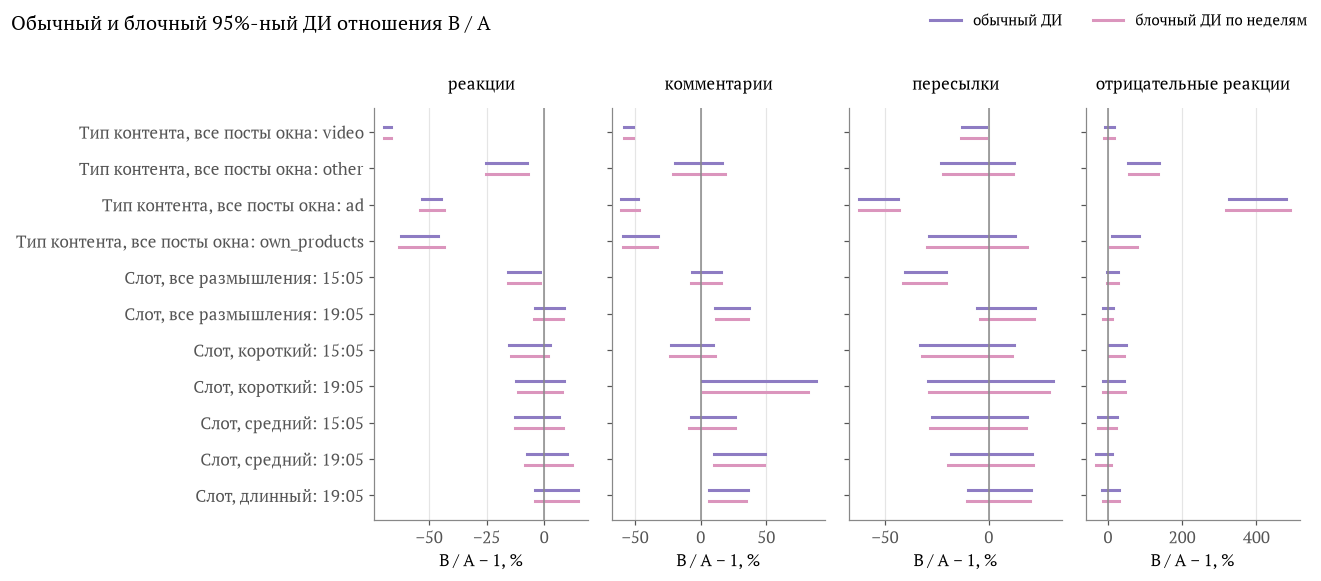

In [30]:
# Проверка устойчивости: блочный бутстрап по ISO-неделям для сравнений по типу контента и по слоту
def iso_week(df):
    iso = df["date_msc"].dt.isocalendar()
    return (iso["year"] * 100 + iso["week"]).to_numpy()


def add_block(res, df, labels):
    labels = pd.Series(labels, index=df.index).astype(str).to_numpy()
    weeks = iso_week(df)
    base = res.loc[res["вывод относительно A"] == "базовая группа A", "группа"].iat[0]
    rows = []
    for m_key, m in METRICS.items():
        ok = df[m_key].notna().to_numpy()
        vals = df[m_key].to_numpy(dtype=float)[ok]
        for _, r in res[(res["метрика"] == m) & res["ДИ B / A"].map(lambda c: isinstance(c, tuple))].iterrows():
            lo, hi = ci_ratio_block(vals, labels[ok], weeks[ok], base, r["группа"])
            rows.append({"метрика": m, "группа": r["группа"], "B / A − 1, %": pct((r["B / A"] - 1) * 100, True),
                         "обычный ДИ": verdict(*r["ДИ B / A"]), "блочный ДИ": verdict(lo, hi),
                         "вывод тот же": "да" if (r["ДИ B / A"][1] < 1 or r["ДИ B / A"][0] > 1) == (hi < 1 or lo > 1) else "нет",
                         "ДИ_блок": (lo, hi), "ДИ_обычный": r["ДИ B / A"]})
    return pd.DataFrame(rows)


block = {"Тип контента, все посты окна": add_block(res_content, posts, posts["content_type"])}
for b, res in res_slot.items():
    d = refl if b == "все размышления" else refl[refl["text_len_bin"] == b]
    block[f"Слот, {b}"] = add_block(res, d, d["slot"])

for title, t in block.items():
    display(Markdown(f"**{title}: обычный и блочный ДИ отношения B / A**"))
    with pd.option_context("display.max_colwidth", None):
        display(t.drop(columns=["ДИ_блок", "ДИ_обычный"]).set_index(["метрика", "группа"]))

all_block = pd.concat(block, names=["сравнение"]).reset_index(level=0)
changed = all_block[all_block["вывод тот же"] == "нет"]
print(f"Вывод изменился в {len(changed)} из {len(all_block)} сравнений")

# График: обычный и блочный ДИ рядом
fig, axes = plt.subplots(1, len(METRICS), figsize=(12, 0.32 * all_block.groupby(["сравнение", "группа"]).ngroups + 1.8),
                         sharey=True)
keys = list(dict.fromkeys(zip(all_block["сравнение"], all_block["группа"])))
y = np.arange(len(keys))
for ax, m in zip(axes, METRICS.values()):
    d = all_block[all_block["метрика"] == m].set_index(["сравнение", "группа"]).reindex(keys)
    for yi, (_, r) in zip(y, d.iterrows()):
        if not isinstance(r["ДИ_обычный"], tuple):
            continue
        for dy, ci, color in [(-0.15, r["ДИ_обычный"], PALETTE[0]), (0.15, r["ДИ_блок"], PALETTE[1])]:
            ax.plot([(ci[0] - 1) * 100, (ci[1] - 1) * 100], [yi + dy, yi + dy], color=color, lw=2)
    ax.axvline(0, color="#888888", lw=1)
    ax.set_title(m, fontsize=11, loc="center")
    ax.set_xlabel("B / A − 1, %")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y, [f"{c}: {g}" for c, g in keys])
axes[0].invert_yaxis()
handles = [plt.Line2D([], [], color=PALETTE[0], lw=2), plt.Line2D([], [], color=PALETTE[1], lw=2)]
fig.legend(handles, ["обычный ДИ", "блочный ДИ по неделям"], loc="upper right", ncol=2, fontsize=10)
fig.suptitle("Обычный и блочный 95%-ный ДИ отношения B / A", x=0.01, ha="left", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

#### Проверка устойчивости

Блочный бутстрап по неделям дал почти те же интервалы, что и обычный: вывод не изменился ни в одном из 44 сравнений. Значит, сходство постов одной недели на выводы о типе контента и времени публикации не влияет.

Сравнений в этом разделе много, поэтому часть различий может оказаться случайной, особенно те, у которых граница ДИ близка к нулю. Различия подтверждаются на следующем шаге, в модели с проверкой на последних 30% постов и поправкой Бенджамини–Хохберга.

### Итоги сравнений

Ниже различия, у которых ДИ узкий и далеко от нуля. Все они описывают связь признака с реакцией аудитории, причину сравнения не показывают. Различия подтвердим или опровергнем  на следующем шаге, в модели с проверкой на последних 30% постов.

1. **Больше всего реакций собирают размышления.** По сравнению с ними у видео реакций на 67–70% меньше и комментариев на 52–58% меньше, у рекламы реакций на 45–53% меньше и пересылок на 44–63% меньше. Отрицательных реакций у рекламы в 4,8 раза больше, чем у размышлений.
2. **Вопрос в тексте связан с комментариями.** Размышления с вопросом комментируют на 22–48% чаще, с реакциями и пересылками вопрос не связан.
3. **Мат связан с реакциями и пересылками.** Размышления с матом собирают на 11–22% больше реакций и на 24–52% больше пересылок. Отделить мат от длины текста предстоит в модели.
4. **Длина связана с пересылками.** Короткие размышления пересылают на 20–40% реже, чем средние, длинные — на 21–51% чаще. Реакций у коротких на 11–20% меньше, у средних и длинных их одинаково.
5. **Вечером больше комментариев.** В 19:05 размышления комментируют на 11–37% чаще, чем в 11:05, и разница сохраняется внутри каждой корзины длины.

**Где различий не обнаружено.** Реакции не различаются по дням недели, между буднями и выходными, по номеру поста за день и по темам. Отставание слота 15:05 по реакциям объясняется тем, что в 15:05 выходят более короткие тексты. Отставание по пересылкам среди размышлений одной длины меньше, и его ДИ содержит ноль.

**Устойчивость.** Блочный бутстрап по неделям не изменил вывод ни в одном из 44 сравнений типа контента и времени публикации.

*Сравнений много, поэтому различия с широким ДИ или с границей у нуля (темы, вторник, отрицательные реакции в 15:05, интервал больше 4,5 часа) в выводы не входят.*

## Модель

В сравнениях выше каждый признак рассматривался отдельно, хотя признаки связаны между собой. В 15:05 выходят более короткие тексты. Размышление, вышедшее первым постом дня, в 95% случаев опубликовано в 11:05, а третьим — в 74% случаев в 19:05 (таблица `post-num-slot`). Многомерная модель нужна, чтобы оценить связь каждого признака с метрикой при одинаковых значениях остальных признаков.

**Две модели.**
- Модель 1 — все посты окна. Признаки: `content_type` (базовое значение `reflection`) и квартал. Время публикации и признаки текста в модель 1 не входят, так как у видео и рекламы они означают другое, чем у размышлений.
- Модель 2 — размышления, опубликованные в 11:05, 15:05 или 19:05. Признаки и базовые значения:
  - `slot` — 11:05;
  - `text_len_bin` — средний;
  - `swear` — без мата;
  - `has_question` — нет вопроса;
  - выходной день — будни;
  - `topic` — «остальные посты». Тема, у которой на проверочной части меньше 30 размышлений, объединяется с «другое»; «несколько тем» тоже входит в «другое». Поэтому базовая группа включает посты без темы, посты с несколькими темами и посты мелких тем, и в результатах она называется «остальные посты». Правило задано до оценки модели и от метрик не зависит;
  - квартал.

Квартал в обеих моделях — контроль тренда, так как охват канала падал неравномерно. Квартал взят вместо месяца, так как месяцев в окне 24, и месячный контроль добавил бы 23 коэффициента. Коэффициенты квартала не проверяются и в поправку Бенджамини–Хохберга не входят.

Номер поста за день и интервал до предыдущего поста в модель 2 не входят, так как они связаны со слотом. Номер поста почти повторяет слот (таблица `post-num-slot`). Интервал до предыдущего поста тоже связан со слотом: перед размышлением в 11:05 предыдущий пост обычно выходит накануне в 19:05, а перед размышлениями в 15:05 и 19:05 — за 4 часа. У 90% размышлений в 11:05 интервал больше 4,5 ч, а у 79–89% размышлений в 15:05 и 19:05 он не больше 4,5 ч, поэтому влияние интервала и слота в модели трудно разделить (таблица `gap-slot`). `title_style`, `title_tone` и `ask_reader` не входят по причинам, описанным в разделе «Признаки, которые дальше не исследуются».

**Тип модели.** Отрицательная биномиальная регрессия (`statsmodels`, `NegativeBinomial`), параметр дисперсии alpha оценивается вместе с коэффициентами. Зависимые переменные — числа реакций, комментариев и пересылок, поэтому каждая из двух моделей оценивается отдельно для каждой метрики:
- `reactions_total` — бесплатные реакции;
- `replies` — комментарии. Посты платного периода и посты с выключенными комментариями в эту модель не входят. Платный период целиком попадает в обучающую часть, поэтому обучающая часть модели комментариев меньше, чем у остальных метрик. Число постов показывается отдельно для каждой метрики и каждой части;
- `forwards` — пересылки;
- `reactions_neg` — отрицательные реакции.

Отрицательная биномиальная регрессия подходит для неотрицательных целых чисел. Параметр alpha учитывает, что разброс чисел может быть больше, чем у пуассоновского распределения; при alpha = 0 модель совпадает с пуассоновской.

**Поправка на просмотры.** Просмотры входят в модель как экспозиция (`exposure = views`): к линейной части добавляется log(views) с коэффициентом 1. Поэтому модель описывает число реакций, комментариев или пересылок на один просмотр, так же как метрики на 1000 просмотров выше.

**Стандартные ошибки** кластеризованы по ISO-неделям (`cov_type="cluster"`), так как посты одной недели видит одна и та же аудитория и их метрики не независимы. Проверочная часть охватывает около 31 недели, поэтому кластеров на ней немного и ДИ на проверочной части менее точные, чем на обучающей.

**Эффект признака** — exp(β) − 1 в процентах. Он показывает, на сколько процентов метрика на просмотр у постов с этим значением признака больше или меньше, чем у постов с базовым значением, если остальные признаки одинаковые. 95%-ный ДИ эффекта — exp от границ 95%-ного ДИ β минус 1.

**Поиск и подтверждение эффектов.** Посты делятся по дате публикации. Граница — 70-й перцентиль дат размышлений модели 2, для модели 1 берётся та же дата. Посты до границы — обучающая часть, на ней ищутся эффекты; посты после — проверочная часть. Модель оценивается на каждой части отдельно, у каждой части свои кварталы.

Эффектов много, и часть из них окажется значимой случайно, поэтому эффект подтверждается в два шага:
1. На обучающей части p-значения всех проверяемых коэффициентов модели (все признаки × 4 метрики) пересчитываются в q-значения поправкой Бенджамини–Хохберга. Кандидаты — эффекты с q < 0,05.
2. На проверочной части проверяются только кандидаты. Их p-значения пересчитываются в q-значения поправкой Бенджамини–Хохберга по числу кандидатов. Эффект подтверждён, если на проверочной части у него тот же знак, что на обучающей, и q < 0,05.

Так ложный эффект должен случайно пройти проверку на двух разных периодах. Поправка делается отдельно для модели 1 и для модели 2.

**Проверка устойчивости.** Для реакций и пересылок, у которых нет нулевых значений, в обеих моделях та же зависимость оценивается методом наименьших квадратов (OLS) на логарифме метрики на 1000 просмотров, с теми же признаками и той же кластеризацией по неделям. Для каждого признака сравниваются знак эффекта и то, подтверждён ли эффект по тому же двухшаговому критерию, в основной модели и в OLS.

In [31]:
# Подготовка данных для моделей 1 и 2 (описание — в model-md)
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

COUNTS = {"reactions_per_1k": "reactions_total", "comments_per_1k": "replies",
          "forwards_per_1k": "forwards", "neg_per_1k": "reactions_neg"}

# Граница разбивки — 70-й перцентиль дат размышлений модели 2, та же дата для модели 1
cut = refl["date_msc"].quantile(0.7)
print(f"Граница разбивки: {cut:%Y-%m-%d %H:%M} МСК")

m1 = posts.copy()
m2 = refl.copy()
m2["выходной"] = m2["weekday"] >= 5

# Тема: темы, у которых на проверочной части меньше 30 размышлений, и «несколько тем» объединяются с «другое»
# в группу «остальные посты». Правило считает только размышления, метрики не использует.
test_topics = m2.loc[m2["date_msc"] > cut, "topic"].value_counts()
KEEP_TOPICS = [t for t in TOPICS if test_topics.get(t, 0) >= 30]
m2["тема"] = m2["topic"].where(m2["topic"].isin(KEEP_TOPICS), "остальные посты")

for d in (m1, m2):
    d["часть"] = np.where(d["date_msc"] <= cut, "обучающая", "проверочная")
    d["квартал"] = d["date_msc"].dt.tz_localize(None).dt.to_period("Q").astype(str)
    d["неделя"] = iso_week(d)

# Признаки и базовые значения; порядок значений — порядок в таблицах и на графиках
SPEC = {
    "модель 1": [("content_type", "reflection", ["video", "other", "ad", "own_products"])],
    "модель 2": [("slot", "11:05", ["15:05", "19:05"]),
                 ("text_len_bin", "средний", ["короткий", "длинный"]),
                 ("swear", False, [True]),
                 ("has_question", False, [True]),
                 ("выходной", False, [True]),
                 ("тема", "остальные посты", KEEP_TOPICS)],
}
DATA = {"модель 1": m1, "модель 2": m2}
FEATURE_LABELS = {"swear=True": "мат", "has_question=True": "есть вопрос", "выходной=True": "выходной",
                  "content_type=video": "видео", "content_type=other": "прочее", "content_type=ad": "реклама",
                  "content_type=own_products": "свои продукты", "slot=15:05": "15:05", "slot=19:05": "19:05",
                  "text_len_bin=короткий": "короткий текст", "text_len_bin=длинный": "длинный текст"}


def label(col, v):
    key = f"{col}={v}"
    return FEATURE_LABELS.get(key, f"{col}: {v}")


def metric_sample(d, m):
    """Посты, которые входят в модель метрики m: у комментариев — без платного периода и выключенных комментариев."""
    return d[d[m].notna()]


display(Markdown("**Размеры частей: число постов в модели каждой метрики**"))
sizes = pd.DataFrame({(model, part): {METRICS[m]: (metric_sample(d, m)["часть"] == part).sum() for m in METRICS}
                      for model, d in DATA.items() for part in ["обучающая", "проверочная"]})
display(sizes)

display(Markdown("**Модель 2: состав тем по частям (число размышлений)**"))
display(pd.crosstab(m2["тема"], m2["часть"]).loc[KEEP_TOPICS + ["остальные посты"]])
print("В «остальные посты» вошли: «другое», «несколько тем» и темы с < 30 размышлений на проверочной части: "
      + ", ".join(f"«{t}» ({test_topics.get(t, 0)})" for t in TOPICS if t not in KEEP_TOPICS))

Граница разбивки: 2026-02-27 16:41 МСК


**Размеры частей: число постов в модели каждой метрики**

модель 1              модель 2            
                      обучающая проверочная обучающая проверочная
реакции                    1635         644       988         424
комментарии                 974         644       569         424
пересылки                  1635         644       988         424
отрицательные реакции      1635         644       988         424

**Модель 2: состав тем по частям (число размышлений)**

часть,обучающая,проверочная
тема,,
деньги и цены,97,44
путешествия и страны,75,30
еда,138,63
город,52,31
здоровье,58,30
остальные посты,568,226


В «остальные посты» вошли: «другое», «несколько тем» и темы с < 30 размышлений на проверочной части: «дизайн» (11), «машины и дороги» (18), «технологии и ИИ» (11), «сервисы и обслуживание» (10)


In [32]:
# Отрицательная биномиальная регрессия и OLS для 4 метрик × 2 моделей × 2 частей
def design(d, spec):
    """Индикаторы значений признаков (без базового значения), кварталы части (без первого) и константа."""
    X = pd.DataFrame(index=d.index)
    for col, base, values in spec:
        for v in values:
            X[label(col, v)] = (d[col].astype(str) == str(v)).astype(float)
    quarters = sorted(d["квартал"].unique())
    for q in quarters[1:]:
        X[f"квартал {q}"] = (d["квартал"] == q).astype(float)
    assert (X.sum() > 0).all(), X.columns[X.sum() == 0].tolist()
    return sm.add_constant(X)


def tested(spec):
    return [label(col, v) for col, _, values in spec for v in values]


rows, problems, alphas = [], [], {}
for model, d in DATA.items():
    for m, count in COUNTS.items():
        for part in ["обучающая", "проверочная"]:
            s = metric_sample(d, m)
            s = s[s["часть"] == part]
            X = design(s, SPEC[model])
            groups = s["неделя"].to_numpy()
            # Метод BFGS: метод Ньютона на отрицательных реакциях и комментариях проверочной части
            # возвращает NaN, хотя сообщает, что сошёлся
            nb = sm.NegativeBinomial(s[count].to_numpy(), X, exposure=s["views"].to_numpy()).fit(
                method="bfgs", maxiter=5000, disp=0, cov_type="cluster", cov_kwds={"groups": groups})
            if not (nb.mle_retvals["converged"] and np.isfinite(nb.params).all() and np.isfinite(nb.bse).all()):
                problems.append(f"{model}, {METRICS[m]}, {part}: отрицательная биномиальная модель не сошлась")
            alphas[(model, part, METRICS[m])] = nb.params["alpha"]
            fits = [("NB", nb)]
            if m in ("reactions_per_1k", "forwards_per_1k"):
                assert (s[m] > 0).all()
                fits.append(("OLS", sm.OLS(np.log(s[m]), X).fit(cov_type="cluster", cov_kwds={"groups": groups})))
            for method, res in fits:
                ci = res.conf_int()
                for f in tested(SPEC[model]):
                    rows.append({"модель": model, "метод": method, "метрика": METRICS[m], "часть": part,
                                 "признак": f, "постов": len(s), "недель": len(np.unique(groups)),
                                 "β": res.params[f], "β_lo": ci.loc[f, 0], "β_hi": ci.loc[f, 1],
                                 "p": res.pvalues[f]})
fit_all = pd.DataFrame(rows)
print("\n".join(problems) if problems else "Все 16 отрицательных биномиальных моделей сошлись, оценки конечные")
display(Markdown("**Параметр дисперсии alpha** (0 — пуассоновская модель; чем больше, тем сильнее разброс)"))
display(pd.Series(alphas).unstack([0, 1]).round(2))

Все 16 отрицательных биномиальных моделей сошлись, оценки конечные


**Параметр дисперсии alpha** (0 — пуассоновская модель; чем больше, тем сильнее разброс)

модель 1              модель 2            
                      обучающая проверочная обучающая проверочная
комментарии                0.50        0.38      0.28        0.29
отрицательные реакции      1.65        1.00      1.92        1.00
пересылки                  0.59        0.47      0.51        0.43
реакции                    0.18        0.15      0.13        0.11

In [33]:
# Проверка alpha у отрицательных реакций: на проверочной части оценка 1,00 совпадает со стартовым значением,
# поэтому модель оценивается заново с разными начальными alpha. Если оценка от старта не зависит, она настоящая.
alpha_rows = []
for model, d in DATA.items():
    for part in ["обучающая", "проверочная"]:
        s = metric_sample(d, "neg_per_1k")
        s = s[s["часть"] == part]
        X = design(s, SPEC[model])
        y, expo = s["reactions_neg"].to_numpy(), s["views"].to_numpy()
        start = sm.Poisson(y, X, exposure=expo).fit(disp=0).params.to_numpy()
        for a0 in (0.3, 1.0, 3.0):
            res = sm.NegativeBinomial(y, X, exposure=expo).fit(start_params=np.append(start, a0), method="bfgs",
                                                                maxiter=5000, disp=0)
            alpha_rows.append({"модель": model, "часть": part, "старт alpha": a0, "alpha": res.params["alpha"],
                               "сошлась": res.mle_retvals["converged"]})
alpha_check = pd.DataFrame(alpha_rows)
display(Markdown("**Отрицательные реакции: оценка alpha при разных начальных значениях**"))
display(alpha_check.pivot_table(index=["модель", "часть"], columns="старт alpha", values="alpha").round(4))
print("Все модели сошлись" if alpha_check["сошлась"].all() else alpha_check[~alpha_check["сошлась"]])

**Отрицательные реакции: оценка alpha при разных начальных значениях**

старт alpha              0.3     1.0     3.0
модель   часть                              
модель 1 обучающая    1.6515  1.6515  1.6515
         проверочная  0.9994  0.9994  0.9994
модель 2 обучающая    1.9241  1.9242  1.9242
         проверочная  1.0002  1.0002  1.0002

Все модели сошлись


#### Проверка начального значения alpha

Оценка alpha не зависит от начального значения: при старте с 0,3, 1 и 3 модель сходится к одному и тому же числу. На проверочной части alpha равна **0,9994** в модели 1 и **1,000** в модели 2. Значит, совпадение с единицей случайное, а модель сошлась к настоящей оценке.

In [34]:
# Поправка Бенджамини–Хохберга и двухшаговый критерий подтверждения, отдельно для модели и метода
def confirm(r):
    tr = r[r["часть"] == "обучающая"].set_index(["метрика", "признак"])
    te = r[r["часть"] == "проверочная"].set_index(["метрика", "признак"])
    out = tr[["β", "β_lo", "β_hi", "p", "постов"]].join(
        te[["β", "β_lo", "β_hi", "p", "постов"]], rsuffix="_пров")
    out["q"] = multipletests(out["p"], method="fdr_bh")[1]
    out["кандидат"] = out["q"] < 0.05
    out["q_пров"] = np.nan
    if out["кандидат"].any():
        out.loc[out["кандидат"], "q_пров"] = multipletests(out.loc[out["кандидат"], "p_пров"], method="fdr_bh")[1]
    out["подтверждён"] = out["кандидат"] & (np.sign(out["β"]) == np.sign(out["β_пров"])) & (out["q_пров"] < 0.05)
    return out


conf = {(model, method): confirm(r) for (model, method), r in fit_all.groupby(["модель", "метод"])}


def fmt_q(x):
    if pd.isna(x):
        return "не кандидат"
    return "<0,001" if x < 0.001 else f"{x:.3f}".replace(".", ",")


def effect(b, lo, hi):
    e = lambda x: pct((np.exp(x) - 1) * 100, True)
    return f"{e(b)}% ({e(lo)} … {e(hi)})"


def ols_match(model, key, nb_row):
    if (model, "OLS") not in conf or key not in conf[(model, "OLS")].index:
        return "OLS не считался"
    o = conf[(model, "OLS")].loc[key]
    same_sign = np.sign(o["β"]) == np.sign(nb_row["β"])
    same_status = o["подтверждён"] == nb_row["подтверждён"]
    if same_sign and same_status:
        return "совпадает"
    return "не совпадает: " + ", ".join(x for x, bad in [("знак", not same_sign), ("подтверждение", not same_status)] if bad)


tables = {}
for model in DATA:
    c = conf[(model, "NB")]
    t = pd.DataFrame({
        "эффект, обучающая (95% ДИ)": [effect(*v) for v in c[["β", "β_lo", "β_hi"]].to_numpy()],
        "q, обучающая": c["q"].map(fmt_q),
        "эффект, проверочная (95% ДИ)": [effect(*v) for v in c[["β_пров", "β_lo_пров", "β_hi_пров"]].to_numpy()],
        "q, проверочная": c["q_пров"].map(fmt_q),
        "итог": np.where(c["подтверждён"], "подтверждён", "не подтверждён"),
        "OLS": [ols_match(model, k, c.loc[k]) for k in c.index],
    }, index=c.index)
    order = list(METRICS.values())
    t = t.reindex(sorted(t.index, key=lambda k: (order.index(k[0]), tested(SPEC[model]).index(k[1]))))
    tables[model] = t
    n = sizes[model]
    display(Markdown(f"**{model.capitalize()}: эффекты признаков** (постов в обучающей / проверочной части: "
                     + "; ".join(f"{m} — {n.loc[m, 'обучающая']} / {n.loc[m, 'проверочная']}" for m in n.index) + ")"))
    with pd.option_context("display.max_colwidth", None, "display.max_rows", 200):
        display(t)
    print(f"Кандидатов на обучающей части: {c['кандидат'].sum()} из {len(c)}, подтверждено: {c['подтверждён'].sum()}")

**Модель 1: эффекты признаков** (постов в обучающей / проверочной части: реакции — 1635 / 644; комментарии — 974 / 644; пересылки — 1635 / 644; отрицательные реакции — 1635 / 644)

эффект, обучающая (95% ДИ) q, обучающая  \
метрика               признак                                                 
реакции               видео                   −70% (−71 … −68)       <0,001   
                      прочее                 −10% (−19 … −0,4)        0,055   
                      реклама                 −54% (−58 … −50)       <0,001   
                      свои продукты           −50% (−61 … −35)       <0,001   
комментарии           видео                   −61% (−66 … −56)       <0,001   
                      прочее                   −8% (−25 … +12)        0,469   
                      реклама                 −57% (−64 … −48)       <0,001   
                      свои продукты           −60% (−71 … −44)       <0,001   
пересылки             видео                   −26% (−34 … −17)       <0,001   
                      прочее                   +1% (−16 … +21)        0,905   
                      реклама                 −54% (−61 … −46)       <0,001   
                      свои продукты           −11% (−40 … +32)        0,603   
отрицательные реакции видео                   −32% (−43 … −17)       <0,001   
                      прочее                +114% (+60 … +186)       <0,001   
                      реклама              +216% (+151 … +298)       <0,001   
                      свои продукты           −17% (−44 … +24)        0,452   

                                    эффект, проверочная (95% ДИ)  \
метрика               признак                                      
реакции               видео                     −68% (−72 … −64)   
                      прочее                     −8% (−26 … +14)   
                      реклама                    −19% (−30 … −7)   
                      свои продукты             −48% (−62 … −31)   
комментарии           видео                     −53% (−62 … −41)   
                      прочее                    +34% (−10 … +99)   
                      реклама                   −53% (−63 … −41)   
                      свои продукты             −30% (−40 … −18)   
пересылки             видео                     −23% (−31 … −15)   
                      прочее                    +11% (−20 … +56)   
                      реклама                   −39% (−54 … −19)   
                      свои продукты            +56% (−12 … +175)   
отрицательные реакции видео                      −6% (−36 … +40)   
                      прочее                  +166% (+67 … +324)   
                      реклама                  +97% (+38 … +181)   
                      свои продукты             −14% (−48 … +42)   

                                    q, проверочная            итог  \
метрика               признак                                        
реакции               видео                 <0,001     подтверждён   
                      прочее           не кандидат  не подтверждён   
                      реклама                0,004     подтверждён   
                      свои продукты         <0,001     подтверждён   
комментарии           видео                 <0,001     подтверждён   
                      прочее           не кандидат  не подтверждён   
                      реклама               <0,001     подтверждён   
                      свои продукты         <0,001     подтверждён   
пересылки             видео                 <0,001     подтверждён   
                      прочее           не кандидат  не подтверждён   
                      реклама               <0,001     подтверждён   
                      свои продукты    не кандидат  не подтверждён   
отрицательные реакции видео                  0,768  не подтверждён   
                      прочее                <0,001     подтверждён   
                      реклама               <0,001     подтверждён   
                      свои продукты    не кандидат  не подтверждён   

                                                             OLS  
метрика               признак                               

Кандидатов на обучающей части: 11 из 16, подтверждено: 10


**Модель 2: эффекты признаков** (постов в обучающей / проверочной части: реакции — 988 / 424; комментарии — 569 / 424; пересылки — 988 / 424; отрицательные реакции — 988 / 424)

эффект, обучающая (95% ДИ)  \
метрика               признак                                                 
реакции               15:05                                 −0,9% (−7 … +6)   
                      19:05                                −0,01% (−6 … +6)   
                      короткий текст                        −11% (−16 … −6)   
                      длинный текст                         +0,5% (−5 … +7)   
                      мат                                   +13% (+8 … +19)   
                      есть вопрос                           −5% (−9 … +0,4)   
                      выходной                                −3% (−9 … +2)   
                      тема: деньги и цены                    −4% (−12 … +5)   
                      тема: путешествия и страны             +4% (−7 … +16)   
                      тема: еда                              +4% (−2 … +11)   
                      тема: город                            +7% (−4 … +20)   
                      тема: здоровье                         +4% (−5 … +14)   
комментарии           15:05                                 −4% (−16 … +10)   
                      19:05                                +28% (+13 … +44)   
                      короткий текст                        +18% (+4 … +34)   
                      длинный текст                       −12% (−22 … +0,6)   
                      мат                                    +1% (−7 … +10)   
                      есть вопрос                          +46% (+32 … +63)   
                      выходной                               +8% (−6 … +25)   
                      тема: деньги и цены                   −4% (−21 … +18)   
                      тема: путешествия и страны            −2% (−23 … +25)   
                      тема: еда                           +12% (+0,3 … +26)   
                      тема: город                          +10% (−19 … +48)   
                      тема: здоровье                     +0,02% (−17 … +20)   
пересылки             15:05                               −14% (−26 … −1,0)   
                      19:05                                  −6% (−17 … +7)   
                      короткий текст                       −26% (−36 … −15)   
                      длинный текст                        +39% (+24 … +57)   
                      мат                                +10% (+0,02 … +22)   
                      есть вопрос                         −11% (−20 … −0,4)   
                      выходной                              −14% (−23 … −3)   
                      тема: деньги и цены                   +13% (−4 … +33)   
                      тема: путешествия и страны            −15% (−29 … +2)   
                      тема: еда                             +22% (+5 … +41)   
                      тема: город                           −20% (−33 … −4)   
                      тема: здоровье                        +10% (−9 … +33)   
отрицательные реакции 15:05                                 −5% (−32 … +31)   
                      19:05                                −12% (−34 … +16)   
                      короткий текст                      +82% (+31 … +151)   
                      длинный текст                         +29% (−2 … +71)   
                      мат                                   +43% (+8 … +89)   
                      есть вопрос                           −16% (−35 … +9)   
                      выходной                             +14% (−16 … +54)   
                      тема: деньги и цены                 +40% (−17 … +137)   
                      тема: путешествия и страны          +43% (−15 … +141)   
                      тема: еда                            +51% (+4 … +119)   
                      тема: город                           +6% (−41 … +90)   
                      тема: здоровье                      +49% (−10 … +147)   

                                                 q, обучающая  \
метрика               признак    

Кандидатов на обучающей части: 8 из 48, подтверждено: 4


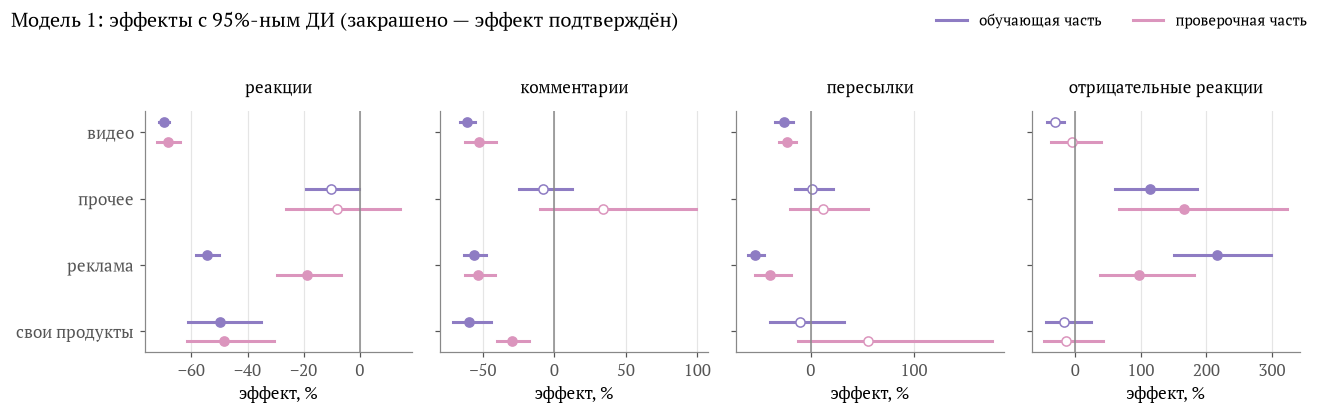

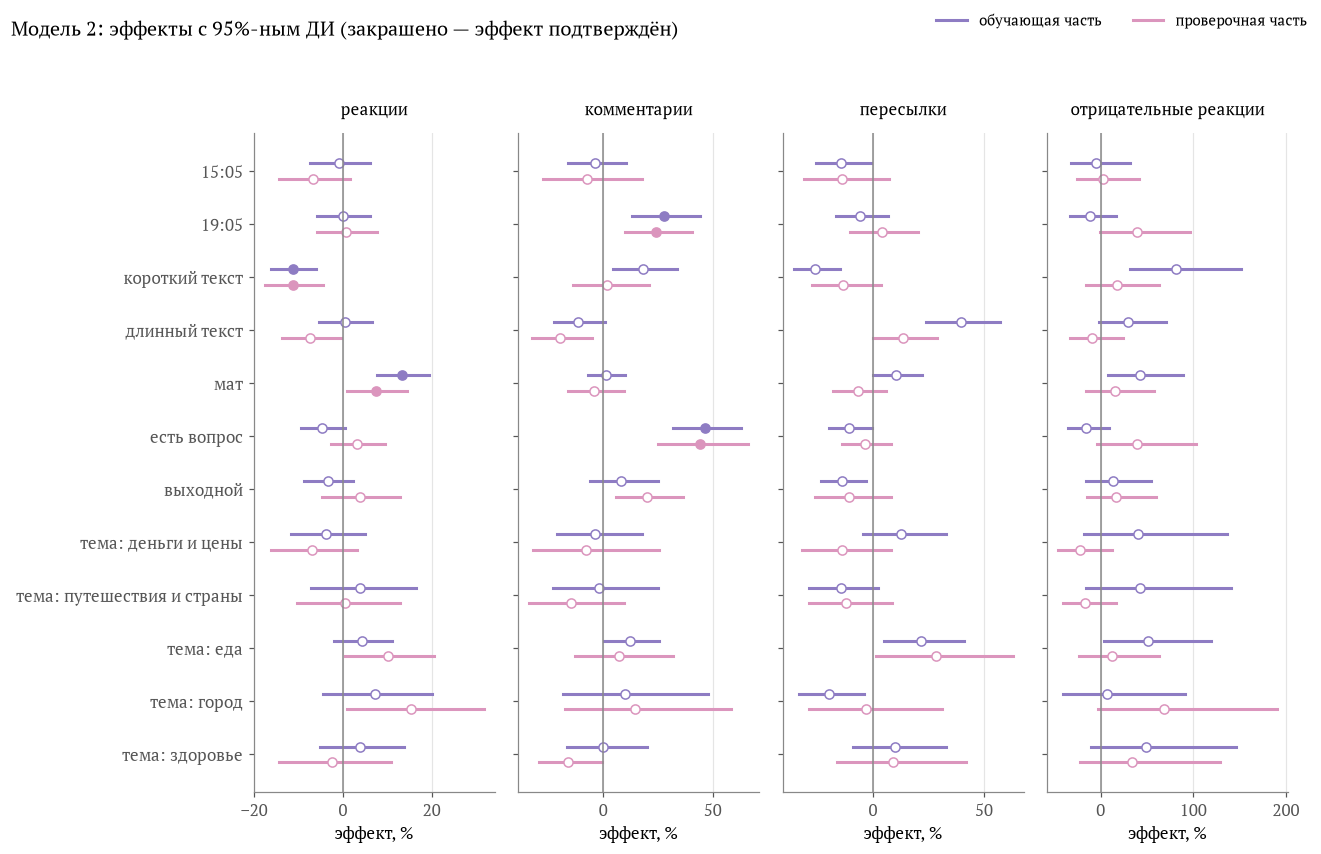

In [35]:
# Эффекты с 95%-ным ДИ на обучающей и проверочной частях
def plot_model(model):
    c = conf[(model, "NB")]
    feats = tested(SPEC[model])
    y = np.arange(len(feats))
    fig, axes = plt.subplots(1, len(METRICS), figsize=(12, 0.5 * len(feats) + 1.8), sharey=True)
    for ax, m in zip(axes, METRICS.values()):
        for yi, f in zip(y, feats):
            r = c.loc[(m, f)]
            for dy, sfx, color in [(-0.15, "", PALETTE[0]), (0.15, "_пров", PALETTE[1])]:
                lo, b, hi = [(np.exp(r[k + sfx]) - 1) * 100 for k in ("β_lo", "β", "β_hi")]
                ax.plot([lo, hi], [yi + dy, yi + dy], color=color, lw=2)
                ax.plot(b, yi + dy, "o", ms=6, color=color,
                        markerfacecolor=color if r["подтверждён"] else "white")
        ax.axvline(0, color="#888888", lw=1)
        ax.set_title(m, fontsize=11, loc="center")
        ax.set_xlabel("эффект, %")
        ax.grid(axis="y", visible=False)
    axes[0].set_yticks(y, feats)
    axes[0].invert_yaxis()
    handles = [plt.Line2D([], [], color=PALETTE[0], lw=2), plt.Line2D([], [], color=PALETTE[1], lw=2)]
    fig.legend(handles, ["обучающая часть", "проверочная часть"], loc="upper right", ncol=2, fontsize=10)
    fig.suptitle(f"{model.capitalize()}: эффекты с 95%-ным ДИ (закрашено — эффект подтверждён)",
                 x=0.01, ha="left", fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()


for model in DATA:
    plot_model(model)

In [36]:
# Сравнение с итогами бутстрапа (boot-summary): бутстрап сравнивает медианы по всему окну, признак за признаком;
# модель — среднее число на просмотр при одинаковых остальных признаках, на обучающей и проверочной частях
boot_text = {
    "длина": compare(refl, refl["text_len_bin"], "средний", ["короткий", "длинный"]),
    "вопрос": compare(refl, np.where(refl["has_question"], "есть вопрос", "нет вопроса"), "нет вопроса", ["есть вопрос"]),
    "мат": compare(refl, np.where(refl["swear"], "с матом", "без мата"), "без мата", ["с матом"]),
}


def boot_ci(res, metric, group):
    r = res[(res["метрика"] == metric) & (res["группа"] == group)].iloc[0]
    return f"{pct((r['ДИ B / A'][0] - 1) * 100, True)} … {pct((r['ДИ B / A'][1] - 1) * 100, True)}%"


CHECKS = [  # (что в boot-summary, модель, метрика, признак модели, результат бутстрапа)
    ("видео: реакции", "модель 1", "реакции", "видео", boot_ci(res_content, "реакции", "video")),
    ("видео: комментарии", "модель 1", "комментарии", "видео", boot_ci(res_content, "комментарии", "video")),
    ("реклама: реакции", "модель 1", "реакции", "реклама", boot_ci(res_content, "реакции", "ad")),
    ("реклама: пересылки", "модель 1", "пересылки", "реклама", boot_ci(res_content, "пересылки", "ad")),
    ("реклама: отрицательные реакции", "модель 1", "отрицательные реакции", "реклама",
     boot_ci(res_content, "отрицательные реакции", "ad")),
    ("вопрос: комментарии", "модель 2", "комментарии", "есть вопрос", boot_ci(boot_text["вопрос"], "комментарии", "есть вопрос")),
    ("мат: реакции", "модель 2", "реакции", "мат", boot_ci(boot_text["мат"], "реакции", "с матом")),
    ("мат: пересылки", "модель 2", "пересылки", "мат", boot_ci(boot_text["мат"], "пересылки", "с матом")),
    ("короткие: реакции", "модель 2", "реакции", "короткий текст", boot_ci(boot_text["длина"], "реакции", "короткий")),
    ("короткие: пересылки", "модель 2", "пересылки", "короткий текст", boot_ci(boot_text["длина"], "пересылки", "короткий")),
    ("длинные: пересылки", "модель 2", "пересылки", "длинный текст", boot_ci(boot_text["длина"], "пересылки", "длинный")),
    ("19:05: комментарии", "модель 2", "комментарии", "19:05",
     boot_ci(res_slot["все размышления"], "комментарии", "19:05")),
    ("15:05: реакции", "модель 2", "реакции", "15:05", boot_ci(res_slot["все размышления"], "реакции", "15:05")),
    ("15:05: пересылки", "модель 2", "пересылки", "15:05", boot_ci(res_slot["все размышления"], "пересылки", "15:05")),
]
vs = pd.DataFrame([{
    "различие из бутстрапа": name,
    "бутстрап, B / A − 1 (95% ДИ)": b,
    "модель, обучающая": tables[model].loc[(m, f), "эффект, обучающая (95% ДИ)"],
    "модель, проверочная": tables[model].loc[(m, f), "эффект, проверочная (95% ДИ)"],
    "итог модели": tables[model].loc[(m, f), "итог"],
} for name, model, m, f, b in CHECKS]).set_index("различие из бутстрапа")
display(Markdown("**Различия из итогов бутстрапа после учёта остальных признаков**"))
with pd.option_context("display.max_colwidth", None):
    display(vs)

# Мат и длина связаны: в длинных размышлениях мат встречается чаще, поэтому в бутстрапе их нельзя было разделить
display(Markdown("**Доля размышлений с матом по длине текста**"))
swear_len = pd.crosstab(m2["text_len_bin"], m2["swear"])
display((swear_len[True] / swear_len.sum(axis=1) * 100).round().astype(int).astype(str).add("%")
        .rename("с матом").to_frame().T)

**Различия из итогов бутстрапа после учёта остальных признаков**

,"бутстрап, B / A − 1 (95% ДИ)","модель, обучающая","модель, проверочная",итог модели
различие из бутстрапа,,,,
видео: реакции,−70 … −67%,−70% (−71 … −68),−68% (−72 … −64),подтверждён
видео: комментарии,−58 … −52%,−61% (−66 … −56),−53% (−62 … −41),подтверждён
реклама: реакции,−53 … −45%,−54% (−58 … −50),−19% (−30 … −7),подтверждён
реклама: пересылки,−63 … −44%,−54% (−61 … −46),−39% (−54 … −19),подтверждён
реклама: отрицательные реакции,+326 … +480%,+216% (+151 … +298),+97% (+38 … +181),подтверждён
вопрос: комментарии,+22 … +48%,+46% (+32 … +63),+44% (+25 … +66),подтверждён
мат: реакции,+11 … +22%,+13% (+8 … +19),"+8% (+0,9 … +15)",подтверждён
мат: пересылки,+24 … +52%,"+10% (+0,02 … +22)",−7% (−18 … +6),не подтверждён
короткие: реакции,−20 … −11%,−11% (−16 … −6),−11% (−18 … −4),подтверждён


**Доля размышлений с матом по длине текста**

text_len_bin,короткий,средний,длинный
с матом,34%,61%,73%


In [37]:
# Проверка устойчивости эффекта рекламы в модели 1: суперссылки — авторские тексты с рекламным блоком в конце.
# Двухшаговый критерий не пересчитывается, найденные эффекты остаются прежними.
ads = m1[m1["content_type"] == "ad"]
ad_parts = pd.crosstab(ads["ad_kind"], ads["часть"]).reindex(["native", "superlink", "unmarked"], fill_value=0)
ad_parts.loc["доля superlink"] = (ad_parts.loc["superlink"] / ad_parts.loc[["native", "superlink", "unmarked"]].sum()
                                  * 100).round().astype(int).astype(str) + "%"
display(Markdown(f"**Рекламные посты по `ad_kind` на частях модели** (граница {cut:%Y-%m-%d %H:%M} МСК)"))
display(ad_parts)

m1_nosl = m1[m1["ad_kind"] != "superlink"]
ad_rows = []
for name, d in [("исходная модель", m1), ("без superlink", m1_nosl)]:
    for m, count in COUNTS.items():
        for part in ["обучающая", "проверочная"]:
            s = metric_sample(d, m)
            s = s[s["часть"] == part]
            X = design(s, SPEC["модель 1"])
            res = sm.NegativeBinomial(s[count].to_numpy(), X, exposure=s["views"].to_numpy()).fit(
                method="bfgs", maxiter=5000, disp=0, cov_type="cluster", cov_kwds={"groups": s["неделя"].to_numpy()})
            assert res.mle_retvals["converged"] and np.isfinite(res.params).all() and np.isfinite(res.bse).all()
            lo, hi = res.conf_int().loc["реклама"]
            ad_rows.append({"метрика": METRICS[m], "модель": name, "часть": part,
                            "эффект (95% ДИ)": effect(res.params["реклама"], lo, hi),
                            "рекламы": int(X["реклама"].sum())})
ad_check = pd.DataFrame(ad_rows)
display(Markdown("**Эффект рекламы в модели 1, exp(β) − 1, с суперссылками и без них**"))
cols = pd.MultiIndex.from_product([["обучающая", "проверочная"], ["исходная модель", "без superlink"]])
with pd.option_context("display.max_colwidth", None):
    display(ad_check.pivot_table(index="метрика", columns=["часть", "модель"], values="эффект (95% ДИ)", aggfunc="first")
            .reindex(index=list(METRICS.values()), columns=cols))
display(Markdown("Число рекламных постов в модели"))
display(ad_check.pivot_table(index="метрика", columns=["часть", "модель"], values="рекламы", aggfunc="first")
        .reindex(index=list(METRICS.values()), columns=cols))

# Медианы реакций по всему окну; в superlink меньше 30 постов на каждой части, поэтому без ДИ
groups_sl = {"superlink": posts["ad_kind"] == "superlink", "native": posts["ad_kind"] == "native",
             "reflection": posts["content_type"] == "reflection"}
display(Markdown("**Реакции на 1000 просмотров по всему окну**"))
display(pd.DataFrame([{"группа": g, "постов": int(mask.sum()),
                       "медиана": round(posts.loc[mask, "reactions_per_1k"].median(), 1)}
                      for g, mask in groups_sl.items()]).set_index("группа"))


**Рекламные посты по `ad_kind` на частях модели** (граница 2026-02-27 16:41 МСК)

часть,обучающая,проверочная
ad_kind,,
native,139,33
superlink,26,8
unmarked,1,2
доля superlink,16%,19%


**Эффект рекламы в модели 1, exp(β) − 1, с суперссылками и без них**

обучающая                       \
                           исходная модель        без superlink   
метрика                                                           
реакции                   −54% (−58 … −50)     −57% (−61 … −52)   
комментарии               −57% (−64 … −48)     −63% (−70 … −56)   
пересылки                 −54% (−61 … −46)     −52% (−59 … −42)   
отрицательные реакции  +216% (+151 … +298)  +256% (+183 … +347)   

                             проверочная                      
                         исходная модель       без superlink  
метрика                                                       
реакции                  −19% (−30 … −7)   −16% (−29 … −0,2)  
комментарии             −53% (−63 … −41)    −55% (−66 … −41)  
пересылки               −39% (−54 … −19)     −33% (−51 … −8)  
отрицательные реакции  +97% (+38 … +181)  +123% (+57 … +216)

Число рекламных постов в модели

обучающая                   проверочная  \
                      исходная модель без superlink исходная модель   
метрика                                                               
реакции                           166           140              43   
комментарии                       118            98              43   
пересылки                         166           140              43   
отрицательные реакции             166           140              43   

                                     
                      без superlink  
метрика                              
реакции                          35  
комментарии                      35  
пересылки                        35  
отрицательные реакции            35

**Реакции на 1000 просмотров по всему окну**

,постов,медиана
группа,,
superlink,34,9.1
native,172,7.2
reflection,1424,14.8


In [38]:
# Проверка устойчивости эффекта 19:05 на комментарии: связан ли он с тем, что пост последний за день.
# Последний за день — следующий пост канала вышел больше чем через 8 часов. Порог задан заранее и не подбирается.
LAST_GAP_H = 8
assert m2["gap_next_h"].notna().all()
m2_last = m2.copy()
m2_last["последний"] = m2_last["gap_next_h"] > LAST_GAP_H
comm = metric_sample(m2_last, "comments_per_1k")


def last_share(d):
    g = d.groupby("slot", observed=True)["последний"]
    return pd.DataFrame({"размышлений": g.size(), "последних": g.sum(),
                         "доля последних": (g.mean() * 100).round().astype(int).astype(str) + "%"})


display(Markdown(f"**Доля размышлений, после которых следующий пост вышел больше чем через {LAST_GAP_H} ч**"))
display(pd.concat({"все размышления модели 2": last_share(m2_last),
                   **{f"модель комментариев, {part}": last_share(comm[comm["часть"] == part])
                      for part in ["обучающая", "проверочная"]}}, axis=1).T)

SPEC_LAST = SPEC["модель 2"] + [("последний", False, [True])]
last_rows = []
for name, spec in [("исходная модель", SPEC["модель 2"]), ("с признаком «последний за день»", SPEC_LAST)]:
    for part in ["обучающая", "проверочная"]:
        s = comm[comm["часть"] == part]
        X = design(s, spec)
        res = sm.NegativeBinomial(s["replies"].to_numpy(), X, exposure=s["views"].to_numpy()).fit(
            method="bfgs", maxiter=5000, disp=0, cov_type="cluster", cov_kwds={"groups": s["неделя"].to_numpy()})
        assert res.mle_retvals["converged"] and np.isfinite(res.params).all() and np.isfinite(res.bse).all()
        ci = res.conf_int()
        for f, f_name in [("19:05", "19:05"), ("последний: True", "последний за день")]:
            if f in X:
                last_rows.append({"признак": f_name, "модель": name, "часть": part, "постов": len(s),
                                  "эффект (95% ДИ)": effect(res.params[f], *ci.loc[f])})
last_check = pd.DataFrame(last_rows)
display(Markdown("**Комментарии, модель 2: эффект 19:05 и признака «последний за день», exp(β) − 1**"))
with pd.option_context("display.max_colwidth", None):
    display(last_check.pivot_table(index=["признак", "модель"], columns="часть", values="эффект (95% ДИ)",
                                   aggfunc="first").reindex([("19:05", "исходная модель"),
                                                             ("19:05", "с признаком «последний за день»"),
                                                             ("последний за день", "с признаком «последний за день»")]))
print("Постов в модели комментариев: " + ", ".join(
    f"{p} — {n}" for p, n in last_check.drop_duplicates("часть").set_index("часть")["постов"].items()))


**Доля размышлений, после которых следующий пост вышел больше чем через 8 ч**

slot                                            11:05 15:05 19:05
все размышления модели 2         размышлений      581   352   479
                                 последних          8    11   357
                                 доля последних    1%    3%   75%
модель комментариев, обучающая   размышлений      236   136   197
                                 последних          4     6   148
                                 доля последних    2%    4%   75%
модель комментариев, проверочная размышлений      171   117   136
                                 последних          3     0   102
                                 доля последних    2%    0%   75%

**Комментарии, модель 2: эффект 19:05 и признака «последний за день», exp(β) − 1**

часть                                                      обучающая  \
признак           модель                                               
19:05             исходная модель                   +28% (+13 … +44)   
                  с признаком «последний за день»    +13% (−4 … +33)   
последний за день с признаком «последний за день»  +17% (+0,9 … +35)   

часть                                                   проверочная  
признак           модель                                             
19:05             исходная модель                  +24% (+10 … +41)  
                  с признаком «последний за день»   +19% (−7 … +52)  
последний за день с признаком «последний за день»   +6% (−19 … +38)

Постов в модели комментариев: обучающая — 569, проверочная — 424


Доля постов с супер-ссылкой среди рекламы на обеих частях почти одинаковая (16% и 19%). Без них эффект рекламы почти не меняется: по реакциям −57% на обучающей части и −16% на проверочной против −54% и −19% в исходной модели. По медиане реакций посты с супер-ссылкой ближе к остальной рекламе (9,1 на 1000 просмотров против 7,2), чем к размышлениям (14,8). Значит, отнести их к рекламе было правильно, и вывод о рекламе от этого решения не зависит. Почему на проверочной части реклама отстаёт от размышлений по реакциям втрое меньше, чем на обучающей, эта проверка не объясняет.

### Итоги модели

Эффекты ниже — связь признака с метрикой на просмотр при одинаковых остальных признаках модели; причину они не показывают. Первое число — эффект на обучающей части (посты до 27 февраля 2026 года), в скобках — на проверочной.

**Подтверждённые эффекты.** **Модель 1**, сравнение с размышлениями того же квартала:
- видео: реакций на 70% меньше (68%), комментариев на 61% меньше (53%), пересылок на 26% меньше (23%);
- реклама: реакций на 54% меньше (19%), комментариев на 57% меньше (53%), пересылок на 54% меньше (39%), отрицательных реакций в 3,2 раза больше (в 2 раза). На проверочной части разница в реакциях у рекламы почти втрое меньше, чем на обучающей. Составом рекламы это не объясняется: без постов с супер-ссылкой эффект почти тот же (проверка `ad-superlink-check`);
- свои продукты: реакций на 50% меньше (48%), комментариев на 60% меньше (30%);
- прочие посты: отрицательных реакций в 2,1 раза больше (в 2,7 раза).

**Модель 2**, размышления, опубликованные в 11:05, 15:05 или 19:05:
- короткие размышления собирают на 11% меньше реакций, чем средние (11%);
- размышления, опубликованные в 19:05, комментируют на 28% чаще, чем опубликованные в 11:05 (24%);
- размышления с вопросом в тексте комментируют на 46% чаще, чем без вопроса (44%).

**Что не подтвердилось.**
- Мат и пересылки: в бутстрапе размышления с матом пересылали на 24–52% чаще, в модели эффект +10% (от +0,02% до +22%) и не прошёл поправку на обучающей части. Мат чаще встречается в длинных размышлениях (в 73% длинных против 34% коротких), а длинные размышления пересылают чаще, поэтому в бутстрапе мат и длину нельзя было разделить. После учёта длины связь мата с пересылками не подтверждается.
- Длина и пересылки: на обучающей части короткие размышления пересылают на 26% реже, а длинные на 39% чаще, чем средние, на проверочной части знак тот же (−13% и +14%), но q 0,154 и 0,077.
- Еда и пересылки: +22% (+28%), на обучающей части q = 0,052, поэтому на проверочной части эффект не проверялся.
- Слот 15:05: в бутстрапе реакций было на 2–16% меньше, чем в 11:05, в модели эффект −0,9% (от −7% до +6%). Когда длина текста и остальные признаки учтены, отставание 15:05 по реакциям не обнаруживается.
- Выходные, остальные темы и связь длины с комментариями и отрицательными реакциями не подтвердились.

**Проверка устойчивости.** Все подтверждённые эффекты по реакциям и пересылкам подтверждаются и в OLS, кроме пересылок у видео: в OLS эффект −7%, и он не прошёл поправку на обучающей части. Отрицательная биномиальная модель оценивает среднее число пересылок на просмотр, а OLS на логарифме — типичное значение, поэтому вывод о пересылках видео зависит от метода, и на него не опираемся.

Мат и реакции: +13% на обучающей части и +8% на проверочной, эффект прошёл двухшаговый критерий на самой границе (q = 0,0496), а в OLS не подтверждается (q = 0,092). Переход через порог произошёл, когда после исправления разметки два размышления длиной ровно 720 символов перешли из средних в длинные. Поэтому вывод зависит от метода и от двух постов, и на него не опираемся.

**Ограничения.**
- Мат, вопрос в тексте и тема размечены словарями и правилами. Ошибки разметки ослабляют эффекты, поэтому настоящие эффекты могут быть сильнее найденных.
- На проверочной части 424 размышления, поэтому слабые эффекты могут не подтвердиться, даже если они есть. Например, у еды и пересылок эффект +22% на обучающей части, но q = 0,052, и эффект не стал кандидатом.
- У тем «здоровье», «путешествия и страны» и «город» на проверочной части по 30–31 размышлению, их эффекты оценены неточно.
- В модели комментариев обучающая часть меньше (569 размышлений вместо 988), так как платный период целиком попал в неё.
- Признаки модели 2 выбраны после сравнения медиан по всему окну, включая проверочный период, а правило объединения тем считает размышления на проверочной части. Поэтому проверочная часть не полностью независима от выбора признаков. По этому правилу темы «технологии и ИИ» и «дизайн», у которых в сравнении медиан были различия, вошли в «остальные посты» и в модели отдельно не проверялись.
- Для эффектов модели 2 по комментариям (19:05 и вопрос в тексте) проверки OLS нет, так как у комментариев есть нулевые значения, а логарифм от нуля не определён.

## Выводы

В анализ вошли 2279 постов канала с 1 октября 2024 по 30 сентября 2026 года. Связь признаков с реакцией аудитории проверена двумя способами: сравнением медиан с bootstrap-ДИ по каждому признаку отдельно, и моделью, которая учитывает признаки одновременно и проверяет найденные эффекты на последних 30% постов. Далее представлены эффекты модели. Каждый эффект оценён на обучающей и на проверочной частях, диапазон — от меньшей до большей из двух оценок.

**С реакцией аудитории связаны:**
1. **Тип поста.** Больше всего реакций собирают размышления. У постов с видео реакций на 68–70% меньше, у рекламы на 19–54% меньше, у постов о своих продуктах на 48–50% меньше. Отрицательных реакций у рекламы в 2–3,2 раза больше, чем у размышлений. Посты с видео ведут на другие площадки, поэтому реакции на само видео здесь не отражаются.  

2. **Вопрос в тексте.** Размышления с вопросом комментируют на 44–46% чаще.  

3. **Время публикации.** Размышления, опубликованные в 19:05, комментируют на 24–28% чаще, чем опубликованные в 11:05. Связь времени с реакциями и пересылками не подтвердилась.  

4. **Длина текста.** Короткие размышления собирают на 11% меньше реакций, чем средние, на обеих частях.

**Связь не подтвердилась** у дня недели, выходных и тем постов. По отдельным метрикам различия есть на одной из частей (например, в выходные на проверочной части комментариев на 20% больше, посты о еде пересылают на 22% чаще, но на обучающей части q = 0,052, поэтому на проверочной части эффект не проверялся), но двухшаговую проверку они не прошли. Отставание слота 15:05 по реакциям в сравнениях медиан объясняется тем, что в 15:05 выходят более короткие тексты: после учёта длины оно пропадает (−0,9% в модели). Отставание по пересылкам после учёта длины меньше (−14% на обеих частях), но проверку не прошло. Связь мата с пересылками после учёта длины тоже пропадает, так как мат чаще встречается в длинных текстах. Связь мата с реакциями прошла критерий на самой границе (q = 0,0496), но в OLS не подтверждается, поэтому на неё не опираемся.

**Платные комментарии.** С 8 марта по 5 октября 2025 года, когда комментарии были платными, комментариев на 1000 просмотров было в 6,5 раза меньше, чем до введения платы (медиана 0,18 против 1,17), а реакций столько же (13,1 против 12,9). Читатели продолжали читать и реагировать, но перестали комментировать.

**Ограничения.**
- Эффекты описывают связь признака с реакцией аудитории, причину они не показывают.
- Мат, вопрос в тексте и тема размечены словарями и правилами, у разметки есть ошибки.
- На проверочной части 424 размышления, поэтому слабые эффекты могли не подтвердиться, даже если они есть.
- Признаки модели 2 выбраны после сравнения медиан по всему окну, включая проверочный период, а правило объединения тем считает размышления на проверочной части. Поэтому проверочная часть не полностью независима от выбора признаков. По этому правилу темы «технологии и ИИ» и «дизайн», у которых в сравнении медиан были различия, вошли в «остальные посты» и в модели отдельно не проверялись.
- Для эффектов модели 2 по комментариям (19:05 и вопрос в тексте) проверки OLS нет, так как у комментариев есть нулевые значения, а логарифм от нуля не определён.